# Notebook documenting Peru Uchannel Magnetostratigraphy

Santa Carina (SC) az strike/dip: 223/0  
SC lat/long: -3.356737, -71.786768  
Tamshiyacu (TAM) az strike/dip: 229/0    
TAM lat long: -4.011723, -73.153822  
GAD based on iquitos: (-)8.18° W  ± 0.32°  changing by  0.21° W per year using model WMMHR-2025 at 3.7619° S, 73.2628° W  

## Demag Groups

where left if the topmost section and right is lower depth

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8  

In [2]:
groups = {
    'Group 1': ['TAM 1', 'TAM 2', 'TAM 3B'],
    'Group 2': ['TAM 3A', 'TAM 4', 'TAM 5E', 'TAM 5D', 'TAM 5C'],
    'Group 3': ['TAM 5B', 'TAM 5A', 'TAM 6', 'TAM 7'],
    'Group 4': ['SC 1C', 'SC 1B', 'SC 1A', 'SC 2', 'SC 3C'],
    'Group 5': ['SC 3B', 'SC 3A', 'SC 4D', 'SC 4C', 'SC 4B', 'SC 4A'],
    'Group 6': ['SC 5', 'SC 6', 'SC 7C', 'SC 7B', 'SC 7A'],
    'Group 7': ['SC 8']
}

print("Groups defined:", ', '.join(groups.keys()))

Groups defined: Group 1, Group 2, Group 3, Group 4, Group 5, Group 6, Group 7


## Core Lengths


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# SC Data
SC_cores = ["SC 1C", "SC 1B", "SC 1A", "SC 2", "SC 3C", "SC 3B", "SC 3A", "SC 4D", "SC 4C", "SC 4B", 
            "SC 4A", "SC 5", "SC 6", "SC 7C", "SC 7B", "SC 7A", "SC 8"]
SC_lengths_cm = [18.5, 13, 8, 50, 34, 27.5, 20, 24, 16, 26.5, 22.5, 23, 50, 14, 13.5, 13, 50]
SC_foam_above = [1, 2.5, 4, 7.5, 1.2, 1.5, 3.6, 4.5, .25, 1.5, .5, 2.5, 3, 2, 1, 1.5, 15]
SC_foam_below = [1, 5, 4, 15.5, 3.5, 3, 2.5, 7, .5, 2, .25, 3.5, 2, 1.5, 1.5, 2, 8]

# Calculate SC Length Minus Foam
SC_length_minus_foam = [length - above - below for length, above, below in zip(SC_lengths_cm, SC_foam_above, SC_foam_below)]

# TAM Data
TAM_cores = ["TAM 1", "TAM 2", "TAM 3B", "TAM 3A", "TAM 4", "TAM 5E", "TAM 5D", "TAM 5C", "TAM 5B", 
             "TAM 5A", "TAM 6", "TAM 7"]
TAM_lengths_cm = [75, 50.5, 13.6, 36, 74, 12, 11, 10, 8.5, 7.8, 50, 49]
TAM_foam_above = [9, 12.3, 4.5, 0, 10, 2.5, 3, 1.5, 2.5, 2, 2.1, 1] 
TAM_foam_below = [9.2, 7.5, 0, 0, 7, 2.1, 2, 1.5, 2.3, 1.5, 2.5, .5]

# Calculate TAM Length Minus Foam
TAM_length_minus_foam = [length - above - below for length, above, below in zip(TAM_lengths_cm, TAM_foam_above, TAM_foam_below)]

# Create DataFrame for SC
df_SC = pd.DataFrame({
    "Core": SC_cores,
    "Length_cm": SC_lengths_cm,
    "Foam Above": SC_foam_above,
    "Foam Below": SC_foam_below,
    "Length Minus Foam": SC_length_minus_foam
})

# Create DataFrame for TAM
df_TAM = pd.DataFrame({
    "Core": TAM_cores,
    "Length_cm": TAM_lengths_cm,
    "Foam Above": TAM_foam_above,
    "Foam Below": TAM_foam_below,
    "Length Minus Foam": TAM_length_minus_foam
})

# Combine DataFrames for plotting
df_SC['Type'] = 'SC'
df_TAM['Type'] = 'TAM'

# Concatenate DataFrames
df_combined = pd.concat([df_SC, df_TAM], ignore_index=True)

print(df_combined)



      Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0    SC 1C       18.5        1.00        1.00              16.50   SC
1    SC 1B       13.0        2.50        5.00               5.50   SC
2    SC 1A        8.0        4.00        4.00               0.00   SC
3     SC 2       50.0        7.50       15.50              27.00   SC
4    SC 3C       34.0        1.20        3.50              29.30   SC
5    SC 3B       27.5        1.50        3.00              23.00   SC
6    SC 3A       20.0        3.60        2.50              13.90   SC
7    SC 4D       24.0        4.50        7.00              12.50   SC
8    SC 4C       16.0        0.25        0.50              15.25   SC
9    SC 4B       26.5        1.50        2.00              23.00   SC
10   SC 4A       22.5        0.50        0.25              21.75   SC
11    SC 5       23.0        2.50        3.50              17.00   SC
12    SC 6       50.0        3.00        2.00              45.00   SC
13   SC 7C       14.

### SC core lengths

In [4]:
print(df_SC)

     Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0   SC 1C       18.5        1.00        1.00              16.50   SC
1   SC 1B       13.0        2.50        5.00               5.50   SC
2   SC 1A        8.0        4.00        4.00               0.00   SC
3    SC 2       50.0        7.50       15.50              27.00   SC
4   SC 3C       34.0        1.20        3.50              29.30   SC
5   SC 3B       27.5        1.50        3.00              23.00   SC
6   SC 3A       20.0        3.60        2.50              13.90   SC
7   SC 4D       24.0        4.50        7.00              12.50   SC
8   SC 4C       16.0        0.25        0.50              15.25   SC
9   SC 4B       26.5        1.50        2.00              23.00   SC
10  SC 4A       22.5        0.50        0.25              21.75   SC
11   SC 5       23.0        2.50        3.50              17.00   SC
12   SC 6       50.0        3.00        2.00              45.00   SC
13  SC 7C       14.0        2.00  

### TAM core lengths

In [5]:
print(df_TAM)

      Core  Length_cm  Foam Above  Foam Below  Length Minus Foam Type
0    TAM 1       75.0         9.0         9.2               56.8  TAM
1    TAM 2       50.5        12.3         7.5               30.7  TAM
2   TAM 3B       13.6         4.5         0.0                9.1  TAM
3   TAM 3A       36.0         0.0         0.0               36.0  TAM
4    TAM 4       74.0        10.0         7.0               57.0  TAM
5   TAM 5E       12.0         2.5         2.1                7.4  TAM
6   TAM 5D       11.0         3.0         2.0                6.0  TAM
7   TAM 5C       10.0         1.5         1.5                7.0  TAM
8   TAM 5B        8.5         2.5         2.3                3.7  TAM
9   TAM 5A        7.8         2.0         1.5                4.3  TAM
10   TAM 6       50.0         2.1         2.5               45.4  TAM
11   TAM 7       49.0         1.0         0.5               47.5  TAM


### Total Lengths

In [6]:


# calculate totals per group using df_combined (includes SC + TAM)
rows = []
for gname, cores_list in groups.items():
    sel = df_combined[df_combined['Core'].isin(cores_list)]
    total_len = sel['Length_cm'].sum()
    total_minus = sel['Length Minus Foam'].sum()
    found = ', '.join(sel['Core'].tolist())
    missing = ', '.join([c for c in cores_list if c not in sel['Core'].values])
    rows.append({
        'Group': gname,
        'Total Length_cm (with foam)': total_len,
        'Total Length Minus Foam': total_minus,
        'Found cores': found,
        'Missing cores': missing
    })

df_group_totals = pd.DataFrame(rows)
print("Per-group totals (all groups):")
print(df_group_totals)

# absolute total of all cores in the notebook (SC + TAM) using df_combined
total_all_with = df_combined['Length_cm'].sum()
total_all_minus = df_combined['Length Minus Foam'].sum()
print("\nAbsolute total of all cores (with foam):", round(total_all_with, 2))
print("Absolute total of all cores (minus foam):", round(total_all_minus, 2))

Per-group totals (all groups):
     Group  Total Length_cm (with foam)  Total Length Minus Foam  \
0  Group 1                        139.1                     96.6   
1  Group 2                        143.0                    113.4   
2  Group 3                        115.3                    100.9   
3  Group 4                        123.5                     78.3   
4  Group 5                        136.5                    109.4   
5  Group 6                        113.5                     93.0   
6  Group 7                         50.0                     27.0   

                                Found cores Missing cores  
0                      TAM 1, TAM 2, TAM 3B                
1     TAM 3A, TAM 4, TAM 5E, TAM 5D, TAM 5C                
2              TAM 5B, TAM 5A, TAM 6, TAM 7                
3          SC 1C, SC 1B, SC 1A, SC 2, SC 3C                
4  SC 3B, SC 3A, SC 4D, SC 4C, SC 4B, SC 4A                
5           SC 5, SC 6, SC 7C, SC 7B, SC 7A                
6   

### Core Positions

In [7]:
# Calculate viable x-coordinates for each group
viable_positions = {}

for group_name, core_list in groups.items():
    # Get the cores for this group from df_combined
    group_cores = df_combined[df_combined['Core'].isin(core_list)].copy()
    
    # Sort cores in the order they appear in the group definition
    group_cores['order'] = group_cores['Core'].apply(lambda x: core_list.index(x))
    group_cores = group_cores.sort_values('order')
    
    # Calculate x positions
    x_start = 0
    ranges = []
    
    for idx, row in group_cores.iterrows():
        foam_above = row['Foam Above']
        foam_below = row['Foam Below']
        total_length = row['Length_cm']
        
        # Viable core starts after foam above
        viable_start = x_start + foam_above
        # Viable core ends before foam below
        viable_end = x_start + total_length - foam_below
        
        # Only add if there's viable core (start < end)
        if viable_start < viable_end:
            ranges.append([viable_start, viable_end])
        
        # Update x_start for next core
        x_start += total_length
    
    viable_positions[group_name] = ranges

# Display results
print("Viable x-coordinates for each group:\n")
for group_name in groups.keys():
    print(f"{group_name}:")
    for i, (start, end) in enumerate(viable_positions[group_name]):
        print(f"  x=[{start:.1f}, {end:.1f}]")
    print()

# Verify Group 1 matches your expected values
print("=" * 60)
print("Verification for Group 1:")
print("Expected: x=[9,65.8], x=[87.3,118], x=[130,139.1]")
print(f"Calculated: ", end="")
for start, end in viable_positions['Group 1']:
    print(f"x=[{start:.1f},{end:.1f}]", end=" ")
print()

Viable x-coordinates for each group:

Group 1:
  x=[9.0, 65.8]
  x=[87.3, 118.0]
  x=[130.0, 139.1]

Group 2:
  x=[0.0, 36.0]
  x=[46.0, 103.0]
  x=[112.5, 119.9]
  x=[125.0, 131.0]
  x=[134.5, 141.5]

Group 3:
  x=[2.5, 6.2]
  x=[10.5, 14.8]
  x=[18.4, 63.8]
  x=[67.3, 114.8]

Group 4:
  x=[1.0, 17.5]
  x=[21.0, 26.5]
  x=[47.0, 74.0]
  x=[90.7, 120.0]

Group 5:
  x=[1.5, 24.5]
  x=[31.1, 45.0]
  x=[52.0, 64.5]
  x=[71.8, 87.0]
  x=[89.0, 112.0]
  x=[114.5, 136.2]

Group 6:
  x=[2.5, 19.5]
  x=[26.0, 71.0]
  x=[75.0, 85.5]
  x=[88.0, 99.0]
  x=[102.0, 111.5]

Group 7:
  x=[15.0, 42.0]

Verification for Group 1:
Expected: x=[9,65.8], x=[87.3,118], x=[130,139.1]
Calculated: x=[9.0,65.8] x=[87.3,118.0] x=[130.0,139.1] 


Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

## Notes

### 1/19/26 - DEMAG

After NRM and AF 10 mT demag of Group 1 TAM_1_2_3B mostly lignite gave poor results and low intensity with a jumping inc and dec we decided to do coarse demag steps: 0, 10, 20, 25, 30, 35, 40, 50, 70, 90, 100 for the remaining groups. Steps are reduces to 5 mT near magnetite demag, with higher steps being for hematite. Geothite/greigite shoulder should make a V shape and should show a decrease in intensity with demagnetization followed by an upward jump between 30-60 mT.

12 steps AF demag
t = 240 mins /60 mins
t = 4 hrs

Group 1 NRM and 10 mT run are not promising. Samples are super weak and demag was stopped. Likely will finish Group 2 AF demag up to 100 mT today and start XRF tomorrow at 9am with Kara.

Group 2, which is demaging VERY nicely. Demag'd group 2 up to 40 mT and stopping to create a new protocol of the above steps. Demag up to 100 mT has been successful with some orthogonal plots showing vectors pointing to the origin!!!

Deepa will send a matlab script and walkthrough for data processing

data starts and ends together - ad hoc sign that sample has good behavior  
<B>possible 180 rotation in XY of sample TAM 5C</b>

Tomorrow check and impart ARM behavior after we do Group 3 demag (based on its behavior) and measure susceptibility of Group 2

<B>check for sulfides in XRF geotheite or griegite in section 110-125 cm of Group 2 - TAM 5E</b>  
normalized remnance increased starting 700 emu/70 mT

one of the data in group 2 seems to be rotated

### 1/20/26 - XRF

Today we are running Group 1 in the fine scale XRF Itrax Core Scanner using the following settings:  

Voltage: 30 Kv/55 mV  
10s scan per spot - for lighter elements up the time to 30s (Isaac typical time)  
3mm steps = 3000 um  
No xrays, we will use the CT scan for imagery instead  

This is the order of operations:
1. surface scan first to understand topography
2. Scan every 3mm  
    start: 117 mm, end: 678 mm  
    start: 898 mm, end: 1219 mm  
    start: 1322 mm, end: 1413 mm  

XRF is EDS i believe and will return counts which can then be calibrated on Clarie's XRF  
$40/hr * XXX hrs = COST  
Cost is also based on resolution  
Step size will be coarsest 3mm resolution for Group 1  

look here for estimated costs: /Users/nicolasanderson/Documents/GitHub/Peru/Anderson_CoreProcessingCostCalculator.xlsx  

Group 1 done  
Group 2 done  
Group 3 done  
Group 4  
Group 5 
Group 6  done
Group 7  done

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

better analyze XRF modelling software and correct


### 1/20/26 - DEMAG

Group 3 accidentally run at 50 mT on x axis, steps 0-50 skipped. Will rerun from NRM and proceed with AF demag as usual up to 100 mT. Intensity can likely be reconstruct4ed but inclinations are still near equatorial and declinations seem to be good. A possible reversal seen in core 7?

reconstruction can be madfe using coervivity and minerology - can be interpreted from XRF possibly

NRM and 100 mT results after potential 50 mT demag suggest that Y axis was demaged and not X. 

JOE: check IODP 202 site 1237   valparaiso to panama check if miocene sediments are present

link: https://iodp.tamu.edu/publications/202_IR/chap_08/chap_08.htm  
magnetic chrons C5B - C7  
220-300 m depth (mcd) is core 1237 is 15-25 Ma micoene  
chapter 8 - figure 38 = age model  depths calculated from this figure
figure 27 - NRM  
figure 29 - inclination  

Korte holocene record paper can be used to understand changes in geosecular variation between 2 location seperated at distance. - use signal processing to better understand

<B>side note: core 4 of Group 2 may have been run upside down with the top to the left. check data and flip if need be.</b>

<B>Plans for Thursday 1/22: </b>
Thursday CT scan  
coffin Prep after finishing NRM  
deepa takes samples to vet med  
start around 1030a  - Magruder Hall, 700 SW 30th St, Corvallis, OR 97331
no xrf overnight  

<B>tam 6 possible sulfides at 19 - 62 cm</b>

interesting periodicity in the intensity is not reflected in the directional data which would make it geomagnetic. this suggests a possible environmental effect. period seems jsut the results of seperate cuts FML
full width at half maximum is 7.5 cm that we are averaging over. 

something to note: are we confident there are no ash layers... maybe xrf can reveal. i think the predominant wind direction didnt allow ash preservation east of the andies but good preservation on the margin. also could have been nazca ridge erupting and not the andes

<B><U>ONE INCLINATION REVERSAL HAS BEEN FOUND IN MIDDLE OF GROUP 5 IN CORE 4B @ 90 CM!!</B></U>  
double check core has no issues  

more change seen in y relative to x. is this expected for new equatorial zones? 

running group 5 accidentally but doesnt matter  

Group 1 done  
Group 2 done  
Group 3 done  
Group 4  
Group 5 running now completed by EOD  
Group 6  
Group 7  

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

### 10/21/26 - DEMAG

yesterdays last 1000 mT step was good and data looks good and nearly totally demaged  
cleaned and did tray measurement  
starting with demag of Group 4 beginning of SC series. 

for 10 mT inc stating lower thn GAD at -8 and all inclinations are reversed polarity but degree of reversed-ness is changing - could be indicative of finding another reversal or the core is upside down lol GROUP 4!!!

put off data processing for tomorrow to complete most cores

Group 1, 2, 3, 5 are complete
Group 4 running now
Group 6 and 7 will finish today

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C 7B 7A  
Group 7: SC 8

look closely at group 4 SC 1C 1B 1A. what are the lithologies? can you explain the 90º south measurement> block rotated in box? broken pieces?  

11:36 am - Group 4 is over halfway done at 40 mT. heading out to eugene for the car swap at 1pm with expected return at 330p. 4 steps left
12:28 pm - doing last group 4 1000 mT run

12:57 pm group 4 complete  

starting Group 6 1:00 PM  


### 10/21/26 - SUSCEPTIBLITY

Typical 150cm run is 20 mins  
resolution of 1 cm  
measurement period = 5s over interval  
10 cm lead and tail  
typically do 3 runs and average for statistics but one run is enough for baseline  

Group 1 resistivity shows the lignite is potentially super paramagnetic??. Resistivity is 10-5 but intensity was on order of 10-6, 10-7. compare and confirm

Group 1 too long so has to be run as TAM 3B and TAM 2 together with TAM 1 run seperately  

Run order:  
1. TAM 3B 2  9:00 am
2. TAM 1  9:30 am
3. Group 2 9:45 am - TAM 3A
4. Group 3 10:15 am
5. TAM 3B 3A - mistake was made switching TAM 3B and 3A so they are being rerun again as a unit. Delete original 3B and 3A data and replace with this  11 am
6.  Group 4 - done on magnetometer - READY TO MEASURE 12:58 PM - measuring 1:02 PM - done
7.  Group 5 - on xrf @ 4:46 pm
8.  Group 6 - waiting for magnetometer first - on magnetometer 12:59 PM - measuring now 4:36 pm - done
9.  Group 6 SC7C is too fat for the susceptibility sensor hole, so we are running seperately. a gap was left in group 6 data where SC7C was. - done 5:20 pm
10.  Group 7 - waiting for magnetometer first - on magnetometer 4:46 pm

Group 1: TAM 1 2 3B  
Group 2: TAM 3A 4 5E 5D 5C  
Group 3: TAM 5B 5A 6 7  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C (fat) 7B 7A  
Group 7: SC 8


### 10/21/26 - XRF

Group 1, 2, 6 and 7 are complete  
Group 5 is running now - complete 1:00 PM  
Group 4 is done  
Group 3 is last - almost done  

Group 3: TAM 5B 5A 6 7
Group 4: SC 1C 1B 1A 2 3C  



## FINAL STEPS for Thursday 1/22/26

collect xrf raw data  

finish final demag group 7  
finish suscepability group 7  
try running SC7C tomorrow for suscepibility  

finish ct core prep  

data processing



### 10/22/26 - - gathering files and checking to ensure all runs were complete

all magnetometer and sus measurements are done. last run SC8 was measured rotated 90º clock wise. what does that mean for the data? dhould be about to determine from core SC7 to make inclinations align

lets check on isaac's last xrf run

also i really want ct scan so we may have to return on saturday to pick up samples. mailing will destory them

ALL GROUPS COMPLETE ON ALL SYSTEMS with samples packages for 2mm CT scans

chance that sample SC1A was run backwards in the XRf. chacking images to confirm



## Data Processing in Matlab

### cleaned data and generate ucheck files, uint, udir and export pca nd vgp plots
Group 1: TAM 1 2 3B - done  
Group 2: TAM 3A 4 5E 5D 5C - done    
Group 3: TAM 5B 5A 6 7  - done  
Group 4: SC 1C 1B 1A 2 3C  
Group 5: SC 3B 3A 4D 4C 4B 4A  
Group 6: SC 5 6 7C (fat) 7B 7A  
Group 7: SC 8

mad values < 5
linear pca


### Matlab data export

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os
from pathlib import Path

# Define the base directory
BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sample groups with their file identifiers
SAMPLE_GROUPS = {
    'Group_1_TAM_1_2_3B': 'TAM_1_2_3B_NRM_01192026',
    'Group_2_TAM_3A_4_5E_5D_5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group_3_TAM_5B_5A_6_7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group_4_SC_1C_1B_1A_2_3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group_5_SC_3B_3A_4D_4C_4B_4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group_6_SC_5_6_7C_7B_7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group_7_SC_8': 'SC_8_NRM_01212026'
}


def get_file_paths(sample_id):
    """
    Construct file paths for a given sample ID.
    """
    dir_file = os.path.join(BASE_DIR, 'dir', f'{sample_id}.NRM.dir')
    int_file = os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int')
    pca_file = os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt')
    vgp_file = os.path.join(BASE_DIR, 'dir', 'vgp', f'VGP - {sample_id}.txt')
    
    return {
        'dir': dir_file,
        'int': int_file,
        'pca': pca_file,
        'vgp': vgp_file
    }


def read_dir_file(filepath):
    """
    Read the .dir file and extract declination and inclination data.
    """
    if not os.path.exists(filepath):
        print(f"Warning: DIR file not found: {filepath}")
        return None
    
    data = []
    with open(filepath, 'r') as f:
        lines = f.readlines()
        
    # Find where data starts
    data_start = 0
    for i, line in enumerate(lines):
        if 'POSITION' in line and 'TREAT' in line:
            data_start = i + 2
            break
    
    # Parse data lines
    for line in lines[data_start:]:
        if line.strip():
            parts = line.split()
            if len(parts) >= 7:
                try:
                    position = float(parts[0])
                    treat = int(parts[1])
                    j = float(parts[4])
                    dec = float(parts[5])
                    inc = float(parts[6])
                    data.append({
                        'position': position,
                        'treatment': treat,
                        'intensity': j,
                        'dec': dec,
                        'inc': inc
                    })
                except ValueError:
                    continue
    
    return pd.DataFrame(data) if data else None


def read_int_file(filepath):
    """
    Read the .int file which contains intensity measurements.
    """
    if not os.path.exists(filepath):
        print(f"Warning: INT file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None


def read_pca_file(filepath):
    """
    Read the PCA file which contains MAD values.
    """
    if not os.path.exists(filepath):
        print(f"Warning: PCA file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None


def read_vgp_file(filepath):
    """
    Read the VGP file which contains Virtual Geomagnetic Pole positions.
    """
    if not os.path.exists(filepath):
        print(f"Warning: VGP file not found: {filepath}")
        return None
    
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        return df
    except Exception as e:
        print(f"Error reading VGP file: {e}")
        return None


def plot_inc_dec(pca_df, ax, group_name):
    """
    Plot Inclination and Declination on the same plot with dual y-axes.
    """
    ax2 = ax.twinx()
    
    # Plot inclination on left y-axis
    line1 = ax.plot(pca_df['position'], pca_df['Incl'], 
                    'b-o', markersize=3, linewidth=1.5, label='Inclination')
    ax.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Inclination (°)', fontsize=11, fontweight='bold', color='b')
    ax.tick_params(axis='y', labelcolor='b')
    ax.grid(True, alpha=0.3)
    
    # Plot declination on right y-axis
    line2 = ax2.plot(pca_df['position'], pca_df['Decl'], 
                     'r-s', markersize=3, linewidth=1.5, label='Declination')
    ax2.set_ylabel('Declination (°)', fontsize=11, fontweight='bold', color='r')
    ax2.tick_params(axis='y', labelcolor='r')
    
    # Add title
    ax.set_title(f'Inclination and Declination vs Position\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=10)
    
    # Add legend
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', framealpha=0.9, fontsize=9)
    
    # Set reasonable y-limits
    ax.set_ylim([-90, 90])
    ax2.set_ylim([0, 360])
    
    return ax


def plot_mad_intensity(pca_df, int_df, ax, group_name):
    """
    Plot MAD and Intensity (300 mT) on the same plot with dual y-axes.
    """
    ax2 = ax.twinx()
    
    # Plot MAD on left y-axis
    line1 = ax.plot(pca_df['position'], pca_df['MAD'], 
                    'g-o', markersize=3, linewidth=1.5, label='MAD')
    ax.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax.set_ylabel('MAD (°)', fontsize=11, fontweight='bold', color='g')
    ax.tick_params(axis='y', labelcolor='g')
    ax.grid(True, alpha=0.3)
    
    # Plot Intensity at 300 mT on right y-axis
    if int_df is not None and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        line2 = ax2.plot(int_df['position'], int_300, 
                        'm-^', markersize=3, linewidth=1.5, label='Intensity (300 mT)')
        ax2.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11, fontweight='bold', color='m')
        ax2.tick_params(axis='y', labelcolor='m')
        ax2.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    # Add title
    ax.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=10)
    
    # Add legend
    lines = line1 + line2 if int_df is not None else line1
    labels = [l.get_label() for l in lines]
    ax.legend(lines, labels, loc='upper right', framealpha=0.9, fontsize=9)
    
    return ax


def plot_vgp_mollweide(vgp_df, ax, group_name):
    """
    Plot VGP positions on a Mollweide projection map.
    """
    # Create the projection using matplotlib's built-in Mollweide
    ax = plt.subplot(ax.get_subplotspec(), projection='mollweide')
    
    # Get VGP data
    positions = vgp_df['Position(cm)'].values
    vgp_lons = vgp_df['VGP_Long.'].values
    vgp_lats = vgp_df['VGP_Lat.'].values
    
    # Convert to radians for mollweide projection
    vgp_lons_rad = np.deg2rad(vgp_lons)
    vgp_lats_rad = np.deg2rad(vgp_lats)
    
    # Create a scatter plot with color gradient
    scatter = ax.scatter(vgp_lons_rad, vgp_lats_rad, 
                        c=positions, cmap='viridis', 
                        s=40, alpha=0.7, 
                        edgecolors='black', linewidth=0.5,
                        zorder=5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='horizontal', 
                       pad=0.08, shrink=0.8)
    cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    
    # Mark the site location
    site_lon = vgp_df['Site_Long.'].iloc[0]
    site_lat = vgp_df['Site_Lat.'].iloc[0]
    site_lon_rad = np.deg2rad(site_lon)
    site_lat_rad = np.deg2rad(site_lat)
    ax.plot(site_lon_rad, site_lat_rad, 'r*', markersize=18, 
           label=f'Site ({site_lat:.2f}°, {site_lon:.2f}°)',
           zorder=10, markeredgecolor='white', markeredgewidth=1.5)
    
    # Set labels
    ax.set_xlabel('Longitude', fontsize=10, fontweight='bold')
    ax.set_ylabel('Latitude', fontsize=10, fontweight='bold')
    
    # Add title
    ax.set_title(f'Virtual Geomagnetic Pole (VGP) Positions\n{group_name}', 
                 fontsize=12, fontweight='bold', pad=15)
    
    # Add legend
    ax.legend(loc='lower left', fontsize=8, framealpha=0.9)
    
    return ax


def process_sample_group(group_name, sample_id, output_dir='paleomag_plots'):
    """
    Process a single sample group and generate all plots.
    """
    print(f"\n{'='*60}")
    print(f"Processing: {group_name}")
    print(f"Sample ID: {sample_id}")
    print(f"{'='*60}")
    
    # Get file paths
    file_paths = get_file_paths(sample_id)
    
    # Read all data files
    pca_df = read_pca_file(file_paths['pca'])
    int_df = read_int_file(file_paths['int'])
    vgp_df = read_vgp_file(file_paths['vgp'])
    
    # Check if we have the minimum required data
    if pca_df is None:
        print(f"ERROR: Cannot process {group_name} - PCA file missing or invalid")
        return False
    
    if vgp_df is None:
        print(f"ERROR: Cannot process {group_name} - VGP file missing or invalid")
        return False
    
    print(f"PCA data: {len(pca_df)} points")
    if int_df is not None:
        print(f"Intensity data: {len(int_df)} points")
    print(f"VGP data: {len(vgp_df)} points")
    
    # Create figure with three subplots
    fig = plt.figure(figsize=(16, 12))
    gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.2], hspace=0.35)
    
    # Plot 1: Inc and Dec
    ax1 = fig.add_subplot(gs[0])
    plot_inc_dec(pca_df, ax1, group_name)
    
    # Plot 2: MAD and Intensity
    ax2 = fig.add_subplot(gs[1])
    plot_mad_intensity(pca_df, int_df, ax2, group_name)
    
    # Plot 3: VGP Mollweide
    ax3 = fig.add_subplot(gs[2])
    plot_vgp_mollweide(vgp_df, ax3, group_name)
    
    # Add overall title
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    # Adjust layout
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    
    # Create output directory if it doesn't exist
    os.makedirs(output_dir, exist_ok=True)
    
    # Save figure
    safe_name = group_name.replace(' ', '_').replace(':', '')
    output_file = os.path.join(output_dir, f'{safe_name}.png')
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"\nPlot saved to: {output_file}")
    
    # Also save as PDF
    output_pdf = os.path.join(output_dir, f'{safe_name}.pdf')
    plt.savefig(output_pdf, bbox_inches='tight')
    print(f"Plot saved to: {output_pdf}")
    
    plt.close(fig)
    
    # Print statistics
    print("\n=== Data Statistics ===")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    print(f"VGP Latitude range: {vgp_df['VGP_Lat.'].min():.2f}° to {vgp_df['VGP_Lat.'].max():.2f}°")
    print(f"VGP Longitude range: {vgp_df['VGP_Long.'].min():.2f}° to {vgp_df['VGP_Long.'].max():.2f}°")
    
    return True


def main():
    """
    Main function to process all sample groups.
    """
    print("="*60)
    print("BATCH PALEOMAGNETIC DATA VISUALIZATION")
    print("="*60)
    
    output_dir = 'paleomag_plots'
    successful = []
    failed = []
    
    # Process each sample group
    for group_name, sample_id in SAMPLE_GROUPS.items():
        try:
            success = process_sample_group(group_name, sample_id, output_dir)
            if success:
                successful.append(group_name)
            else:
                failed.append(group_name)
        except Exception as e:
            print(f"\nERROR processing {group_name}: {str(e)}")
            failed.append(group_name)
    
    # Print summary
    print("\n" + "="*60)
    print("PROCESSING SUMMARY")
    print("="*60)
    print(f"\nSuccessfully processed: {len(successful)}/{len(SAMPLE_GROUPS)} groups")
    if successful:
        print("\nSuccessful groups:")
        for group in successful:
            print(f"  ✓ {group}")
    
    if failed:
        print("\nFailed groups:")
        for group in failed:
            print(f"  ✗ {group}")
    
    print(f"\nAll plots saved to: {os.path.abspath(output_dir)}/")
    print("\nBatch processing complete!")


if __name__ == "__main__":
    main()

BATCH PALEOMAGNETIC DATA VISUALIZATION

Processing: Group_1_TAM_1_2_3B
Sample ID: TAM_1_2_3B_NRM_01192026
ERROR: Cannot process Group_1_TAM_1_2_3B - PCA file missing or invalid

Processing: Group_2_TAM_3A_4_5E_5D_5C
Sample ID: TAM_3A_4_5E_5D_5C_NRM_01192026
PCA data: 144 points
Intensity data: 144 points
VGP data: 144 points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1415547207.py:315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])



Plot saved to: paleomag_plots/Group_2_TAM_3A_4_5E_5D_5C.png
Plot saved to: paleomag_plots/Group_2_TAM_3A_4_5E_5D_5C.pdf

=== Data Statistics ===
Inclination range: -80.27° to 36.40°
Declination range: 3.12° to 349.59°
MAD range: 3.71° to 38.51°
Mean MAD: 14.50° (±8.02°)
VGP Latitude range: -33.48° to 76.13°
VGP Longitude range: -173.20° to 179.73°

Processing: Group_3_TAM_5B_5A_6_7
Sample ID: TAM_5B_5A_6_7_NRM_01202026
ERROR: Cannot process Group_3_TAM_5B_5A_6_7 - PCA file missing or invalid

Processing: Group_4_SC_1C_1B_1A_2_3C
Sample ID: SC_1C_1B_1A_2_3C_NRM_01212026
PCA data: 126 points
Intensity data: 126 points
VGP data: 126 points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1415547207.py:315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])



Plot saved to: paleomag_plots/Group_4_SC_1C_1B_1A_2_3C.png
Plot saved to: paleomag_plots/Group_4_SC_1C_1B_1A_2_3C.pdf

=== Data Statistics ===
Inclination range: -88.69° to -16.59°
Declination range: 2.85° to 359.46°
MAD range: 2.96° to 31.37°
Mean MAD: 13.35° (±6.00°)
VGP Latitude range: -69.98° to 66.40°
VGP Longitude range: -179.98° to 179.28°

Processing: Group_5_SC_3B_3A_4D_4C_4B_4A
Sample ID: SE_3B_3A_4D_4C_4B_4A_NRM_01202026
PCA data: 139 points
Intensity data: 139 points
VGP data: 139 points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1415547207.py:315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])



Plot saved to: paleomag_plots/Group_5_SC_3B_3A_4D_4C_4B_4A.png
Plot saved to: paleomag_plots/Group_5_SC_3B_3A_4D_4C_4B_4A.pdf

=== Data Statistics ===
Inclination range: -43.34° to 21.07°
Declination range: 83.54° to 287.00°
MAD range: 2.37° to 35.19°
Mean MAD: 7.71° (±4.91°)
VGP Latitude range: -54.23° to 14.89°
VGP Longitude range: -155.48° to 45.48°

Processing: Group_6_SC_5_6_7C_7B_7A
Sample ID: SC_5_6_7C_7B_7A_NRM_01212026
PCA data: 117 points
Intensity data: 117 points
VGP data: 117 points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1415547207.py:315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])



Plot saved to: paleomag_plots/Group_6_SC_5_6_7C_7B_7A.png
Plot saved to: paleomag_plots/Group_6_SC_5_6_7C_7B_7A.pdf

=== Data Statistics ===
Inclination range: -21.64° to 7.58°
Declination range: 0.07° to 358.53°
MAD range: 2.22° to 20.03°
Mean MAD: 7.35° (±3.22°)
VGP Latitude range: -10.91° to 86.41°
VGP Longitude range: -173.60° to 23.83°

Processing: Group_7_SC_8
Sample ID: SC_8_NRM_01212026
PCA data: 51 points
Intensity data: 51 points
VGP data: 51 points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1415547207.py:315: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])



Plot saved to: paleomag_plots/Group_7_SC_8.png
Plot saved to: paleomag_plots/Group_7_SC_8.pdf

=== Data Statistics ===
Inclination range: -53.44° to 81.93°
Declination range: 3.85° to 343.70°
MAD range: 0.49° to 44.33°
Mean MAD: 17.13° (±11.53°)
VGP Latitude range: -81.59° to 85.33°
VGP Longitude range: -171.12° to 155.28°

PROCESSING SUMMARY

Successfully processed: 5/7 groups

Successful groups:
  ✓ Group_2_TAM_3A_4_5E_5D_5C
  ✓ Group_4_SC_1C_1B_1A_2_3C
  ✓ Group_5_SC_3B_3A_4D_4C_4B_4A
  ✓ Group_6_SC_5_6_7C_7B_7A
  ✓ Group_7_SC_8

Failed groups:
  ✗ Group_1_TAM_1_2_3B
  ✗ Group_3_TAM_5B_5A_6_7

All plots saved to: /Users/nicolasanderson/Documents/GitHub/Peru/paleomag_plots/

Batch processing complete!


In [21]:
"""
Paleomagnetic Data Visualization for Jupyter Notebook
Simply copy and paste this into your notebook cells
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION - Update these paths to match your system
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sample groups
SAMPLE_GROUPS = {
    'Group 1: TAM 1 2 3B': 'TAM_1_2_3B_NRM_01192026',
    'Group 2: TAM 3A 4 5E 5D 5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group 3: TAM 5B 5A 6 7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group 4: SC 1C 1B 1A 2 3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group 6: SC 5 6 7C 7B 7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group 7: SC 8': 'SC_8_NRM_01212026'
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
        'vgp': os.path.join(BASE_DIR, 'dir', 'vgp', f'VGP - {sample_id}.txt')
    }

def read_pca_file(filepath):
    """Read PCA file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position(cm)' in df.columns:
        df = df.rename(columns={'Position(cm)': 'position'})
    return df

def read_int_file(filepath):
    """Read intensity file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position' in df.columns:
        df = df.rename(columns={'Position': 'position'})
    return df

def read_vgp_file(filepath):
    """Read VGP file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    return df

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_paleomag_data(group_name, sample_id):
    """
    Generate all 3 plots for a sample group.
    
    Parameters:
    -----------
    group_name : str
        Name of the group for plot titles
    sample_id : str
        Sample identifier for finding files
    """
    
    # Get file paths
    paths = get_file_paths(sample_id)
    
    # Read data
    try:
        pca_df = read_pca_file(paths['pca'])
        int_df = read_int_file(paths['int'])
        vgp_df = read_vgp_file(paths['vgp'])
    except Exception as e:
        print(f"Error reading files for {group_name}: {e}")
        return
    
    # Create figure
    fig = plt.figure(figsize=(16, 12))
    gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.2], hspace=0.35)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Inclination (left y-axis)
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=3, 
             linewidth=1.5, label='Inclination')
    ax1.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=11, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    # Declination (right y-axis)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=3,
                   linewidth=1.5, label='Declination')
    ax1_right.set_ylabel('Declination (°)', fontsize=11, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    ax1.set_title(f'Inclination and Declination vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # MAD (left y-axis)
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=3,
             linewidth=1.5, label='MAD')
    ax2.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=11, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Intensity at 300 mT (right y-axis)
    if 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=3,
                       linewidth=1.5, label='Intensity (300 mT)')
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 3: VGP Mollweide Projection
    # ========================================================================
    ax3 = plt.subplot(gs[2], projection='mollweide')
    
    # Get VGP data
    positions = vgp_df['Position(cm)'].values
    vgp_lons = np.deg2rad(vgp_df['VGP_Long.'].values)
    vgp_lats = np.deg2rad(vgp_df['VGP_Lat.'].values)
    
    # Plot VGPs
    scatter = ax3.scatter(vgp_lons, vgp_lats, c=positions, cmap='viridis',
                         s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                         zorder=5)
    
    # Colorbar
    cbar = plt.colorbar(scatter, ax=ax3, orientation='horizontal',
                       pad=0.08, shrink=0.8)
    cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')
    
    # Site location
    site_lon = np.deg2rad(vgp_df['Site_Long.'].iloc[0])
    site_lat = np.deg2rad(vgp_df['Site_Lat.'].iloc[0])
    ax3.plot(site_lon, site_lat, 'r*', markersize=18, zorder=10,
            markeredgecolor='white', markeredgewidth=1.5,
            label=f'Site ({np.rad2deg(site_lat):.2f}°, {np.rad2deg(site_lon):.2f}°)')
    
    ax3.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
    ax3.set_xlabel('Longitude', fontsize=10, fontweight='bold')
    ax3.set_ylabel('Latitude', fontsize=10, fontweight='bold')
    ax3.set_title(f'Virtual Geomagnetic Pole (VGP) Positions\n{group_name}',
                 fontsize=12, fontweight='bold', pad=15)
    ax3.legend(loc='lower left', fontsize=8, framealpha=0.9)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*60}")
    print(f"Statistics for {group_name}")
    print(f"{'='*60}")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    print(f"VGP Lat range: {vgp_df['VGP_Lat.'].min():.2f}° to {vgp_df['VGP_Lat.'].max():.2f}°")
    print(f"VGP Lon range: {vgp_df['VGP_Long.'].min():.2f}° to {vgp_df['VGP_Long.'].max():.2f}°")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Example 1: Plot a single group
# plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')

# Example 2: Plot all groups
# for group_name, sample_id in SAMPLE_GROUPS.items():
#     plot_paleomag_data(group_name, sample_id)

# Example 3: Plot specific groups
# plot_paleomag_data('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026')
# plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')

### best working multiplot generator

In [28]:
import numpy as np
import pandas as pd
from matplotlib import gridspec
import os

"""
Paleomagnetic Data Visualization for Jupyter Notebook - Modified for Group 1
Simply copy and paste this into your notebook cells
"""

import matplotlib.pyplot as plt

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION - Update these paths to match your system
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sample groups
SAMPLE_GROUPS = {
    'Group 1: TAM 1 2 3B': 'TAM_1_2_3B_NRM_01192026',
    'Group 2: TAM 3A 4 5E 5D 5C': 'TAM_3A_4_5E_5D_5C_NRM_01192026',
    'Group 3: TAM 5B 5A 6 7': 'TAM_5B_5A_6_7_NRM_01202026',
    'Group 4: SC 1C 1B 1A 2 3C': 'SC_1C_1B_1A_2_3C_NRM_01212026',
    'Group 5: SC 3B 3A 4D 4C 4B 4A': 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026',
    'Group 6: SC 5 6 7C 7B 7A': 'SC_5_6_7C_7B_7A_NRM_01212026',
    'Group 7: SC 8': 'SC_8_NRM_01212026'
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
        'vgp': os.path.join(BASE_DIR, 'dir', 'vgp', f'VGP - {sample_id}.txt')
    }

def read_pca_file(filepath):
    """Read PCA file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position(cm)' in df.columns:
        df = df.rename(columns={'Position(cm)': 'position'})
    return df

def read_int_file(filepath):
    """Read intensity file."""
    df = pd.read_csv(filepath, sep='\t')
    df.columns = df.columns.str.strip()
    if 'Position' in df.columns:
        df = df.rename(columns={'Position': 'position'})
    return df

def read_vgp_file(filepath):
    """Read VGP file."""
    if not os.path.exists(filepath):
        return None
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        return df
    except:
        return None

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_paleomag_data(group_name, sample_id):
    """
    Generate plots for a sample group.
    For Group 1, skip VGP plot (insufficient data points).
    
    Parameters:
    -----------
    group_name : str
        Name of the group for plot titles
    sample_id : str
        Sample identifier for finding files
    """
    
    # Get file paths
    paths = get_file_paths(sample_id)
    
    # Read data
    try:
        pca_df = read_pca_file(paths['pca'])
        int_df = read_int_file(paths['int'])
        vgp_df = read_vgp_file(paths['vgp'])
    except Exception as e:
        print(f"Error reading files for {group_name}: {e}")
        return
    
    # Check if this is Group 1 (skip VGP plot)
    skip_vgp = 'Group 1' in group_name or vgp_df is None or len(vgp_df) < 5
    
    if skip_vgp:
        # Create figure with only 2 subplots
        fig = plt.figure(figsize=(16, 8))
        gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.35)
        num_plots = 2
    else:
        # Create figure with 3 subplots
        fig = plt.figure(figsize=(16, 12))
        gs = gridspec.GridSpec(3, 1, height_ratios=[1, 1, 1.2], hspace=0.35)
        num_plots = 3
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Inclination (left y-axis)
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=3, 
             linewidth=1.5, label='Inclination')
    ax1.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=11, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    # Declination (right y-axis)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=3,
                   linewidth=1.5, label='Declination')
    ax1_right.set_ylabel('Declination (°)', fontsize=11, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    ax1.set_title(f'Inclination and Declination vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # MAD (left y-axis)
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=3,
             linewidth=1.5, label='MAD')
    ax2.set_xlabel('Position (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=11, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Intensity at 300 mT (right y-axis)
    if 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=3,
                       linewidth=1.5, label='Intensity (300 mT)')
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=11, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_title(f'MAD and Intensity (300 mT) vs Position\n{group_name}', 
                  fontsize=12, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9)
    
    # ========================================================================
    # PLOT 3: VGP Mollweide Projection (skip for Group 1)
    # ========================================================================
    if not skip_vgp:
        ax3 = plt.subplot(gs[2], projection='mollweide')
        
        # Get VGP data
        positions = vgp_df['Position(cm)'].values
        vgp_lons = np.deg2rad(vgp_df['VGP_Long.'].values)
        vgp_lats = np.deg2rad(vgp_df['VGP_Lat.'].values)
        
        # Plot VGPs
        scatter = ax3.scatter(vgp_lons, vgp_lats, c=positions, cmap='viridis',
                             s=40, alpha=0.7, edgecolors='black', linewidth=0.5,
                             zorder=5)
        
        # Colorbar
        cbar = plt.colorbar(scatter, ax=ax3, orientation='horizontal',
                           pad=0.08, shrink=0.8)
        cbar.set_label('Position (cm)', fontsize=9, fontweight='bold')
        
        # Site location
        site_lon = np.deg2rad(vgp_df['Site_Long.'].iloc[0])
        site_lat = np.deg2rad(vgp_df['Site_Lat.'].iloc[0])
        ax3.plot(site_lon, site_lat, 'r*', markersize=18, zorder=10,
                markeredgecolor='white', markeredgewidth=1.5,
                label=f'Site ({np.rad2deg(site_lat):.2f}°, {np.rad2deg(site_lon):.2f}°)')
        
        ax3.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
        ax3.set_xlabel('Longitude', fontsize=10, fontweight='bold')
        ax3.set_ylabel('Latitude', fontsize=10, fontweight='bold')
        ax3.set_title(f'Virtual Geomagnetic Pole (VGP) Positions\n{group_name}',
                     fontsize=12, fontweight='bold', pad=15)
        ax3.legend(loc='lower left', fontsize=8, framealpha=0.9)
    else:
        print(f"Note: VGP plot skipped for {group_name} (insufficient data points)")
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Paleomagnetic Analysis: {group_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*60}")
    print(f"Statistics for {group_name}")
    print(f"{'='*60}")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    if not skip_vgp:
        print(f"VGP Lat range: {vgp_df['VGP_Lat.'].min():.2f}° to {vgp_df['VGP_Lat.'].max():.2f}°")
        print(f"VGP Lon range: {vgp_df['VGP_Long.'].min():.2f}° to {vgp_df['VGP_Long.'].max():.2f}°")

### plot all group inc, dec, mad, intensity and vgp

Note: VGP plot skipped for Group 1: TAM 1 2 3B (insufficient data points)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


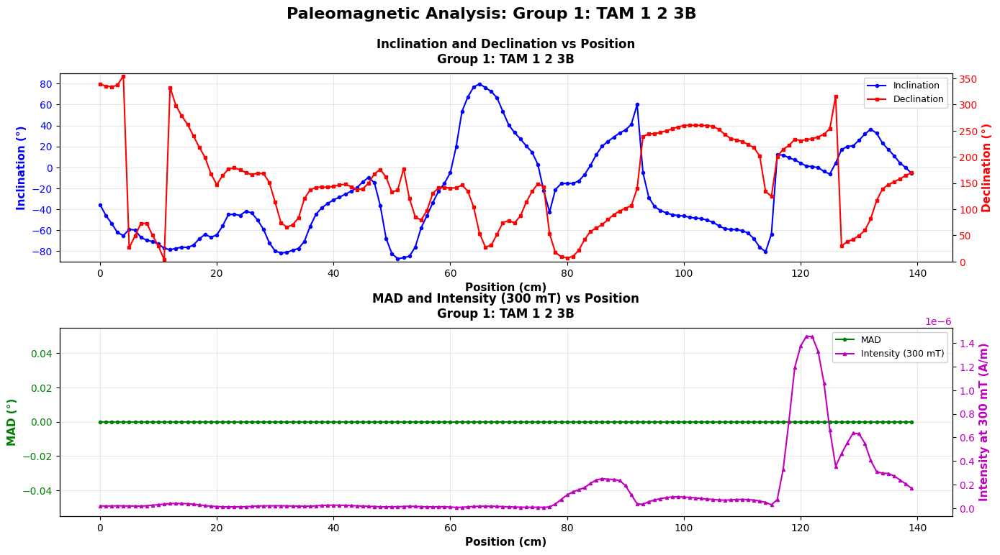


Statistics for Group 1: TAM 1 2 3B
Inclination range: -87.29° to 79.65°
Declination range: 3.39° to 354.68°
MAD range: 0.00° to 0.00°
Mean MAD: 0.00° (±0.00°)


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


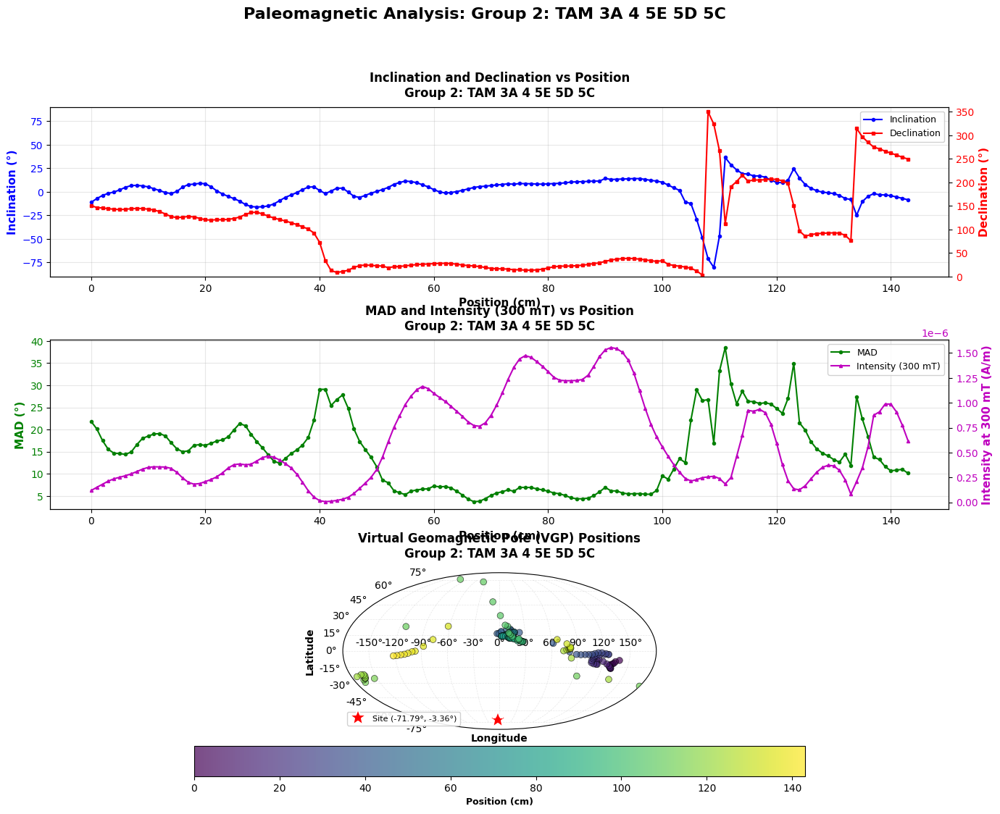


Statistics for Group 2: TAM 3A 4 5E 5D 5C
Inclination range: -80.27° to 36.40°
Declination range: 3.12° to 349.59°
MAD range: 3.71° to 38.51°
Mean MAD: 14.50° (±8.02°)
VGP Lat range: -33.48° to 76.13°
VGP Lon range: -173.20° to 179.73°


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


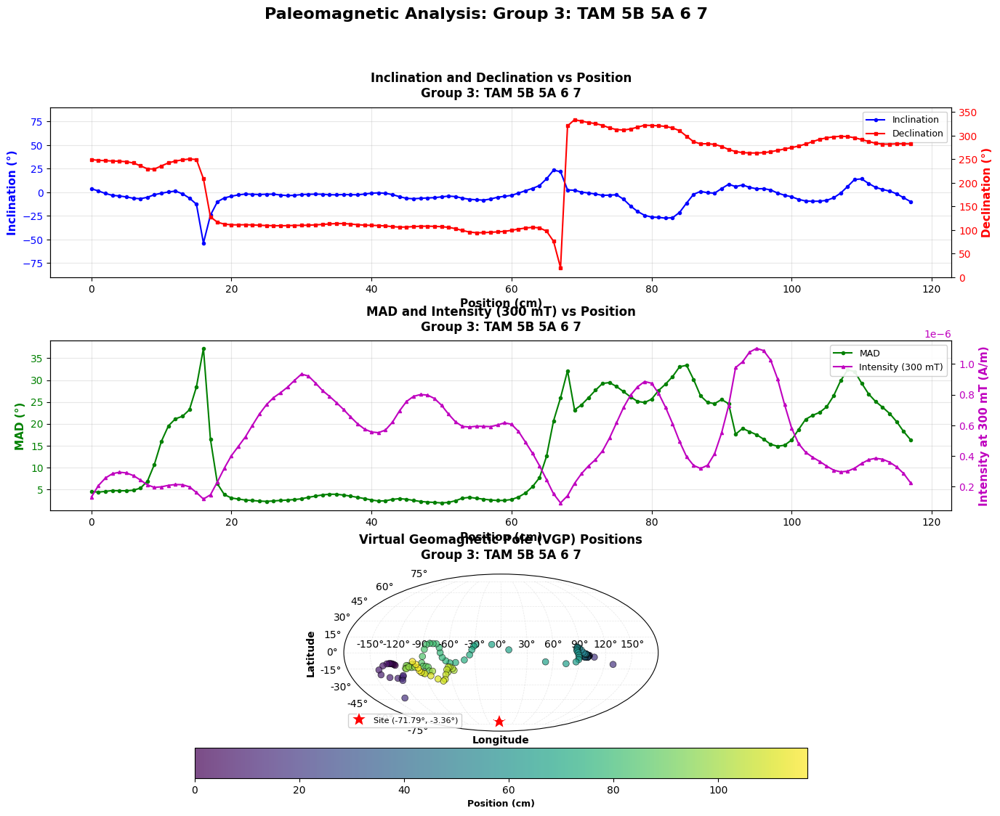


Statistics for Group 3: TAM 5B 5A 6 7
Inclination range: -53.80° to 23.36°
Declination range: 20.15° to 333.56°
MAD range: 1.87° to 37.25°
Mean MAD: 14.07° (±11.10°)
VGP Lat range: -43.88° to 8.66°
VGP Lon range: -143.35° to 129.72°


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


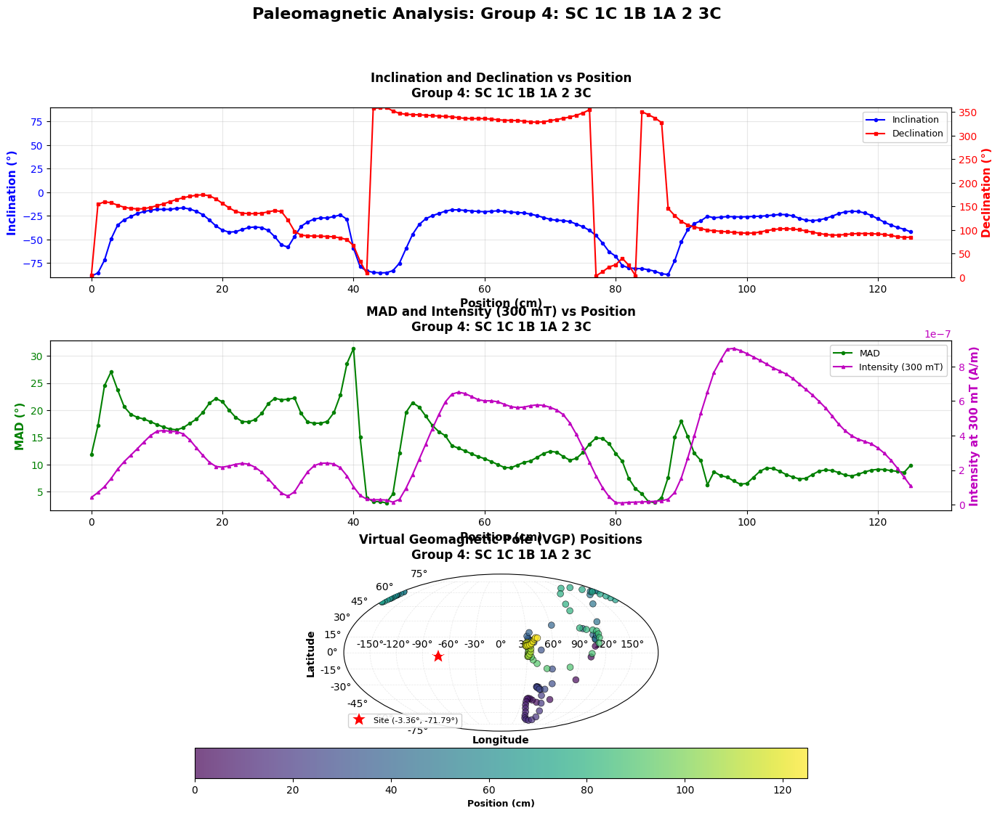


Statistics for Group 4: SC 1C 1B 1A 2 3C
Inclination range: -88.69° to -16.59°
Declination range: 2.85° to 359.46°
MAD range: 2.96° to 31.37°
Mean MAD: 13.35° (±6.00°)
VGP Lat range: -69.98° to 66.40°
VGP Lon range: -179.98° to 179.28°


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


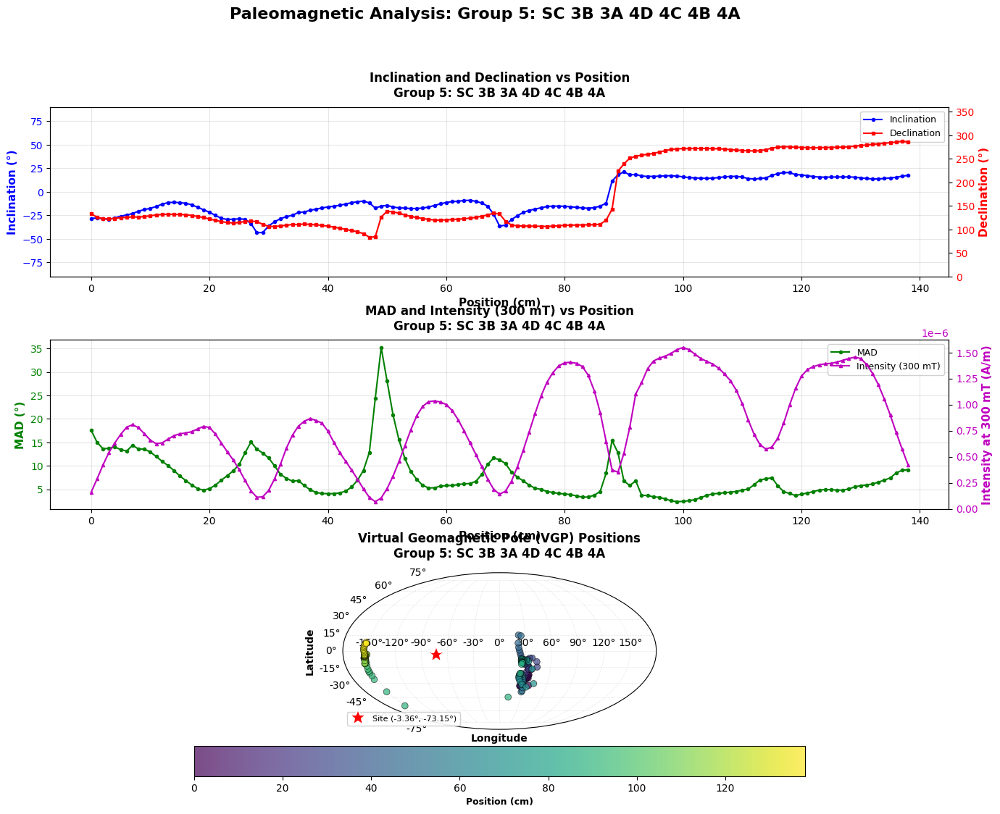


Statistics for Group 5: SC 3B 3A 4D 4C 4B 4A
Inclination range: -43.34° to 21.07°
Declination range: 83.54° to 287.00°
MAD range: 2.37° to 35.19°
Mean MAD: 7.71° (±4.91°)
VGP Lat range: -54.23° to 14.89°
VGP Lon range: -156.85° to 44.12°


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


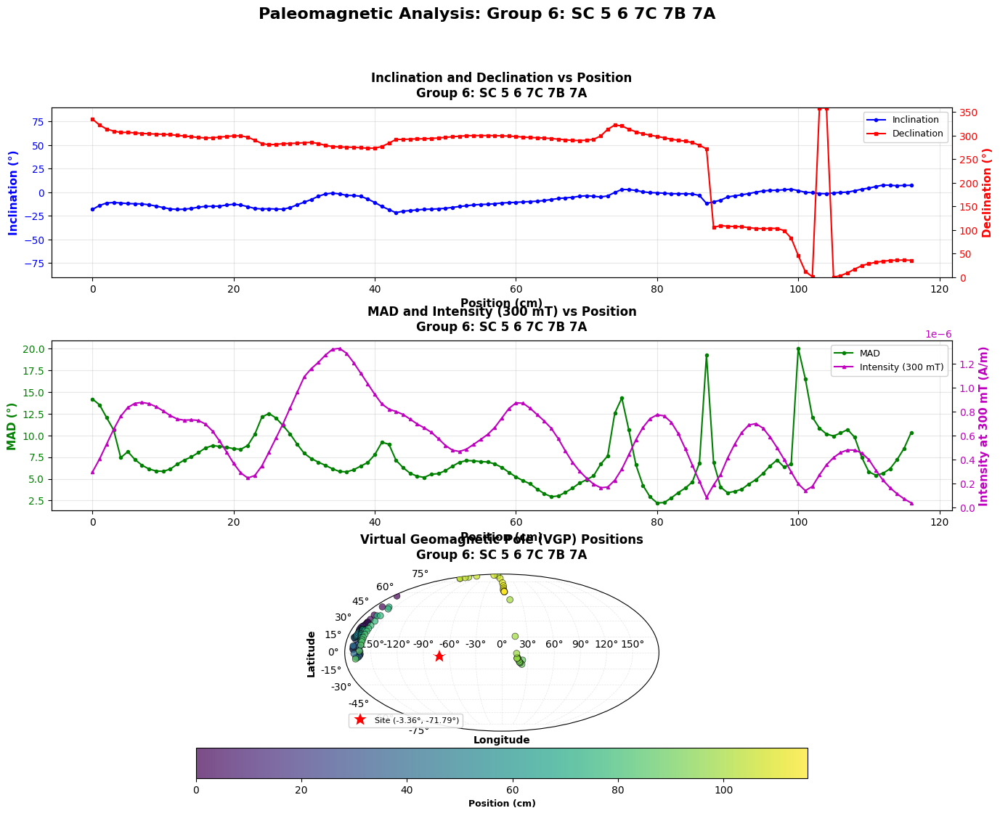


Statistics for Group 6: SC 5 6 7C 7B 7A
Inclination range: -21.64° to 7.58°
Declination range: 0.07° to 358.53°
MAD range: 2.22° to 20.03°
Mean MAD: 7.35° (±3.22°)
VGP Lat range: -10.91° to 86.41°
VGP Lon range: -173.60° to 23.83°


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3531094085.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


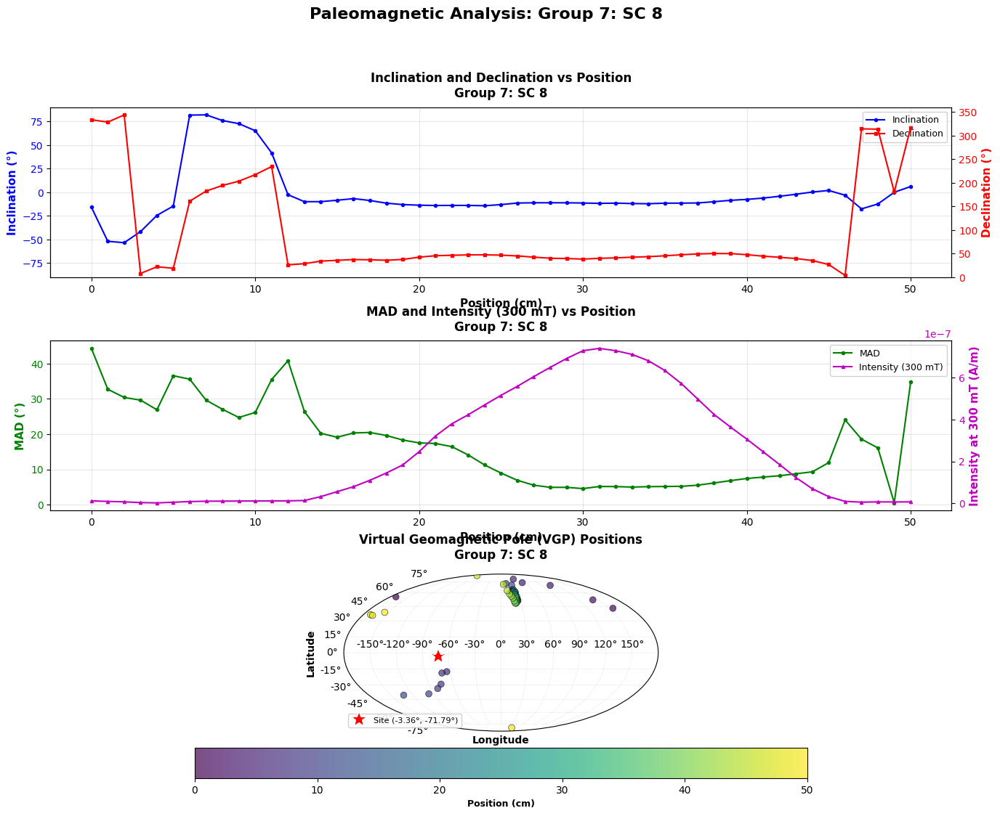


Statistics for Group 7: SC 8
Inclination range: -53.44° to 81.93°
Declination range: 3.85° to 343.70°
MAD range: 0.49° to 44.33°
Mean MAD: 17.13° (±11.53°)
VGP Lat range: -81.59° to 85.33°
VGP Lon range: -171.12° to 155.28°


In [29]:
# single group
# plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')

# specific groups
#plot_paleomag_data('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026')
#plot_paleomag_data('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026')
#plot_paleomag_data('Group 7: SC 8', 'SC_8_NRM_01212026')

# all groups
for group_name, sample_id in SAMPLE_GROUPS.items():
    plot_paleomag_data(group_name, sample_id)


### combine group data into sites



In [30]:
"""
Paleomagnetic Data Visualization - SITE COMBINED PLOTS
Combines multiple groups into continuous site records
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', False),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def combine_site_data(site_info):
    """
    Combine multiple groups into a continuous site record.
    
    Parameters:
    -----------
    site_info : dict
        Dictionary containing group information
        
    Returns:
    --------
    combined_pca : DataFrame
        Combined PCA data with adjusted positions
    combined_int : DataFrame
        Combined intensity data with adjusted positions
    group_boundaries : list
        List of position boundaries between groups
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read PCA data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        # Read intensity data (unless skipping)
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
            if int_df is None:
                print(f"    Warning: Could not load intensity data for {group_name}")
        else:
            int_df = None
            print(f"    Skipping MAD/Intensity for {group_name}")
        
        # Adjust positions by adding offset
        pca_df_copy = pca_df.copy()
        pca_df_copy['position'] = pca_df_copy['position'] + current_offset
        pca_df_copy['group'] = group_name
        combined_pca.append(pca_df_copy)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            int_df_copy['position'] = int_df_copy['position'] + current_offset
            int_df_copy['group'] = group_name
            combined_int.append(int_df_copy)
        
        # Update offset for next group (max position + small gap)
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1  # Add 1 cm gap between groups
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df)} points")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1]  # Remove last boundary

# ============================================================================
# PLOTTING FUNCTION
# ============================================================================

def plot_site_combined(site_name, site_info):
    """
    Generate combined plots for an entire site.
    
    Parameters:
    -----------
    site_name : str
        Name of the site
    site_info : dict
        Dictionary containing group information
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data from all groups
    pca_df, int_df, boundaries = combine_site_data(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No data available for {site_name}")
        return
    
    print(f"\nTotal combined data points: {len(pca_df)}")
    
    # Create figure with 2 subplots (no VGP)
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Inclination (left y-axis)
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=2, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    # Declination (right y-axis)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=2,
                   linewidth=1.5, label='Declination', alpha=0.8)
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add vertical lines at group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    
    ax1.set_title(f'Inclination and Declination - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # MAD (left y-axis)
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=2,
             linewidth=1.5, label='MAD', alpha=0.8)
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Intensity at 300 mT (right y-axis)
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=2,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    # Add vertical lines at group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name}', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name}")
    print(f"{'='*70}")
    print(f"Total position range: {pca_df['position'].min():.2f} - {pca_df['position'].max():.2f} cm")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")
    
    # Print group boundaries
    print(f"\nGroup boundaries at positions: {boundaries}")
    
    # Print component groups
    print(f"\nComponent groups:")
    for i, (group_name, _, skip) in enumerate(site_info['groups']):
        skip_text = " (Inc/Dec only)" if skip else ""
        print(f"  {i+1}. {group_name}{skip_text}")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3)
# plot_site_combined('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7)
# plot_site_combined('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
# for site_name, site_info in SITES.items():
#     plot_site_combined(site_name, site_info)


Processing Site 1 (TAM)
  Loading Group 1: TAM 1 2 3B...
    Loaded 140 points
  Loading Group 2: TAM 3A 4 5E 5D 5C...
    Loaded 144 points
  Loading Group 3: TAM 5B 5A 6 7...
    Loaded 118 points

Total combined data points: 402


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3136980957.py:256: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


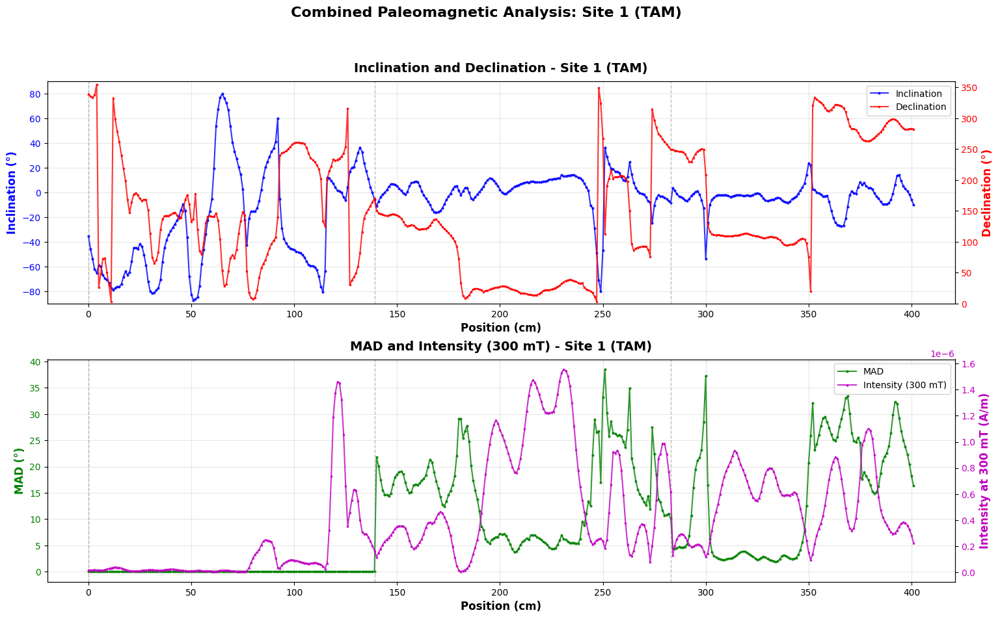


Statistics for Site 1 (TAM)
Total position range: 0.00 - 401.00 cm
Inclination range: -87.29° to 79.65°
Declination range: 3.12° to 354.68°
MAD range: 0.00° to 38.51°
Mean MAD: 9.32° (±10.27°)

Group boundaries at positions: [0, np.int64(139), np.float64(283.0)]

Component groups:
  1. Group 1: TAM 1 2 3B
  2. Group 2: TAM 3A 4 5E 5D 5C
  3. Group 3: TAM 5B 5A 6 7


In [31]:
plot_site_combined('Site 1 (TAM)', SITES['Site 1 (TAM)'])


Processing Site 2 (SC)
  Loading Group 4: SC 1C 1B 1A 2 3C...
    Loaded 126 points
  Loading Group 5: SC 3B 3A 4D 4C 4B 4A...
    Loaded 139 points
  Loading Group 6: SC 5 6 7C 7B 7A...
    Loaded 117 points
  Loading Group 7: SC 8...
    Loaded 51 points

Total combined data points: 433


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3136980957.py:256: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


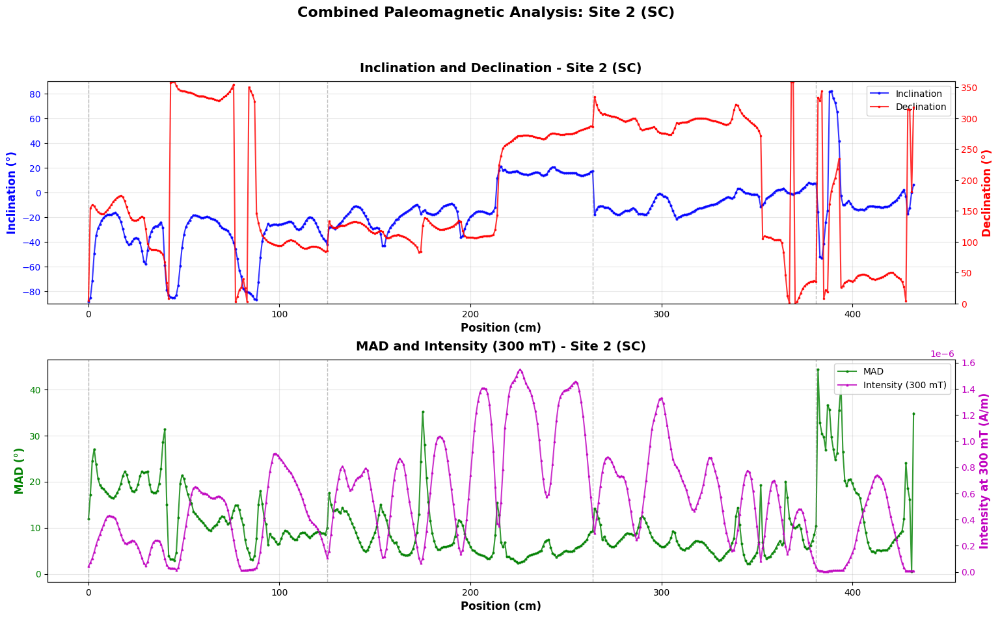


Statistics for Site 2 (SC)
Total position range: 0.00 - 432.00 cm
Inclination range: -88.69° to 81.93°
Declination range: 0.07° to 359.46°
MAD range: 0.49° to 44.33°
Mean MAD: 10.36° (±7.00°)

Group boundaries at positions: [0, np.float64(125.0), np.float64(264.0), np.float64(381.0)]

Component groups:
  1. Group 4: SC 1C 1B 1A 2 3C
  2. Group 5: SC 3B 3A 4D 4C 4B 4A
  3. Group 6: SC 5 6 7C 7B 7A
  4. Group 7: SC 8


In [26]:
plot_site_combined('Site 2 (SC)', SITES['Site 2 (SC)'])

### lets grey out the data assocaited with foam breaks

In [39]:
"""
Paleomagnetic Data Visualization - SITE COMBINED PLOTS WITH FOAM EXCLUSION
Combines multiple groups into continuous site records and greys out foam sections
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable x-coordinates (foam-free regions) for each group
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_with_viable(site_info):
    """
    Combine multiple groups into a continuous site record with viable flags.
    
    Returns:
    --------
    combined_pca : DataFrame with 'viable' column
    combined_int : DataFrame with 'viable' column
    group_boundaries : list of position boundaries
    foam_regions : list of (start, end) tuples for foam regions
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    foam_regions = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        # Get viable regions for this group
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        # Add viable flag based on original position
        pca_df_copy = pca_df.copy()
        pca_df_copy['viable'] = pca_df_copy['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        
        # Track foam regions in combined coordinates
        if len(viable_ranges) > 0:
            # Get the full range of this group
            min_pos = pca_df['position'].min()
            max_pos = pca_df['position'].max()
            
            # Build foam regions as inverse of viable regions
            # Sort viable ranges
            sorted_ranges = sorted(viable_ranges, key=lambda x: x[0])
            
            # Add foam region before first viable range
            if sorted_ranges[0][0] > min_pos:
                foam_start = current_offset + min_pos
                foam_end = current_offset + sorted_ranges[0][0]
                foam_regions.append((foam_start, foam_end))
            
            # Add foam regions between viable ranges
            for i in range(len(sorted_ranges) - 1):
                foam_start = current_offset + sorted_ranges[i][1]
                foam_end = current_offset + sorted_ranges[i + 1][0]
                foam_regions.append((foam_start, foam_end))
            
            # Add foam region after last viable range
            if sorted_ranges[-1][1] < max_pos:
                foam_start = current_offset + sorted_ranges[-1][1]
                foam_end = current_offset + max_pos
                foam_regions.append((foam_start, foam_end))
        
        # Adjust positions by adding offset
        pca_df_copy['position'] = pca_df_copy['position'] + current_offset
        pca_df_copy['group'] = group_name
        combined_pca.append(pca_df_copy)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            int_df_copy['viable'] = int_df_copy['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_copy['position'] = int_df_copy['position'] + current_offset
            int_df_copy['group'] = group_name
            combined_int.append(int_df_copy)
        
        # Update offset for next group
        current_offset += max_pos + 1
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df)} points ({pca_df_copy['viable'].sum()} viable)")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1], foam_regions

# ============================================================================
# PLOTTING FUNCTION WITH FOAM GREYING
# ============================================================================

def plot_site_combined_with_foam(site_name, site_info):
    """
    Generate combined plots with foam regions greyed out.
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data with viable flags
    pca_df, int_df, boundaries, foam_regions = combine_site_data_with_viable(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No data available for {site_name}")
        return
    
    print(f"\nTotal combined data points: {len(pca_df)} ({pca_df['viable'].sum()} viable)")
    print(f"Found {len(foam_regions)} foam regions")
    
    # Create figure
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Plot data
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=2, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=2,
                   linewidth=1.5, label='Declination', alpha=0.8)
    
    # Grey out foam regions
    for foam_start, foam_end in foam_regions:
        ax1.axvspan(foam_start, foam_end, color='gray', alpha=0.3, zorder=0)
    
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax1.set_title(f'Inclination and Declination - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # Plot MAD
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=2,
             linewidth=1.5, label='MAD', alpha=0.8)
    
    # Grey out foam regions
    for foam_start, foam_end in foam_regions:
        ax2.axvspan(foam_start, foam_end, color='gray', alpha=0.3, zorder=0)
    
    # Plot intensity if available
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=2,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Add group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name}', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name} (Foam Regions Greyed)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics for viable data only
    viable_pca = pca_df[pca_df['viable']]
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name} (Viable Data Only)")
    print(f"{'='*70}")
    print(f"Viable data points: {len(viable_pca)} / {len(pca_df)}")
    print(f"Inclination range: {viable_pca['Incl'].min():.2f}° to {viable_pca['Incl'].max():.2f}°")
    print(f"Declination range: {viable_pca['Decl'].min():.2f}° to {viable_pca['Decl'].max():.2f}°")
    print(f"MAD range: {viable_pca['MAD'].min():.2f}° to {viable_pca['MAD'].max():.2f}°")
    print(f"Mean MAD: {viable_pca['MAD'].mean():.2f}° (±{viable_pca['MAD'].std():.2f}°)")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3) with foam regions greyed
# plot_site_combined_with_foam('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7) with foam regions greyed
# plot_site_combined_with_foam('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
# for site_name, site_info in SITES.items():
#     plot_site_combined_with_foam(site_name, site_info)


Processing Site 1 (TAM)
  Loading Group 1: TAM 1 2 3B...
    Loaded 140 points (98 viable)
  Loading Group 2: TAM 3A 4 5E 5D 5C...
    Loaded 144 points (116 viable)
  Loading Group 3: TAM 5B 5A 6 7...
    Loaded 118 points (100 viable)

Total combined data points: 402 (314 viable)
Found 13 foam regions


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3260222191.py:306: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


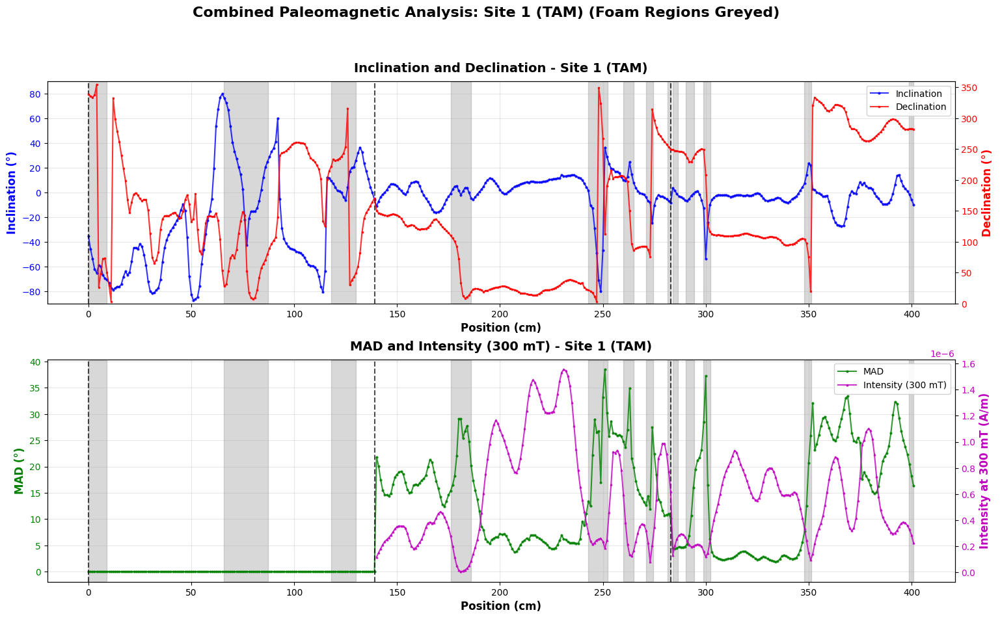


Statistics for Site 1 (TAM) (Viable Data Only)
Viable data points: 314 / 402
Inclination range: -87.29° to 79.65°
Declination range: 3.39° to 333.56°
MAD range: 0.00° to 33.38°
Mean MAD: 8.99° (±9.68°)

Processing Site 2 (SC)
  Loading Group 4: SC 1C 1B 1A 2 3C...
    Loaded 126 points (81 viable)
  Loading Group 5: SC 3B 3A 4D 4C 4B 4A...
Error reading PCA file /Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loading Group 6: SC 5 6 7C 7B 7A...
    Loaded 117 points (96 viable)
  Loading Group 7: SC 8...
    Loaded 51 points (28 viable)

Total combined data points: 294 (205 viable)
Found 13 foam regions


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3260222191.py:306: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


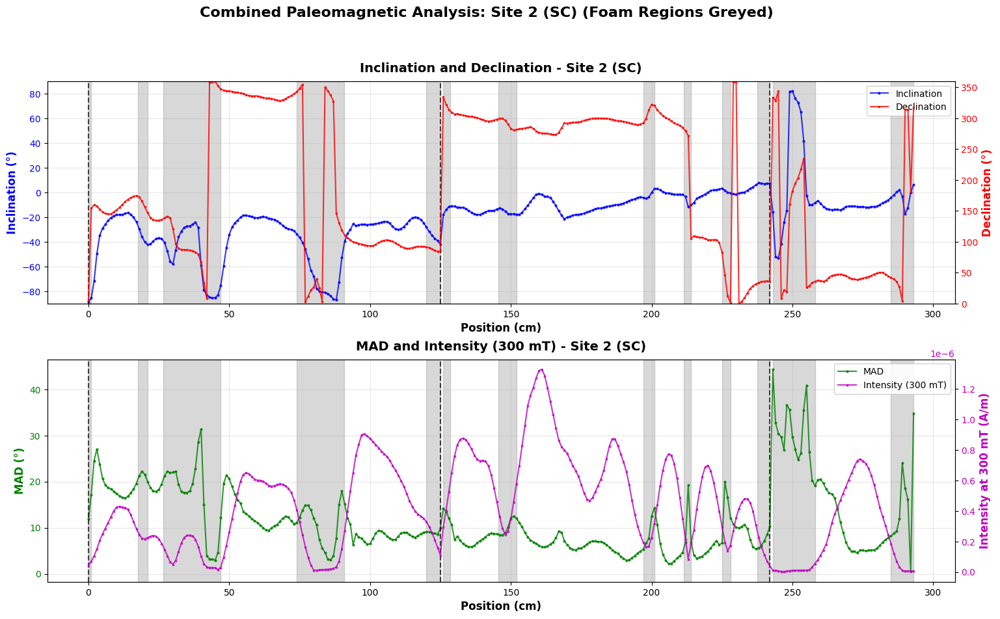


Statistics for Site 2 (SC) (Viable Data Only)
Viable data points: 205 / 294
Inclination range: -85.54° to 6.01°
Declination range: 0.07° to 358.53°
MAD range: 2.22° to 27.06°
Mean MAD: 9.65° (±5.14°)


In [40]:
#Plot both sites
for site_name, site_info in SITES.items():
    plot_site_combined_with_foam(site_name, site_info)

### FOAM REMOVED PLOTS


Processing Site 1 (TAM)
  Loading Group 1: TAM 1 2 3B...
    Loaded 98 viable points (out of 140 total)
  Loading Group 2: TAM 3A 4 5E 5D 5C...
    Loaded 116 viable points (out of 144 total)
  Loading Group 3: TAM 5B 5A 6 7...
    Loaded 100 viable points (out of 118 total)

Total viable data points: 314


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/2725304977.py:265: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


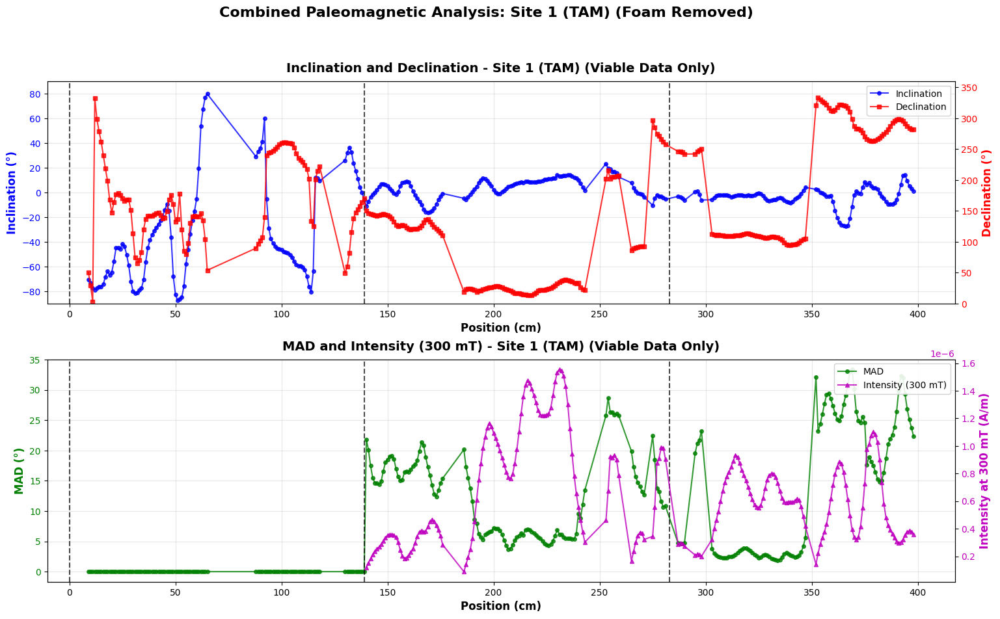


Statistics for Site 1 (TAM) (Viable Data Only)
Total viable data points: 314
Position range: 9.00 - 398.00 cm
Inclination range: -87.29° to 79.65°
Declination range: 3.39° to 333.56°
MAD range: 0.00° to 33.38°
Mean MAD: 8.99° (±9.68°)

Processing Site 2 (SC)
  Loading Group 4: SC 1C 1B 1A 2 3C...
    Loaded 81 viable points (out of 126 total)
  Loading Group 5: SC 3B 3A 4D 4C 4B 4A...
    Loaded 112 viable points (out of 139 total)
  Loading Group 6: SC 5 6 7C 7B 7A...
    Loaded 96 viable points (out of 117 total)
  Loading Group 7: SC 8...
    Loaded 28 viable points (out of 51 total)

Total viable data points: 317


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/2725304977.py:265: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


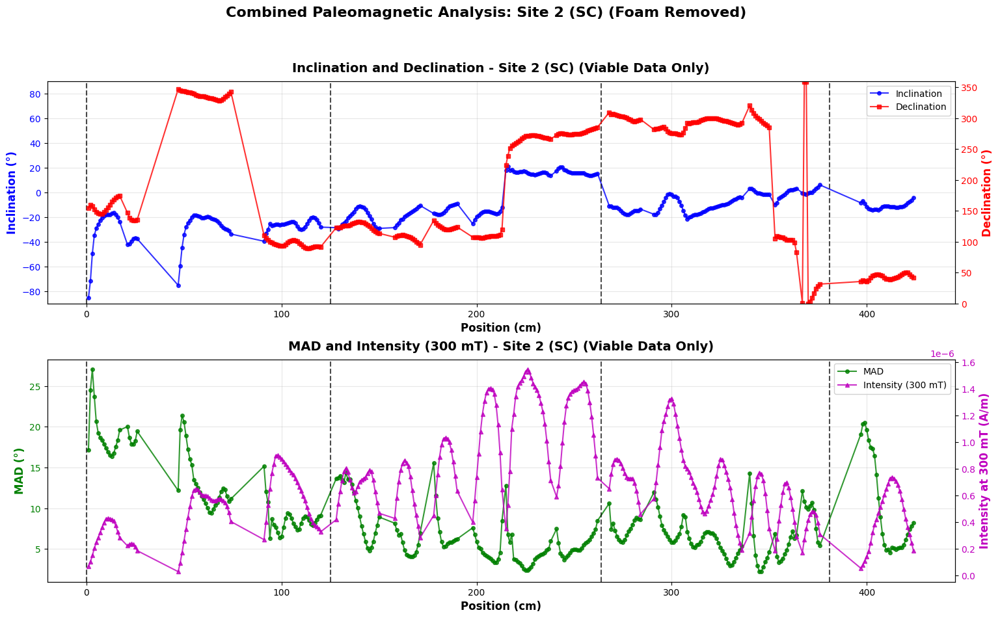


Statistics for Site 2 (SC) (Viable Data Only)
Total viable data points: 317
Position range: 1.00 - 424.00 cm
Inclination range: -85.54° to 21.07°
Declination range: 0.07° to 358.53°
MAD range: 2.22° to 27.06°
Mean MAD: 8.48° (±4.78°)


In [43]:


# Configure matplotlib for inline display
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),  # Skip MAD/Intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SC_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable x-coordinates (foam-free regions) for each group
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file {filepath}: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file {filepath}: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """
    Combine multiple groups into a continuous site record, keeping ONLY viable data.
    
    Returns:
    --------
    combined_pca : DataFrame with viable data only
    combined_int : DataFrame with viable data only
    group_boundaries : list of position boundaries
    """
    
    combined_pca = []
    combined_int = []
    group_boundaries = [0]
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        print(f"  Loading {group_name}...")
        
        # Get file paths
        paths = get_file_paths(sample_id)
        
        # Read data
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            print(f"    Warning: Could not load PCA data for {group_name}")
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        # Get viable regions for this group
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        # Filter to keep ONLY viable data
        pca_df_copy = pca_df.copy()
        viable_mask = pca_df_copy['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_copy[viable_mask].copy()
        
        if len(pca_df_viable) == 0:
            print(f"    Warning: No viable data for {group_name}")
            continue
        
        # Adjust positions by adding offset
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        pca_df_viable['group'] = group_name
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_copy = int_df.copy()
            viable_mask_int = int_df_copy['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_copy[viable_mask_int].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                int_df_viable['group'] = group_name
                combined_int.append(int_df_viable)
        
        # Update offset for next group (use max position of viable data)
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
        group_boundaries.append(current_offset - 1)
        
        print(f"    Loaded {len(pca_df_viable)} viable points (out of {len(pca_df)} total)")
    
    # Combine all dataframes
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df, group_boundaries[:-1]

# ============================================================================
# PLOTTING FUNCTION WITH FOAM REMOVED
# ============================================================================

def plot_site_combined_viable_only(site_name, site_info):
    """
    Generate combined plots with foam sections completely removed.
    """
    
    print(f"\n{'='*70}")
    print(f"Processing {site_name}")
    print(f"{'='*70}")
    
    # Combine data - viable only
    pca_df, int_df, boundaries = combine_site_data_viable_only(site_info)
    
    if pca_df is None or len(pca_df) == 0:
        print(f"Error: No viable data available for {site_name}")
        return
    
    print(f"\nTotal viable data points: {len(pca_df)}")
    
    # Create figure
    fig = plt.figure(figsize=(18, 10))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.25)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # Plot data
    ax1.plot(pca_df['position'], pca_df['Incl'], 'b-o', markersize=4, 
             linewidth=1.5, label='Inclination', alpha=0.8)
    ax1_right.plot(pca_df['position'], pca_df['Decl'], 'r-s', markersize=4,
                   linewidth=1.5, label='Declination', alpha=0.8)
    
    ax1.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold', color='b')
    ax1.tick_params(axis='y', labelcolor='b')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold', color='r')
    ax1_right.tick_params(axis='y', labelcolor='r')
    ax1_right.set_ylim([0, 360])
    
    # Add group boundaries
    for boundary in boundaries:
        ax1.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax1.set_title(f'Inclination and Declination - {site_name} (Viable Data Only)', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # Plot MAD
    ax2.plot(pca_df['position'], pca_df['MAD'], 'g-o', markersize=4,
             linewidth=1.5, label='MAD', alpha=0.8)
    
    # Plot intensity if available
    if int_df is not None and len(int_df) > 0 and 'Int 300' in int_df.columns:
        int_300 = pd.to_numeric(int_df['Int 300'], errors='coerce')
        ax2_right.plot(int_df['position'], int_300, 'm-^', markersize=4,
                       linewidth=1.5, label='Intensity (300 mT)', alpha=0.8)
        ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, 
                             fontweight='bold', color='m')
        ax2_right.tick_params(axis='y', labelcolor='m')
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold', color='g')
    ax2.tick_params(axis='y', labelcolor='g')
    ax2.grid(True, alpha=0.3)
    
    # Add group boundaries
    for boundary in boundaries:
        ax2.axvline(x=boundary, color='black', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax2.set_title(f'MAD and Intensity (300 mT) - {site_name} (Viable Data Only)', 
                  fontsize=14, fontweight='bold', pad=10)
    
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=10)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle(f'Combined Paleomagnetic Analysis: {site_name} (Foam Removed)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print(f"Statistics for {site_name} (Viable Data Only)")
    print(f"{'='*70}")
    print(f"Total viable data points: {len(pca_df)}")
    print(f"Position range: {pca_df['position'].min():.2f} - {pca_df['position'].max():.2f} cm")
    print(f"Inclination range: {pca_df['Incl'].min():.2f}° to {pca_df['Incl'].max():.2f}°")
    print(f"Declination range: {pca_df['Decl'].min():.2f}° to {pca_df['Decl'].max():.2f}°")
    print(f"MAD range: {pca_df['MAD'].min():.2f}° to {pca_df['MAD'].max():.2f}°")
    print(f"Mean MAD: {pca_df['MAD'].mean():.2f}° (±{pca_df['MAD'].std():.2f}°)")

# ============================================================================
# USAGE EXAMPLES
# ============================================================================

# Plot Site 1 (TAM: Groups 1, 2, 3) with foam removed
# plot_site_combined_viable_only('Site 1 (TAM)', SITES['Site 1 (TAM)'])

# Plot Site 2 (SC: Groups 4, 5, 6, 7) with foam removed
# plot_site_combined_viable_only('Site 2 (SC)', SITES['Site 2 (SC)'])

# Plot both sites
for site_name, site_info in SITES.items():
    plot_site_combined_viable_only(site_name, site_info)


GENERATING OVERLAY PLOTS FOR TAM vs SC COMPARISON

Loading data for Site 1 (TAM)...
  Loading Group 1: TAM 1 2 3B...
    Loaded 98 viable points (out of 140 total)
  Loading Group 2: TAM 3A 4 5E 5D 5C...
    Loaded 116 viable points (out of 144 total)
  Loading Group 3: TAM 5B 5A 6 7...
    Loaded 100 viable points (out of 118 total)
  Loaded 314 viable points

Loading data for Site 2 (SC)...
  Loading Group 4: SC 1C 1B 1A 2 3C...
    Loaded 81 viable points (out of 126 total)
  Loading Group 5: SC 3B 3A 4D 4C 4B 4A...
    Loaded 112 viable points (out of 139 total)
  Loading Group 6: SC 5 6 7C 7B 7A...
    Loaded 96 viable points (out of 117 total)
  Loading Group 7: SC 8...
    Loaded 28 viable points (out of 51 total)
  Loaded 317 viable points


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1696268154.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


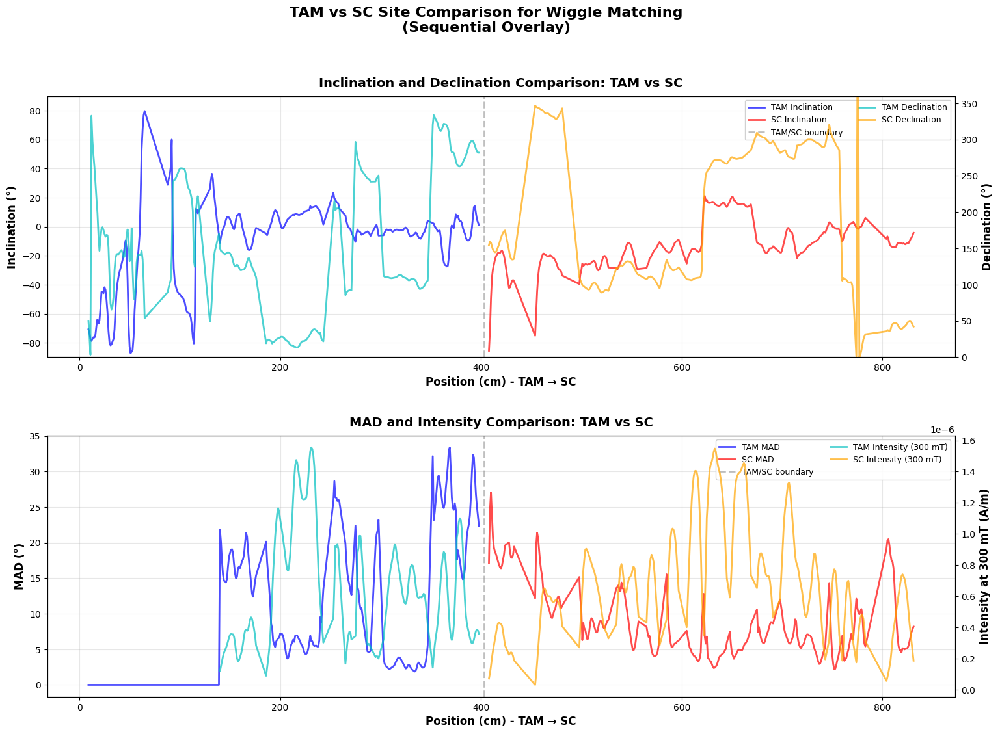


COMPARISON STATISTICS

TAM Site:
  Points: 314
  Position range: 9.0 - 398.0 cm
  Inclination range: -87.3° to 79.7°
  Mean MAD: 8.99° (±9.68°)

SC Site:
  Points: 317
  Position range: 1.0 - 424.0 cm
  Inclination range: -85.5° to 21.1°
  Mean MAD: 8.48° (±4.78°)

Note: SC data offset by 407.0 cm for visual comparison
Next step: Apply interpolation and cross-correlation for wiggle matching


In [44]:
# ============================================================================
# OVERLAY PLOTTING
# ============================================================================

print("="*70)
print("GENERATING OVERLAY PLOTS FOR TAM vs SC COMPARISON")
print("="*70)

# Process both sites and store their data
site_data = {}

for site_name, site_info in SITES.items():
    print(f"\nLoading data for {site_name}...")
    
    # Combine data - viable only
    pca_df, int_df, boundaries = combine_site_data_viable_only(site_info)
    
    if pca_df is not None and len(pca_df) > 0:
        site_data[site_name] = {
            'pca': pca_df,
            'int': int_df,
            'boundaries': boundaries
        }
        print(f"  Loaded {len(pca_df)} viable points")
    else:
        print(f"  Warning: No data for {site_name}")

# Check we have both sites
if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing data for one or both sites")
else:
    # Extract data for both sites
    tam_pca = site_data['Site 1 (TAM)']['pca']
    tam_int = site_data['Site 1 (TAM)']['int']
    sc_pca = site_data['Site 2 (SC)']['pca']
    sc_int = site_data['Site 2 (SC)']['int']
    
    # Create figure with 2 subplots
    fig = plt.figure(figsize=(18, 12))
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.3)
    
    # ========================================================================
    # PLOT 1: Inclination and Declination Overlay
    # ========================================================================
    ax1 = fig.add_subplot(gs[0])
    ax1_right = ax1.twinx()
    
    # TAM data (blue/cyan tones)
    ax1.plot(tam_pca['position'], tam_pca['Incl'], 'b-', linewidth=2, 
             label='TAM Inclination', alpha=0.7)
    ax1_right.plot(tam_pca['position'], tam_pca['Decl'], 'c-', linewidth=2,
                   label='TAM Declination', alpha=0.7)
    
    # SC data (red/orange tones) - offset position to overlay
    # Normalize SC positions to start where TAM ends
    tam_max_pos = tam_pca['position'].max()
    sc_offset = tam_max_pos - sc_pca['position'].min() + 10  # 10cm gap
    
    ax1.plot(sc_pca['position'] + sc_offset, sc_pca['Incl'], 'r-', linewidth=2,
             label='SC Inclination', alpha=0.7)
    ax1_right.plot(sc_pca['position'] + sc_offset, sc_pca['Decl'], 'orange',
                   linewidth=2, label='SC Declination', alpha=0.7)
    
    # Mark the transition
    ax1.axvline(x=tam_max_pos + 5, color='gray', linestyle='--', 
                alpha=0.5, linewidth=2, label='TAM/SC boundary')
    
    # Labels and formatting
    ax1.set_xlabel('Position (cm) - TAM → SC', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold')
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim([-90, 90])
    
    ax1_right.set_ylabel('Declination (°)', fontsize=12, fontweight='bold')
    ax1_right.tick_params(axis='y', labelcolor='black')
    ax1_right.set_ylim([0, 360])
    
    ax1.set_title('Inclination and Declination Comparison: TAM vs SC', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_right.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', 
               framealpha=0.9, fontsize=9, ncol=2)
    
    # ========================================================================
    # PLOT 2: MAD and Intensity Overlay
    # ========================================================================
    ax2 = fig.add_subplot(gs[1])
    ax2_right = ax2.twinx()
    
    # TAM MAD
    ax2.plot(tam_pca['position'], tam_pca['MAD'], 'b-', linewidth=2,
             label='TAM MAD', alpha=0.7)
    
    # SC MAD
    ax2.plot(sc_pca['position'] + sc_offset, sc_pca['MAD'], 'r-', linewidth=2,
             label='SC MAD', alpha=0.7)
    
    # TAM Intensity (if available)
    if tam_int is not None and len(tam_int) > 0 and 'Int 300' in tam_int.columns:
        int_300_tam = pd.to_numeric(tam_int['Int 300'], errors='coerce')
        ax2_right.plot(tam_int['position'], int_300_tam, 'c-', linewidth=2,
                       label='TAM Intensity (300 mT)', alpha=0.7)
        ax2_right.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    # SC Intensity (if available)
    if sc_int is not None and len(sc_int) > 0 and 'Int 300' in sc_int.columns:
        int_300_sc = pd.to_numeric(sc_int['Int 300'], errors='coerce')
        ax2_right.plot(sc_int['position'] + sc_offset, int_300_sc, 'orange',
                       linewidth=2, label='SC Intensity (300 mT)', alpha=0.7)
    
    # Mark the transition
    ax2.axvline(x=tam_max_pos + 5, color='gray', linestyle='--',
                alpha=0.5, linewidth=2, label='TAM/SC boundary')
    
    # Labels and formatting
    ax2.set_xlabel('Position (cm) - TAM → SC', fontsize=12, fontweight='bold')
    ax2.set_ylabel('MAD (°)', fontsize=12, fontweight='bold')
    ax2.tick_params(axis='y', labelcolor='black')
    ax2.grid(True, alpha=0.3)
    
    ax2_right.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, fontweight='bold')
    ax2_right.tick_params(axis='y', labelcolor='black')
    
    ax2.set_title('MAD and Intensity Comparison: TAM vs SC', 
                  fontsize=14, fontweight='bold', pad=10)
    
    # Combined legend
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_right.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right',
               framealpha=0.9, fontsize=9, ncol=2)
    
    # ========================================================================
    # Overall title and display
    # ========================================================================
    fig.suptitle('TAM vs SC Site Comparison for Wiggle Matching\n(Sequential Overlay)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Print comparison statistics
    print("\n" + "="*70)
    print("COMPARISON STATISTICS")
    print("="*70)
    print(f"\nTAM Site:")
    print(f"  Points: {len(tam_pca)}")
    print(f"  Position range: {tam_pca['position'].min():.1f} - {tam_pca['position'].max():.1f} cm")
    print(f"  Inclination range: {tam_pca['Incl'].min():.1f}° to {tam_pca['Incl'].max():.1f}°")
    print(f"  Mean MAD: {tam_pca['MAD'].mean():.2f}° (±{tam_pca['MAD'].std():.2f}°)")
    
    print(f"\nSC Site:")
    print(f"  Points: {len(sc_pca)}")
    print(f"  Position range: {sc_pca['position'].min():.1f} - {sc_pca['position'].max():.1f} cm")
    print(f"  Inclination range: {sc_pca['Incl'].min():.1f}° to {sc_pca['Incl'].max():.1f}°")
    print(f"  Mean MAD: {sc_pca['MAD'].mean():.2f}° (±{sc_pca['MAD'].std():.2f}°)")
    
    print(f"\nNote: SC data offset by {sc_offset:.1f} cm for visual comparison")
    print("Next step: Apply interpolation and cross-correlation for wiggle matching")

### wiggle matching

WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS

Loading Site 1 (TAM)...
  Loaded 314 viable points

Loading Site 2 (SC)...
Error reading PCA file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loaded 205 viable points

STEP 1: INTERPOLATING TO REGULAR GRIDS

TAM interpolated: 779 points at 0.5 cm spacing
SC interpolated: 569 points at 0.5 cm spacing

STEP 2: CROSS-CORRELATION ANALYSIS

Inclination:
  Best correlation: 0.379
  Optimal lag: 7 points = 3.5 cm

Declination:
  Best correlation: 0.410
  Optimal lag: -86 points = -43.0 cm

Average optimal offset: -19.8 cm

STEP 3: VISUALIZATION


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/3483832002.py:402: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


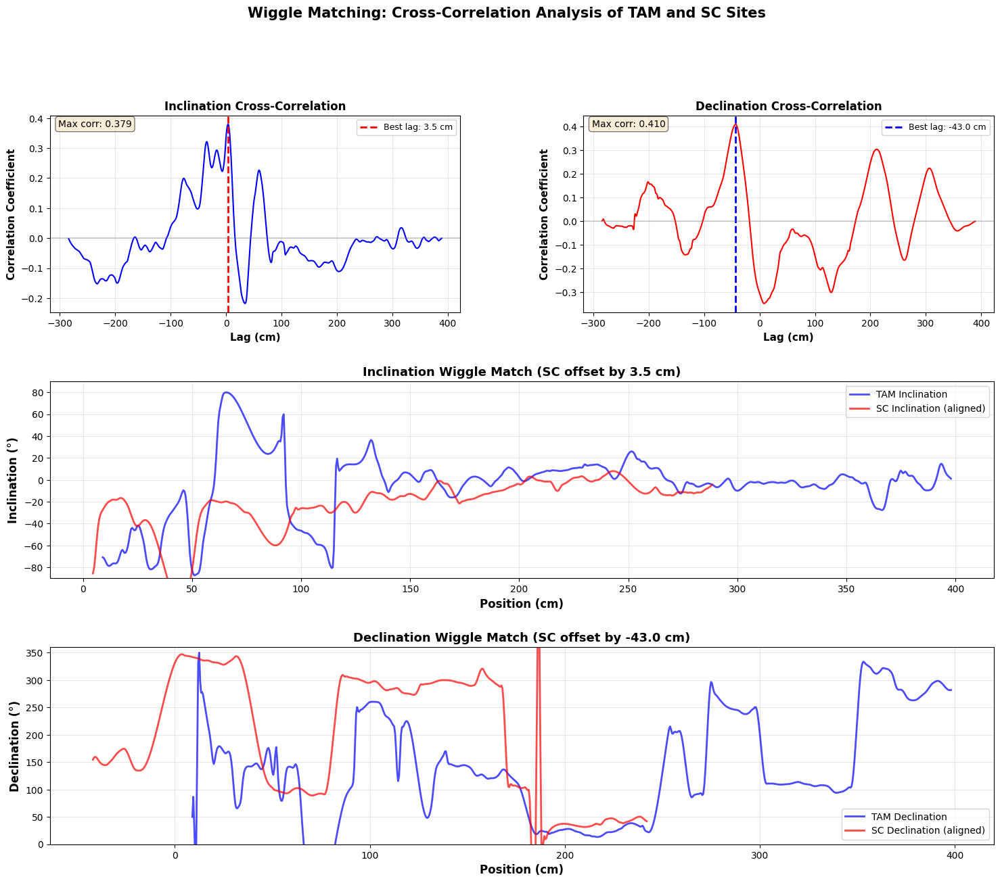


WIGGLE MATCHING SUMMARY

Optimal alignment offsets:
  Inclination: 3.5 cm (correlation: 0.379)
  Declination: -43.0 cm (correlation: 0.410)
  Average: -19.8 cm

Interpretation:
  SC should be shifted RIGHT by 3.5 cm relative to TAM

Correlation quality:
  Moderate correlation - some similarity


In [45]:
"""
Wiggle Matching: Cross-correlation between TAM and SC sites
Interpolates data to common spacing and finds optimal alignment
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy import interpolate, signal
import os

# Configure matplotlib
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable regions (foam-free)
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """Combine groups and keep only viable data."""
    combined_pca = []
    combined_int = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        paths = get_file_paths(sample_id)
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        pca_df_viable = pca_df.copy()
        pca_df_viable['viable'] = pca_df_viable['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_viable[pca_df_viable['viable']].copy()
        
        if len(pca_df_viable) == 0:
            continue
        
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_viable = int_df.copy()
            int_df_viable['viable'] = int_df_viable['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_viable[int_df_viable['viable']].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                combined_int.append(int_df_viable)
        
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
    
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df

# ============================================================================
# INTERPOLATION AND CROSS-CORRELATION FUNCTIONS
# ============================================================================

def interpolate_to_regular_grid(positions, values, spacing=0.5):
    """
    Interpolate irregular data to a regular grid.
    
    Parameters:
    -----------
    positions : array-like
        Original position values
    values : array-like
        Data values to interpolate
    spacing : float
        Spacing of the regular grid (default: 0.5 cm)
        
    Returns:
    --------
    new_positions : array
        Regular grid positions
    interpolated_values : array
        Interpolated values
    """
    # Remove NaN values
    mask = ~np.isnan(values)
    positions_clean = positions[mask]
    values_clean = values[mask]
    
    if len(positions_clean) < 2:
        return None, None
    
    # Create regular grid
    pos_min = positions_clean.min()
    pos_max = positions_clean.max()
    new_positions = np.arange(pos_min, pos_max + spacing, spacing)
    
    # Interpolate using cubic spline
    try:
        f = interpolate.interp1d(positions_clean, values_clean, kind='cubic', 
                                bounds_error=False, fill_value='extrapolate')
        interpolated_values = f(new_positions)
    except:
        # Fall back to linear if cubic fails
        f = interpolate.interp1d(positions_clean, values_clean, kind='linear',
                                bounds_error=False, fill_value='extrapolate')
        interpolated_values = f(new_positions)
    
    return new_positions, interpolated_values

def normalize_signal(signal_data):
    """Normalize signal to zero mean and unit variance."""
    return (signal_data - np.nanmean(signal_data)) / np.nanstd(signal_data)

def cross_correlate_signals(signal1, signal2):
    """
    Compute cross-correlation between two signals.
    
    Returns:
    --------
    lags : array
        Lag values
    correlation : array
        Correlation coefficients
    best_lag : int
        Lag with maximum correlation
    max_corr : float
        Maximum correlation coefficient
    """
    # Normalize signals
    s1_norm = normalize_signal(signal1)
    s2_norm = normalize_signal(signal2)
    
    # Compute cross-correlation
    correlation = signal.correlate(s1_norm, s2_norm, mode='full')
    correlation = correlation / len(s1_norm)  # Normalize
    
    # Create lag array
    lags = signal.correlation_lags(len(s1_norm), len(s2_norm), mode='full')
    
    # Find best lag
    best_lag_idx = np.argmax(correlation)
    best_lag = lags[best_lag_idx]
    max_corr = correlation[best_lag_idx]
    
    return lags, correlation, best_lag, max_corr

# ============================================================================
# WIGGLE MATCHING ANALYSIS
# ============================================================================

print("="*70)
print("WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS")
print("="*70)

# Load both sites
site_data = {}
for site_name, site_info in SITES.items():
    print(f"\nLoading {site_name}...")
    pca_df, int_df = combine_site_data_viable_only(site_info)
    if pca_df is not None and len(pca_df) > 0:
        site_data[site_name] = {'pca': pca_df, 'int': int_df}
        print(f"  Loaded {len(pca_df)} viable points")

if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing data for one or both sites")
else:
    tam_pca = site_data['Site 1 (TAM)']['pca']
    sc_pca = site_data['Site 2 (SC)']['pca']
    
    print("\n" + "="*70)
    print("STEP 1: INTERPOLATING TO REGULAR GRIDS")
    print("="*70)
    
    # Interpolate inclination
    spacing = 0.5  # 0.5 cm spacing
    
    tam_pos_inc, tam_inc_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Incl'].values, spacing
    )
    sc_pos_inc, sc_inc_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Incl'].values, spacing
    )
    
    # Interpolate declination
    tam_pos_dec, tam_dec_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Decl'].values, spacing
    )
    sc_pos_dec, sc_dec_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Decl'].values, spacing
    )
    
    print(f"\nTAM interpolated: {len(tam_pos_inc)} points at {spacing} cm spacing")
    print(f"SC interpolated: {len(sc_pos_inc)} points at {spacing} cm spacing")
    
    print("\n" + "="*70)
    print("STEP 2: CROSS-CORRELATION ANALYSIS")
    print("="*70)
    
    # Cross-correlate inclination
    lags_inc, corr_inc, best_lag_inc, max_corr_inc = cross_correlate_signals(
        tam_inc_interp, sc_inc_interp
    )
    
    # Cross-correlate declination
    lags_dec, corr_dec, best_lag_dec, max_corr_dec = cross_correlate_signals(
        tam_dec_interp, sc_dec_interp
    )
    
    # Convert lag indices to cm
    best_offset_inc = best_lag_inc * spacing
    best_offset_dec = best_lag_dec * spacing
    
    print(f"\nInclination:")
    print(f"  Best correlation: {max_corr_inc:.3f}")
    print(f"  Optimal lag: {best_lag_inc} points = {best_offset_inc:.1f} cm")
    
    print(f"\nDeclination:")
    print(f"  Best correlation: {max_corr_dec:.3f}")
    print(f"  Optimal lag: {best_lag_dec} points = {best_offset_dec:.1f} cm")
    
    # Use average offset
    avg_offset = (best_offset_inc + best_offset_dec) / 2
    print(f"\nAverage optimal offset: {avg_offset:.1f} cm")
    
    print("\n" + "="*70)
    print("STEP 3: VISUALIZATION")
    print("="*70)
    
    # Create comprehensive figure
    fig = plt.figure(figsize=(18, 14))
    gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)
    
    # ========================================================================
    # Plot 1: Cross-correlation functions
    # ========================================================================
    
    # Inclination correlation
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(lags_inc * spacing, corr_inc, 'b-', linewidth=1.5)
    ax1.axvline(x=best_offset_inc, color='r', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_inc:.1f} cm')
    ax1.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax1.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax1.set_title('Inclination Cross-Correlation', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=9)
    ax1.text(0.02, 0.98, f'Max corr: {max_corr_inc:.3f}',
             transform=ax1.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Declination correlation
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(lags_dec * spacing, corr_dec, 'r-', linewidth=1.5)
    ax2.axvline(x=best_offset_dec, color='b', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_dec:.1f} cm')
    ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax2.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax2.set_title('Declination Cross-Correlation', fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=9)
    ax2.text(0.02, 0.98, f'Max corr: {max_corr_dec:.3f}',
             transform=ax2.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # ========================================================================
    # Plot 2: Aligned inclination comparison
    # ========================================================================
    ax3 = fig.add_subplot(gs[1, :])
    
    # Plot TAM
    ax3.plot(tam_pos_inc, tam_inc_interp, 'b-', linewidth=2, 
             label='TAM Inclination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos = sc_pos_inc + best_offset_inc
    ax3.plot(sc_aligned_pos, sc_inc_interp, 'r-', linewidth=2,
             label='SC Inclination (aligned)', alpha=0.7)
    
    ax3.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold')
    ax3.set_title(f'Inclination Wiggle Match (SC offset by {best_offset_inc:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    ax3.legend(fontsize=10, loc='best')
    ax3.set_ylim([-90, 90])
    
    # ========================================================================
    # Plot 3: Aligned declination comparison
    # ========================================================================
    ax4 = fig.add_subplot(gs[2, :])
    
    # Plot TAM
    ax4.plot(tam_pos_dec, tam_dec_interp, 'b-', linewidth=2,
             label='TAM Declination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos_dec = sc_pos_dec + best_offset_dec
    ax4.plot(sc_aligned_pos_dec, sc_dec_interp, 'r-', linewidth=2,
             label='SC Declination (aligned)', alpha=0.7)
    
    ax4.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Declination (°)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Declination Wiggle Match (SC offset by {best_offset_dec:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    ax4.legend(fontsize=10, loc='best')
    ax4.set_ylim([0, 360])
    
    # Overall title
    fig.suptitle('Wiggle Matching: Cross-Correlation Analysis of TAM and SC Sites',
                 fontsize=15, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # ========================================================================
    # Print summary
    # ========================================================================
    print("\n" + "="*70)
    print("WIGGLE MATCHING SUMMARY")
    print("="*70)
    print(f"\nOptimal alignment offsets:")
    print(f"  Inclination: {best_offset_inc:.1f} cm (correlation: {max_corr_inc:.3f})")
    print(f"  Declination: {best_offset_dec:.1f} cm (correlation: {max_corr_dec:.3f})")
    print(f"  Average: {avg_offset:.1f} cm")
    print(f"\nInterpretation:")
    if best_offset_inc > 0:
        print(f"  SC should be shifted RIGHT by {abs(best_offset_inc):.1f} cm relative to TAM")
    else:
        print(f"  SC should be shifted LEFT by {abs(best_offset_inc):.1f} cm relative to TAM")
    print(f"\nCorrelation quality:")
    if max_corr_inc > 0.7:
        print("  Excellent correlation - strong match")
    elif max_corr_inc > 0.5:
        print("  Good correlation - reliable match")
    elif max_corr_inc > 0.3:
        print("  Moderate correlation - some similarity")
    else:
        print("  Weak correlation - limited similarity")

### wiggle matching no smoothing

WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS

Loading Site 1 (TAM)...
  Loaded 314 viable points

Loading Site 2 (SC)...
Error reading PCA file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loaded 205 viable points

STEP 1: INTERPOLATING TO REGULAR GRIDS (LINEAR - NO SMOOTHING)

TAM interpolated: 779 points at 0.5 cm spacing
SC interpolated: 569 points at 0.5 cm spacing

STEP 2: CROSS-CORRELATION ANALYSIS

Inclination:
  Best correlation: 0.380
  Optimal lag: 2 points = 1.0 cm

Declination:
  Best correlation: 0.394
  Optimal lag: -88 points = -44.0 cm

Average optimal offset: -21.5 cm

STEP 3: VISUALIZATION


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/706244795.py:397: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


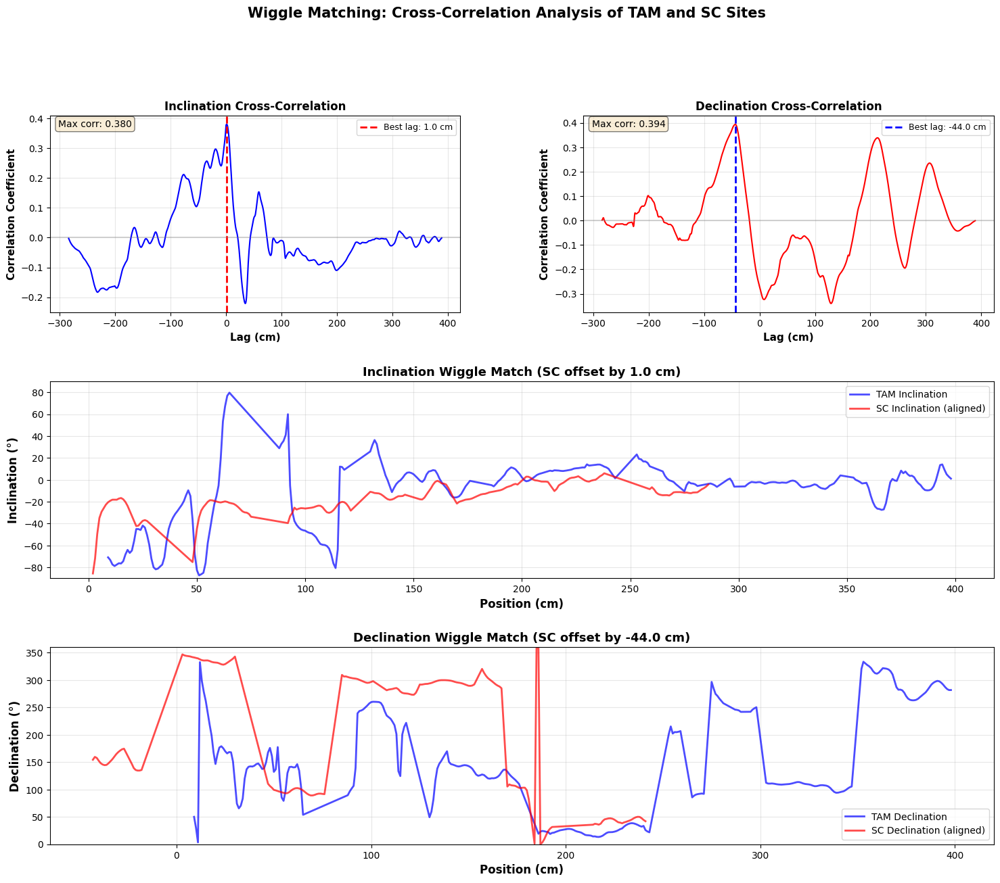


WIGGLE MATCHING SUMMARY

Optimal alignment offsets:
  Inclination: 1.0 cm (correlation: 0.380)
  Declination: -44.0 cm (correlation: 0.394)
  Average: -21.5 cm

Interpretation:
  SC should be shifted RIGHT by 1.0 cm relative to TAM

Correlation quality:
  Moderate correlation - some similarity


In [46]:
"""
Wiggle Matching: Cross-correlation between TAM and SC sites
Interpolates data to common spacing and finds optimal alignment
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy import interpolate, signal
import os

# Configure matplotlib
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable regions (foam-free)
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """Combine groups and keep only viable data."""
    combined_pca = []
    combined_int = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        paths = get_file_paths(sample_id)
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        pca_df_viable = pca_df.copy()
        pca_df_viable['viable'] = pca_df_viable['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_viable[pca_df_viable['viable']].copy()
        
        if len(pca_df_viable) == 0:
            continue
        
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_viable = int_df.copy()
            int_df_viable['viable'] = int_df_viable['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_viable[int_df_viable['viable']].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                combined_int.append(int_df_viable)
        
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
    
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df

# ============================================================================
# INTERPOLATION AND CROSS-CORRELATION FUNCTIONS
# ============================================================================

def interpolate_to_regular_grid(positions, values, spacing=0.5):
    """
    Interpolate irregular data to a regular grid using LINEAR interpolation only.
    No smoothing applied - data is already smoothed.
    
    Parameters:
    -----------
    positions : array-like
        Original position values
    values : array-like
        Data values to interpolate
    spacing : float
        Spacing of the regular grid (default: 0.5 cm)
        
    Returns:
    --------
    new_positions : array
        Regular grid positions
    interpolated_values : array
        Interpolated values
    """
    # Remove NaN values
    mask = ~np.isnan(values)
    positions_clean = positions[mask]
    values_clean = values[mask]
    
    if len(positions_clean) < 2:
        return None, None
    
    # Create regular grid
    pos_min = positions_clean.min()
    pos_max = positions_clean.max()
    new_positions = np.arange(pos_min, pos_max + spacing, spacing)
    
    # Interpolate using LINEAR interpolation only (no smoothing)
    f = interpolate.interp1d(positions_clean, values_clean, kind='linear',
                            bounds_error=False, fill_value='extrapolate')
    interpolated_values = f(new_positions)
    
    return new_positions, interpolated_values

def normalize_signal(signal_data):
    """Normalize signal to zero mean and unit variance."""
    return (signal_data - np.nanmean(signal_data)) / np.nanstd(signal_data)

def cross_correlate_signals(signal1, signal2):
    """
    Compute cross-correlation between two signals.
    
    Returns:
    --------
    lags : array
        Lag values
    correlation : array
        Correlation coefficients
    best_lag : int
        Lag with maximum correlation
    max_corr : float
        Maximum correlation coefficient
    """
    # Normalize signals
    s1_norm = normalize_signal(signal1)
    s2_norm = normalize_signal(signal2)
    
    # Compute cross-correlation
    correlation = signal.correlate(s1_norm, s2_norm, mode='full')
    correlation = correlation / len(s1_norm)  # Normalize
    
    # Create lag array
    lags = signal.correlation_lags(len(s1_norm), len(s2_norm), mode='full')
    
    # Find best lag
    best_lag_idx = np.argmax(correlation)
    best_lag = lags[best_lag_idx]
    max_corr = correlation[best_lag_idx]
    
    return lags, correlation, best_lag, max_corr

# ============================================================================
# WIGGLE MATCHING ANALYSIS
# ============================================================================

print("="*70)
print("WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS")
print("="*70)

# Load both sites
site_data = {}
for site_name, site_info in SITES.items():
    print(f"\nLoading {site_name}...")
    pca_df, int_df = combine_site_data_viable_only(site_info)
    if pca_df is not None and len(pca_df) > 0:
        site_data[site_name] = {'pca': pca_df, 'int': int_df}
        print(f"  Loaded {len(pca_df)} viable points")

if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing data for one or both sites")
else:
    tam_pca = site_data['Site 1 (TAM)']['pca']
    sc_pca = site_data['Site 2 (SC)']['pca']
    
    print("\n" + "="*70)
    print("STEP 1: INTERPOLATING TO REGULAR GRIDS (LINEAR - NO SMOOTHING)")
    print("="*70)
    
    # Interpolate inclination
    spacing = 0.5  # 0.5 cm spacing
    
    tam_pos_inc, tam_inc_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Incl'].values, spacing
    )
    sc_pos_inc, sc_inc_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Incl'].values, spacing
    )
    
    # Interpolate declination
    tam_pos_dec, tam_dec_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Decl'].values, spacing
    )
    sc_pos_dec, sc_dec_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Decl'].values, spacing
    )
    
    print(f"\nTAM interpolated: {len(tam_pos_inc)} points at {spacing} cm spacing")
    print(f"SC interpolated: {len(sc_pos_inc)} points at {spacing} cm spacing")
    
    print("\n" + "="*70)
    print("STEP 2: CROSS-CORRELATION ANALYSIS")
    print("="*70)
    
    # Cross-correlate inclination
    lags_inc, corr_inc, best_lag_inc, max_corr_inc = cross_correlate_signals(
        tam_inc_interp, sc_inc_interp
    )
    
    # Cross-correlate declination
    lags_dec, corr_dec, best_lag_dec, max_corr_dec = cross_correlate_signals(
        tam_dec_interp, sc_dec_interp
    )
    
    # Convert lag indices to cm
    best_offset_inc = best_lag_inc * spacing
    best_offset_dec = best_lag_dec * spacing
    
    print(f"\nInclination:")
    print(f"  Best correlation: {max_corr_inc:.3f}")
    print(f"  Optimal lag: {best_lag_inc} points = {best_offset_inc:.1f} cm")
    
    print(f"\nDeclination:")
    print(f"  Best correlation: {max_corr_dec:.3f}")
    print(f"  Optimal lag: {best_lag_dec} points = {best_offset_dec:.1f} cm")
    
    # Use average offset
    avg_offset = (best_offset_inc + best_offset_dec) / 2
    print(f"\nAverage optimal offset: {avg_offset:.1f} cm")
    
    print("\n" + "="*70)
    print("STEP 3: VISUALIZATION")
    print("="*70)
    
    # Create comprehensive figure
    fig = plt.figure(figsize=(18, 14))
    gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)
    
    # ========================================================================
    # Plot 1: Cross-correlation functions
    # ========================================================================
    
    # Inclination correlation
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(lags_inc * spacing, corr_inc, 'b-', linewidth=1.5)
    ax1.axvline(x=best_offset_inc, color='r', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_inc:.1f} cm')
    ax1.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax1.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax1.set_title('Inclination Cross-Correlation', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=9)
    ax1.text(0.02, 0.98, f'Max corr: {max_corr_inc:.3f}',
             transform=ax1.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Declination correlation
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(lags_dec * spacing, corr_dec, 'r-', linewidth=1.5)
    ax2.axvline(x=best_offset_dec, color='b', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_dec:.1f} cm')
    ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax2.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax2.set_title('Declination Cross-Correlation', fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=9)
    ax2.text(0.02, 0.98, f'Max corr: {max_corr_dec:.3f}',
             transform=ax2.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # ========================================================================
    # Plot 2: Aligned inclination comparison
    # ========================================================================
    ax3 = fig.add_subplot(gs[1, :])
    
    # Plot TAM
    ax3.plot(tam_pos_inc, tam_inc_interp, 'b-', linewidth=2, 
             label='TAM Inclination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos = sc_pos_inc + best_offset_inc
    ax3.plot(sc_aligned_pos, sc_inc_interp, 'r-', linewidth=2,
             label='SC Inclination (aligned)', alpha=0.7)
    
    ax3.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold')
    ax3.set_title(f'Inclination Wiggle Match (SC offset by {best_offset_inc:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    ax3.legend(fontsize=10, loc='best')
    ax3.set_ylim([-90, 90])
    
    # ========================================================================
    # Plot 3: Aligned declination comparison
    # ========================================================================
    ax4 = fig.add_subplot(gs[2, :])
    
    # Plot TAM
    ax4.plot(tam_pos_dec, tam_dec_interp, 'b-', linewidth=2,
             label='TAM Declination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos_dec = sc_pos_dec + best_offset_dec
    ax4.plot(sc_aligned_pos_dec, sc_dec_interp, 'r-', linewidth=2,
             label='SC Declination (aligned)', alpha=0.7)
    
    ax4.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Declination (°)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Declination Wiggle Match (SC offset by {best_offset_dec:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    ax4.legend(fontsize=10, loc='best')
    ax4.set_ylim([0, 360])
    
    # Overall title
    fig.suptitle('Wiggle Matching: Cross-Correlation Analysis of TAM and SC Sites',
                 fontsize=15, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # ========================================================================
    # Print summary
    # ========================================================================
    print("\n" + "="*70)
    print("WIGGLE MATCHING SUMMARY")
    print("="*70)
    print(f"\nOptimal alignment offsets:")
    print(f"  Inclination: {best_offset_inc:.1f} cm (correlation: {max_corr_inc:.3f})")
    print(f"  Declination: {best_offset_dec:.1f} cm (correlation: {max_corr_dec:.3f})")
    print(f"  Average: {avg_offset:.1f} cm")
    print(f"\nInterpretation:")
    if best_offset_inc > 0:
        print(f"  SC should be shifted RIGHT by {abs(best_offset_inc):.1f} cm relative to TAM")
    else:
        print(f"  SC should be shifted LEFT by {abs(best_offset_inc):.1f} cm relative to TAM")
    print(f"\nCorrelation quality:")
    if max_corr_inc > 0.7:
        print("  Excellent correlation - strong match")
    elif max_corr_inc > 0.5:
        print("  Good correlation - reliable match")
    elif max_corr_inc > 0.3:
        print("  Moderate correlation - some similarity")
    else:
        print("  Weak correlation - limited similarity")

WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS

Loading Site 1 (TAM)...
  Loaded 314 viable points

Loading Site 2 (SC)...
Error reading PCA file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loaded 205 viable points

STEP 1: INTERPOLATING TO REGULAR GRIDS (LINEAR - NO SMOOTHING)

TAM interpolated: 779 points at 0.5 cm spacing
SC interpolated: 569 points at 0.5 cm spacing

STEP 2: CROSS-CORRELATION ANALYSIS

Inclination:
  Best correlation: 0.380
  Optimal lag: 2 points = 1.0 cm

Declination:
  Best correlation: 0.394
  Optimal lag: -88 points = -44.0 cm

Average optimal offset: -21.5 cm

STEP 3: VISUALIZATION


/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/706244795.py:397: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


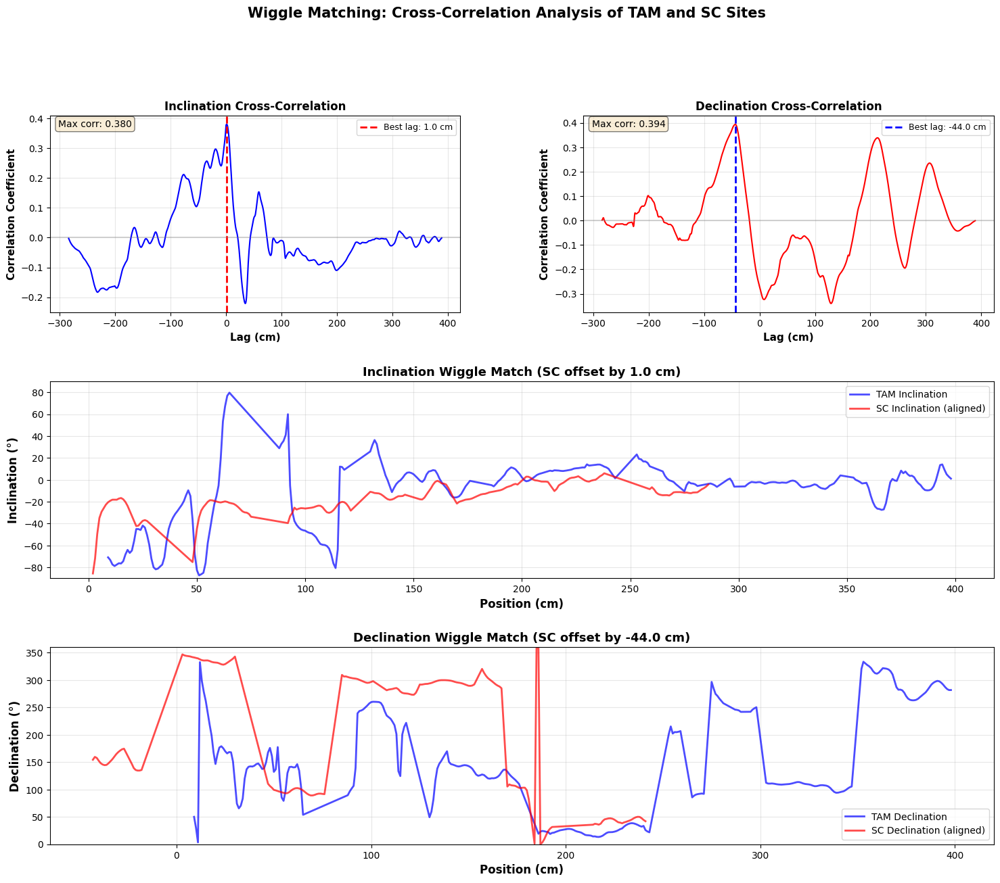


WIGGLE MATCHING SUMMARY

Optimal alignment offsets:
  Inclination: 1.0 cm (correlation: 0.380)
  Declination: -44.0 cm (correlation: 0.394)
  Average: -21.5 cm

Interpretation:
  SC should be shifted RIGHT by 1.0 cm relative to TAM

Correlation quality:
  Moderate correlation - some similarity


In [48]:
"""
Wiggle Matching: Cross-correlation between TAM and SC sites
Interpolates data to common spacing and finds optimal alignment
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy import interpolate, signal
import os

# Configure matplotlib
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable regions (foam-free)
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """Combine groups and keep only viable data."""
    combined_pca = []
    combined_int = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        paths = get_file_paths(sample_id)
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        pca_df_viable = pca_df.copy()
        pca_df_viable['viable'] = pca_df_viable['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_viable[pca_df_viable['viable']].copy()
        
        if len(pca_df_viable) == 0:
            continue
        
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_viable = int_df.copy()
            int_df_viable['viable'] = int_df_viable['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_viable[int_df_viable['viable']].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                combined_int.append(int_df_viable)
        
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
    
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df

# ============================================================================
# INTERPOLATION AND CROSS-CORRELATION FUNCTIONS
# ============================================================================

def interpolate_to_regular_grid(positions, values, spacing=0.5):
    """
    Interpolate irregular data to a regular grid using LINEAR interpolation only.
    No smoothing applied - data is already smoothed.
    
    Parameters:
    -----------
    positions : array-like
        Original position values
    values : array-like
        Data values to interpolate
    spacing : float
        Spacing of the regular grid (default: 0.5 cm)
        
    Returns:
    --------
    new_positions : array
        Regular grid positions
    interpolated_values : array
        Interpolated values
    """
    # Remove NaN values
    mask = ~np.isnan(values)
    positions_clean = positions[mask]
    values_clean = values[mask]
    
    if len(positions_clean) < 2:
        return None, None
    
    # Create regular grid
    pos_min = positions_clean.min()
    pos_max = positions_clean.max()
    new_positions = np.arange(pos_min, pos_max + spacing, spacing)
    
    # Interpolate using LINEAR interpolation only (no smoothing)
    f = interpolate.interp1d(positions_clean, values_clean, kind='linear',
                            bounds_error=False, fill_value='extrapolate')
    interpolated_values = f(new_positions)
    
    return new_positions, interpolated_values

def normalize_signal(signal_data):
    """Normalize signal to zero mean and unit variance."""
    return (signal_data - np.nanmean(signal_data)) / np.nanstd(signal_data)

def cross_correlate_signals(signal1, signal2):
    """
    Compute cross-correlation between two signals.
    
    Returns:
    --------
    lags : array
        Lag values
    correlation : array
        Correlation coefficients
    best_lag : int
        Lag with maximum correlation
    max_corr : float
        Maximum correlation coefficient
    """
    # Normalize signals
    s1_norm = normalize_signal(signal1)
    s2_norm = normalize_signal(signal2)
    
    # Compute cross-correlation
    correlation = signal.correlate(s1_norm, s2_norm, mode='full')
    correlation = correlation / len(s1_norm)  # Normalize
    
    # Create lag array
    lags = signal.correlation_lags(len(s1_norm), len(s2_norm), mode='full')
    
    # Find best lag
    best_lag_idx = np.argmax(correlation)
    best_lag = lags[best_lag_idx]
    max_corr = correlation[best_lag_idx]
    
    return lags, correlation, best_lag, max_corr

# ============================================================================
# WIGGLE MATCHING ANALYSIS
# ============================================================================

print("="*70)
print("WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION ANALYSIS")
print("="*70)

# Load both sites
site_data = {}
for site_name, site_info in SITES.items():
    print(f"\nLoading {site_name}...")
    pca_df, int_df = combine_site_data_viable_only(site_info)
    if pca_df is not None and len(pca_df) > 0:
        site_data[site_name] = {'pca': pca_df, 'int': int_df}
        print(f"  Loaded {len(pca_df)} viable points")

if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing data for one or both sites")
else:
    tam_pca = site_data['Site 1 (TAM)']['pca']
    sc_pca = site_data['Site 2 (SC)']['pca']
    
    print("\n" + "="*70)
    print("STEP 1: INTERPOLATING TO REGULAR GRIDS (LINEAR - NO SMOOTHING)")
    print("="*70)
    
    # Interpolate inclination
    spacing = 0.5  # 0.5 cm spacing
    
    tam_pos_inc, tam_inc_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Incl'].values, spacing
    )
    sc_pos_inc, sc_inc_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Incl'].values, spacing
    )
    
    # Interpolate declination
    tam_pos_dec, tam_dec_interp = interpolate_to_regular_grid(
        tam_pca['position'].values, tam_pca['Decl'].values, spacing
    )
    sc_pos_dec, sc_dec_interp = interpolate_to_regular_grid(
        sc_pca['position'].values, sc_pca['Decl'].values, spacing
    )
    
    print(f"\nTAM interpolated: {len(tam_pos_inc)} points at {spacing} cm spacing")
    print(f"SC interpolated: {len(sc_pos_inc)} points at {spacing} cm spacing")
    
    print("\n" + "="*70)
    print("STEP 2: CROSS-CORRELATION ANALYSIS")
    print("="*70)
    
    # Cross-correlate inclination
    lags_inc, corr_inc, best_lag_inc, max_corr_inc = cross_correlate_signals(
        tam_inc_interp, sc_inc_interp
    )
    
    # Cross-correlate declination
    lags_dec, corr_dec, best_lag_dec, max_corr_dec = cross_correlate_signals(
        tam_dec_interp, sc_dec_interp
    )
    
    # Convert lag indices to cm
    best_offset_inc = best_lag_inc * spacing
    best_offset_dec = best_lag_dec * spacing
    
    print(f"\nInclination:")
    print(f"  Best correlation: {max_corr_inc:.3f}")
    print(f"  Optimal lag: {best_lag_inc} points = {best_offset_inc:.1f} cm")
    
    print(f"\nDeclination:")
    print(f"  Best correlation: {max_corr_dec:.3f}")
    print(f"  Optimal lag: {best_lag_dec} points = {best_offset_dec:.1f} cm")
    
    # Use average offset
    avg_offset = (best_offset_inc + best_offset_dec) / 2
    print(f"\nAverage optimal offset: {avg_offset:.1f} cm")
    
    print("\n" + "="*70)
    print("STEP 3: VISUALIZATION")
    print("="*70)
    
    # Create comprehensive figure
    fig = plt.figure(figsize=(18, 14))
    gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], hspace=0.35, wspace=0.3)
    
    # ========================================================================
    # Plot 1: Cross-correlation functions
    # ========================================================================
    
    # Inclination correlation
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(lags_inc * spacing, corr_inc, 'b-', linewidth=1.5)
    ax1.axvline(x=best_offset_inc, color='r', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_inc:.1f} cm')
    ax1.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax1.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax1.set_title('Inclination Cross-Correlation', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=9)
    ax1.text(0.02, 0.98, f'Max corr: {max_corr_inc:.3f}',
             transform=ax1.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # Declination correlation
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(lags_dec * spacing, corr_dec, 'r-', linewidth=1.5)
    ax2.axvline(x=best_offset_dec, color='b', linestyle='--', linewidth=2,
                label=f'Best lag: {best_offset_dec:.1f} cm')
    ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
    ax2.set_xlabel('Lag (cm)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Correlation Coefficient', fontsize=11, fontweight='bold')
    ax2.set_title('Declination Cross-Correlation', fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=9)
    ax2.text(0.02, 0.98, f'Max corr: {max_corr_dec:.3f}',
             transform=ax2.transAxes, fontsize=10, verticalalignment='top',
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    # ========================================================================
    # Plot 2: Aligned inclination comparison
    # ========================================================================
    ax3 = fig.add_subplot(gs[1, :])
    
    # Plot TAM
    ax3.plot(tam_pos_inc, tam_inc_interp, 'b-', linewidth=2, 
             label='TAM Inclination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos = sc_pos_inc + best_offset_inc
    ax3.plot(sc_aligned_pos, sc_inc_interp, 'r-', linewidth=2,
             label='SC Inclination (aligned)', alpha=0.7)
    
    ax3.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold')
    ax3.set_title(f'Inclination Wiggle Match (SC offset by {best_offset_inc:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax3.grid(True, alpha=0.3)
    ax3.legend(fontsize=10, loc='best')
    ax3.set_ylim([-90, 90])
    
    # ========================================================================
    # Plot 3: Aligned declination comparison
    # ========================================================================
    ax4 = fig.add_subplot(gs[2, :])
    
    # Plot TAM
    ax4.plot(tam_pos_dec, tam_dec_interp, 'b-', linewidth=2,
             label='TAM Declination', alpha=0.7)
    
    # Plot SC with optimal offset
    sc_aligned_pos_dec = sc_pos_dec + best_offset_dec
    ax4.plot(sc_aligned_pos_dec, sc_dec_interp, 'r-', linewidth=2,
             label='SC Declination (aligned)', alpha=0.7)
    
    ax4.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
    ax4.set_ylabel('Declination (°)', fontsize=12, fontweight='bold')
    ax4.set_title(f'Declination Wiggle Match (SC offset by {best_offset_dec:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax4.grid(True, alpha=0.3)
    ax4.legend(fontsize=10, loc='best')
    ax4.set_ylim([0, 360])
    
    # Overall title
    fig.suptitle('Wiggle Matching: Cross-Correlation Analysis of TAM and SC Sites',
                 fontsize=15, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # ========================================================================
    # Print summary
    # ========================================================================
    print("\n" + "="*70)
    print("WIGGLE MATCHING SUMMARY")
    print("="*70)
    print(f"\nOptimal alignment offsets:")
    print(f"  Inclination: {best_offset_inc:.1f} cm (correlation: {max_corr_inc:.3f})")
    print(f"  Declination: {best_offset_dec:.1f} cm (correlation: {max_corr_dec:.3f})")
    print(f"  Average: {avg_offset:.1f} cm")
    print(f"\nInterpretation:")
    if best_offset_inc > 0:
        print(f"  SC should be shifted RIGHT by {abs(best_offset_inc):.1f} cm relative to TAM")
    else:
        print(f"  SC should be shifted LEFT by {abs(best_offset_inc):.1f} cm relative to TAM")
    print(f"\nCorrelation quality:")
    if max_corr_inc > 0.7:
        print("  Excellent correlation - strong match")
    elif max_corr_inc > 0.5:
        print("  Good correlation - reliable match")
    elif max_corr_inc > 0.3:
        print("  Moderate correlation - some similarity")
    else:
        print("  Weak correlation - limited similarity")

INTENSITY WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION

Loading Site 1 (TAM) intensity data...
  Loaded 216 viable intensity points

Loading Site 2 (SC) intensity data...
Error reading INT file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/int/SE_3B_3A_4D_4C_4B_4A_NRM_01202026.NRM.int'
Error reading PCA file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loaded 205 viable intensity points

STEP 1: INTERPOLATING INTENSITY TO REGULAR GRIDS (LINEAR - NO SMOOTHING)

TAM interpolated: 517 points at 0.5 cm spacing
  Intensity range: 8.85e-08 to 1.56e-06 A/m
SC interpolated: 569 points at 0.5 cm spacing
  Intensity range: 3.05e-08 to 1.33e-06 A/m

STEP 2: CROSS-CORRELATION ANALYSIS

Intensity (300 mT):
  Best correlation: 0.373
  Optimal lag: -142 points = -71.0 cm

STEP 3: VISUALIZATI

/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/2213471845.py:338: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


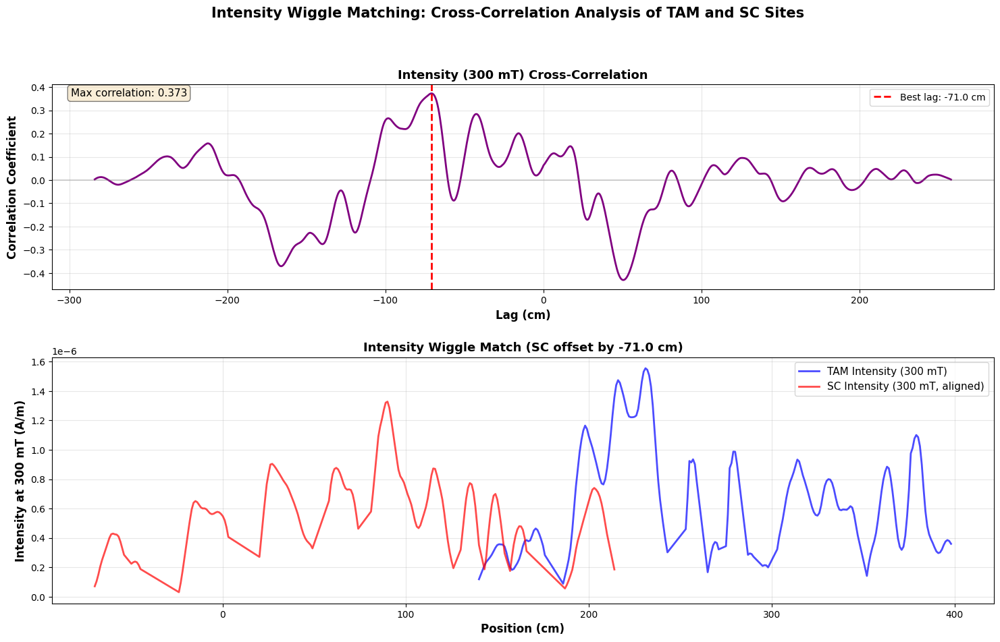


INTENSITY WIGGLE MATCHING SUMMARY

Optimal alignment offset:
  -71.0 cm (correlation: 0.373)

Interpretation:
  SC should be shifted LEFT by 71.0 cm relative to TAM

Correlation quality:
  Moderate correlation - some intensity similarity

Data quality:
  TAM: 216 viable points
  SC: 205 viable points
  Note: Group 1 (TAM 1 2 3B) excluded - no intensity data available


In [49]:
"""
Wiggle Matching: Intensity Cross-correlation between TAM and SC sites
Uses intensity at 300 mT for correlation analysis
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy import interpolate, signal
import os

# Configure matplotlib
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),  # Skip - no intensity
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable regions (foam-free)
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_intensity_viable_only(site_info):
    """Combine groups and keep only viable intensity data."""
    combined_int = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        if skip_mad_int:
            # Skip groups without intensity data
            # Still need to update offset based on PCA length
            paths = get_file_paths(sample_id)
            pca_df = read_pca_file(paths['pca'])
            if pca_df is not None:
                max_pos = pca_df['position'].max()
                current_offset += max_pos + 1
            continue
            
        paths = get_file_paths(sample_id)
        int_df = read_int_file(paths['int'])
        
        if int_df is None or 'Int 300' not in int_df.columns:
            # Update offset even if no data
            pca_df = read_pca_file(paths['pca'])
            if pca_df is not None:
                max_pos = pca_df['position'].max()
                current_offset += max_pos + 1
            continue
        
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        int_df_viable = int_df.copy()
        int_df_viable['viable'] = int_df_viable['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        int_df_viable = int_df_viable[int_df_viable['viable']].copy()
        
        if len(int_df_viable) == 0:
            # Update offset
            pca_df = read_pca_file(paths['pca'])
            if pca_df is not None:
                max_pos = pca_df['position'].max()
                current_offset += max_pos + 1
            continue
        
        # Convert intensity to numeric
        int_df_viable['Int 300'] = pd.to_numeric(int_df_viable['Int 300'], errors='coerce')
        
        # Adjust positions by adding offset
        int_df_viable['position'] = int_df_viable['position'] + current_offset
        int_df_viable['group'] = group_name
        combined_int.append(int_df_viable)
        
        # Update offset for next group
        pca_df = read_pca_file(paths['pca'])
        if pca_df is not None:
            max_pos = pca_df['position'].max()
            current_offset += max_pos + 1
    
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_int_df

# ============================================================================
# INTERPOLATION AND CROSS-CORRELATION FUNCTIONS
# ============================================================================

def interpolate_to_regular_grid(positions, values, spacing=0.5):
    """
    Interpolate irregular data to a regular grid using LINEAR interpolation only.
    No smoothing applied - data is already smoothed.
    """
    # Remove NaN values
    mask = ~np.isnan(values)
    positions_clean = positions[mask]
    values_clean = values[mask]
    
    if len(positions_clean) < 2:
        return None, None
    
    # Create regular grid
    pos_min = positions_clean.min()
    pos_max = positions_clean.max()
    new_positions = np.arange(pos_min, pos_max + spacing, spacing)
    
    # Interpolate using LINEAR interpolation only (no smoothing)
    f = interpolate.interp1d(positions_clean, values_clean, kind='linear',
                            bounds_error=False, fill_value='extrapolate')
    interpolated_values = f(new_positions)
    
    return new_positions, interpolated_values

def normalize_signal(signal_data):
    """Normalize signal to zero mean and unit variance."""
    return (signal_data - np.nanmean(signal_data)) / np.nanstd(signal_data)

def cross_correlate_signals(signal1, signal2):
    """
    Compute cross-correlation between two signals.
    
    Returns:
    --------
    lags : array
        Lag values
    correlation : array
        Correlation coefficients
    best_lag : int
        Lag with maximum correlation
    max_corr : float
        Maximum correlation coefficient
    """
    # Normalize signals
    s1_norm = normalize_signal(signal1)
    s2_norm = normalize_signal(signal2)
    
    # Compute cross-correlation
    correlation = signal.correlate(s1_norm, s2_norm, mode='full')
    correlation = correlation / len(s1_norm)  # Normalize
    
    # Create lag array
    lags = signal.correlation_lags(len(s1_norm), len(s2_norm), mode='full')
    
    # Find best lag
    best_lag_idx = np.argmax(correlation)
    best_lag = lags[best_lag_idx]
    max_corr = correlation[best_lag_idx]
    
    return lags, correlation, best_lag, max_corr

# ============================================================================
# INTENSITY WIGGLE MATCHING ANALYSIS
# ============================================================================

print("="*70)
print("INTENSITY WIGGLE MATCHING: TAM vs SC CROSS-CORRELATION")
print("="*70)

# Load both sites - intensity data only
site_data = {}
for site_name, site_info in SITES.items():
    print(f"\nLoading {site_name} intensity data...")
    int_df = combine_site_intensity_viable_only(site_info)
    if int_df is not None and len(int_df) > 0:
        site_data[site_name] = int_df
        print(f"  Loaded {len(int_df)} viable intensity points")
    else:
        print(f"  Warning: No intensity data for {site_name}")

if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing intensity data for one or both sites")
else:
    tam_int = site_data['Site 1 (TAM)']
    sc_int = site_data['Site 2 (SC)']
    
    print("\n" + "="*70)
    print("STEP 1: INTERPOLATING INTENSITY TO REGULAR GRIDS (LINEAR - NO SMOOTHING)")
    print("="*70)
    
    # Interpolate intensity at 300 mT
    spacing = 0.5  # 0.5 cm spacing
    
    tam_pos, tam_int_interp = interpolate_to_regular_grid(
        tam_int['position'].values, tam_int['Int 300'].values, spacing
    )
    sc_pos, sc_int_interp = interpolate_to_regular_grid(
        sc_int['position'].values, sc_int['Int 300'].values, spacing
    )
    
    if tam_pos is None or sc_pos is None:
        print("\nError: Could not interpolate intensity data")
    else:
        print(f"\nTAM interpolated: {len(tam_pos)} points at {spacing} cm spacing")
        print(f"  Intensity range: {np.nanmin(tam_int_interp):.2e} to {np.nanmax(tam_int_interp):.2e} A/m")
        print(f"SC interpolated: {len(sc_pos)} points at {spacing} cm spacing")
        print(f"  Intensity range: {np.nanmin(sc_int_interp):.2e} to {np.nanmax(sc_int_interp):.2e} A/m")
        
        print("\n" + "="*70)
        print("STEP 2: CROSS-CORRELATION ANALYSIS")
        print("="*70)
        
        # Cross-correlate intensity
        lags, corr, best_lag, max_corr = cross_correlate_signals(
            tam_int_interp, sc_int_interp
        )
        
        # Convert lag indices to cm
        best_offset = best_lag * spacing
        
        print(f"\nIntensity (300 mT):")
        print(f"  Best correlation: {max_corr:.3f}")
        print(f"  Optimal lag: {best_lag} points = {best_offset:.1f} cm")
        
        print("\n" + "="*70)
        print("STEP 3: VISUALIZATION")
        print("="*70)
        
        # Create comprehensive figure
        fig = plt.figure(figsize=(18, 10))
        gs = gridspec.GridSpec(2, 1, height_ratios=[1, 1.2], hspace=0.3)
        
        # ====================================================================
        # Plot 1: Cross-correlation function
        # ====================================================================
        ax1 = fig.add_subplot(gs[0])
        ax1.plot(lags * spacing, corr, 'purple', linewidth=2)
        ax1.axvline(x=best_offset, color='r', linestyle='--', linewidth=2,
                    label=f'Best lag: {best_offset:.1f} cm')
        ax1.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
        ax1.set_xlabel('Lag (cm)', fontsize=12, fontweight='bold')
        ax1.set_ylabel('Correlation Coefficient', fontsize=12, fontweight='bold')
        ax1.set_title('Intensity (300 mT) Cross-Correlation', fontsize=13, fontweight='bold')
        ax1.grid(True, alpha=0.3)
        ax1.legend(fontsize=10)
        ax1.text(0.02, 0.98, f'Max correlation: {max_corr:.3f}',
                 transform=ax1.transAxes, fontsize=11, verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        
        # ====================================================================
        # Plot 2: Aligned intensity comparison
        # ====================================================================
        ax2 = fig.add_subplot(gs[1])
        
        # Plot TAM
        ax2.plot(tam_pos, tam_int_interp, 'b-', linewidth=2, 
                 label='TAM Intensity (300 mT)', alpha=0.7)
        
        # Plot SC with optimal offset
        sc_aligned_pos = sc_pos + best_offset
        ax2.plot(sc_aligned_pos, sc_int_interp, 'r-', linewidth=2,
                 label='SC Intensity (300 mT, aligned)', alpha=0.7)
        
        ax2.set_xlabel('Position (cm)', fontsize=12, fontweight='bold')
        ax2.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, fontweight='bold')
        ax2.set_title(f'Intensity Wiggle Match (SC offset by {best_offset:.1f} cm)',
                      fontsize=13, fontweight='bold')
        ax2.grid(True, alpha=0.3)
        ax2.legend(fontsize=11, loc='best')
        ax2.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
        
        # Overall title
        fig.suptitle('Intensity Wiggle Matching: Cross-Correlation Analysis of TAM and SC Sites',
                     fontsize=15, fontweight='bold', y=0.995)
        
        plt.tight_layout(rect=[0, 0, 1, 0.99])
        plt.show()
        
        # ====================================================================
        # Print summary
        # ====================================================================
        print("\n" + "="*70)
        print("INTENSITY WIGGLE MATCHING SUMMARY")
        print("="*70)
        print(f"\nOptimal alignment offset:")
        print(f"  {best_offset:.1f} cm (correlation: {max_corr:.3f})")
        print(f"\nInterpretation:")
        if best_offset > 0:
            print(f"  SC should be shifted RIGHT by {abs(best_offset):.1f} cm relative to TAM")
        else:
            print(f"  SC should be shifted LEFT by {abs(best_offset):.1f} cm relative to TAM")
        print(f"\nCorrelation quality:")
        if max_corr > 0.7:
            print("  Excellent correlation - strong intensity match")
        elif max_corr > 0.5:
            print("  Good correlation - reliable intensity match")
        elif max_corr > 0.3:
            print("  Moderate correlation - some intensity similarity")
        else:
            print("  Weak correlation - limited intensity similarity")
        
        print(f"\nData quality:")
        print(f"  TAM: {len(tam_int)} viable points")
        print(f"  SC: {len(sc_int)} viable points")
        print(f"  Note: Group 1 (TAM 1 2 3B) excluded - no intensity data available")

NORMALIZED WIGGLE MATCHING: TAM vs SC (Both 0-450 cm)

Loading Site 1 (TAM)...
  Loaded 314 viable PCA points
  Loaded 216 viable intensity points

Loading Site 2 (SC)...
Error reading PCA file: [Errno 2] No such file or directory: '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data/dir/pca/PCA - SE_3B_3A_4D_4C_4B_4A_NRM_01202026 (100-1000).txt'
  Loaded 205 viable PCA points
  Loaded 205 viable intensity points

STEP 1: NORMALIZING POSITIONS TO 0-450 cm

TAM: 9.0-398.0 cm → 0-450 cm
SC: 1.0-285.0 cm → 0-450 cm

STEP 2: INTERPOLATING TO REGULAR GRIDS

Interpolated data (all at 1.0 cm spacing):
  TAM Inc/Dec: 451 points
  SC Inc/Dec: 451 points
  TAM Intensity: 451 points
  SC Intensity: 451 points

STEP 3: CROSS-CORRELATION ANALYSIS

Inclination:
  Best correlation: 0.445
  Optimal offset: -22.0 cm

Declination:
  Best correlation: 0.320
  Optimal offset: -171.0 cm

Intensity (300 mT):
  Best correlation: 0.385
  Optimal offset: -120.0 cm

STEP 4: VISUALIZA

/var/folders/_x/g3vxcwzx3kz2c43v6_q7vsj40000gn/T/ipykernel_38918/1184239041.py:386: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.99])


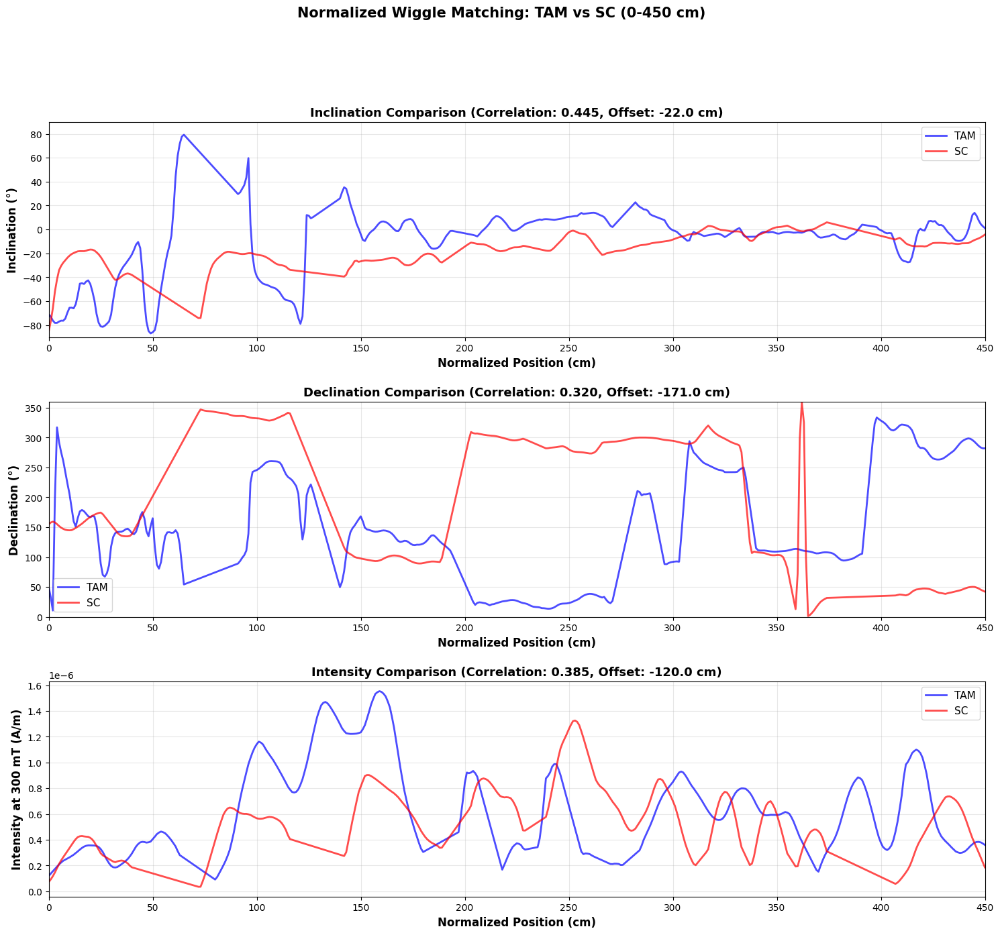


SUMMARY

Both cores normalized to 0-450 cm for direct comparison

Correlation results:
  Inclination: 0.445 (offset: -22.0 cm)
  Declination: 0.320 (offset: -171.0 cm)
  Intensity: 0.385 (offset: -120.0 cm)

Note: Low TAM Group 1 intensity excluded from intensity analysis


In [50]:
"""
Wiggle Matching: TAM vs SC with Normalized Position Scale
Both cores normalized to 0-450 cm range for direct comparison
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy import interpolate, signal
import os

# Configure matplotlib
%matplotlib inline

# ============================================================================
# CONFIGURATION
# ============================================================================

BASE_DIR = '/Users/nicolasanderson/Documents/GitHub/Peru/OSU_uchannel_magnetometer_NRM_data'

# Define sites with their component groups
SITES = {
    'Site 1 (TAM)': {
        'groups': [
            ('Group 1: TAM 1 2 3B', 'TAM_1_2_3B_NRM_01192026', True),
            ('Group 2: TAM 3A 4 5E 5D 5C', 'TAM_3A_4_5E_5D_5C_NRM_01192026', False),
            ('Group 3: TAM 5B 5A 6 7', 'TAM_5B_5A_6_7_NRM_01202026', False)
        ]
    },
    'Site 2 (SC)': {
        'groups': [
            ('Group 4: SC 1C 1B 1A 2 3C', 'SC_1C_1B_1A_2_3C_NRM_01212026', False),
            ('Group 5: SC 3B 3A 4D 4C 4B 4A', 'SE_3B_3A_4D_4C_4B_4A_NRM_01202026', False),
            ('Group 6: SC 5 6 7C 7B 7A', 'SC_5_6_7C_7B_7A_NRM_01212026', False),
            ('Group 7: SC 8', 'SC_8_NRM_01212026', False)
        ]
    }
}

# Define viable regions (foam-free)
VIABLE_REGIONS = {
    'Group 1: TAM 1 2 3B': [[9.0, 65.8], [87.3, 118.0], [130.0, 139.1]],
    'Group 2: TAM 3A 4 5E 5D 5C': [[0.0, 36.0], [46.0, 103.0], [112.5, 119.9], 
                                     [125.0, 131.0], [134.5, 141.5]],
    'Group 3: TAM 5B 5A 6 7': [[2.5, 6.2], [10.5, 14.8], [18.4, 63.8], [67.3, 114.8]],
    'Group 4: SC 1C 1B 1A 2 3C': [[1.0, 17.5], [21.0, 26.5], [47.0, 74.0], [90.7, 120.0]],
    'Group 5: SC 3B 3A 4D 4C 4B 4A': [[1.5, 24.5], [31.1, 45.0], [52.0, 64.5], 
                                       [71.8, 87.0], [89.0, 112.0], [114.5, 136.2]],
    'Group 6: SC 5 6 7C 7B 7A': [[2.5, 19.5], [26.0, 71.0], [75.0, 85.5], 
                                  [88.0, 99.0], [102.0, 111.5]],
    'Group 7: SC 8': [[15.0, 42.0]]
}

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_file_paths(sample_id):
    """Get all file paths for a sample."""
    return {
        'pca': os.path.join(BASE_DIR, 'dir', 'pca', f'PCA - {sample_id} (100-1000).txt'),
        'int': os.path.join(BASE_DIR, 'int', f'{sample_id}.NRM.int'),
    }

def read_pca_file(filepath):
    """Read PCA file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position(cm)' in df.columns:
            df = df.rename(columns={'Position(cm)': 'position'})
        return df
    except Exception as e:
        print(f"Error reading PCA file: {e}")
        return None

def read_int_file(filepath):
    """Read intensity file."""
    try:
        df = pd.read_csv(filepath, sep='\t')
        df.columns = df.columns.str.strip()
        if 'Position' in df.columns:
            df = df.rename(columns={'Position': 'position'})
        return df
    except Exception as e:
        print(f"Error reading INT file: {e}")
        return None

def is_viable_position(position, viable_ranges):
    """Check if a position falls within any viable range."""
    for start, end in viable_ranges:
        if start <= position <= end:
            return True
    return False

def combine_site_data_viable_only(site_info):
    """Combine groups and keep only viable data."""
    combined_pca = []
    combined_int = []
    current_offset = 0
    
    for group_name, sample_id, skip_mad_int in site_info['groups']:
        paths = get_file_paths(sample_id)
        pca_df = read_pca_file(paths['pca'])
        if pca_df is None:
            continue
            
        if not skip_mad_int:
            int_df = read_int_file(paths['int'])
        else:
            int_df = None
        
        viable_ranges = VIABLE_REGIONS.get(group_name, [])
        
        pca_df_viable = pca_df.copy()
        pca_df_viable['viable'] = pca_df_viable['position'].apply(
            lambda pos: is_viable_position(pos, viable_ranges)
        )
        pca_df_viable = pca_df_viable[pca_df_viable['viable']].copy()
        
        if len(pca_df_viable) == 0:
            max_pos = pca_df['position'].max()
            current_offset += max_pos + 1
            continue
        
        pca_df_viable['position'] = pca_df_viable['position'] + current_offset
        combined_pca.append(pca_df_viable)
        
        if int_df is not None:
            int_df_viable = int_df.copy()
            int_df_viable['viable'] = int_df_viable['position'].apply(
                lambda pos: is_viable_position(pos, viable_ranges)
            )
            int_df_viable = int_df_viable[int_df_viable['viable']].copy()
            
            if len(int_df_viable) > 0:
                int_df_viable['Int 300'] = pd.to_numeric(int_df_viable['Int 300'], errors='coerce')
                int_df_viable['position'] = int_df_viable['position'] + current_offset
                combined_int.append(int_df_viable)
        
        max_pos = pca_df['position'].max()
        current_offset += max_pos + 1
    
    combined_pca_df = pd.concat(combined_pca, ignore_index=True) if combined_pca else None
    combined_int_df = pd.concat(combined_int, ignore_index=True) if combined_int else None
    
    return combined_pca_df, combined_int_df

def normalize_positions(positions, target_min=0, target_max=450):
    """
    Normalize positions to span target range.
    
    Parameters:
    -----------
    positions : array
        Original positions
    target_min : float
        Target minimum (default: 0)
    target_max : float
        Target maximum (default: 450)
    """
    pos_min = positions.min()
    pos_max = positions.max()
    
    # Linear transformation to [target_min, target_max]
    normalized = (positions - pos_min) / (pos_max - pos_min) * (target_max - target_min) + target_min
    
    return normalized

def interpolate_to_regular_grid(positions, values, spacing=1.0):
    """Linear interpolation to regular grid."""
    mask = ~np.isnan(values)
    positions_clean = positions[mask]
    values_clean = values[mask]
    
    if len(positions_clean) < 2:
        return None, None
    
    pos_min = positions_clean.min()
    pos_max = positions_clean.max()
    new_positions = np.arange(pos_min, pos_max + spacing, spacing)
    
    f = interpolate.interp1d(positions_clean, values_clean, kind='linear',
                            bounds_error=False, fill_value='extrapolate')
    interpolated_values = f(new_positions)
    
    return new_positions, interpolated_values

def normalize_signal(signal_data):
    """Normalize signal to zero mean and unit variance."""
    return (signal_data - np.nanmean(signal_data)) / np.nanstd(signal_data)

def cross_correlate_signals(signal1, signal2):
    """Compute cross-correlation between two signals."""
    s1_norm = normalize_signal(signal1)
    s2_norm = normalize_signal(signal2)
    
    correlation = signal.correlate(s1_norm, s2_norm, mode='full')
    correlation = correlation / len(s1_norm)
    
    lags = signal.correlation_lags(len(s1_norm), len(s2_norm), mode='full')
    
    best_lag_idx = np.argmax(correlation)
    best_lag = lags[best_lag_idx]
    max_corr = correlation[best_lag_idx]
    
    return lags, correlation, best_lag, max_corr

# ============================================================================
# NORMALIZED WIGGLE MATCHING
# ============================================================================

print("="*70)
print("NORMALIZED WIGGLE MATCHING: TAM vs SC (Both 0-450 cm)")
print("="*70)

# Load both sites
site_data = {}
for site_name, site_info in SITES.items():
    print(f"\nLoading {site_name}...")
    pca_df, int_df = combine_site_data_viable_only(site_info)
    if pca_df is not None and len(pca_df) > 0:
        site_data[site_name] = {'pca': pca_df, 'int': int_df}
        print(f"  Loaded {len(pca_df)} viable PCA points")
        if int_df is not None and len(int_df) > 0:
            print(f"  Loaded {len(int_df)} viable intensity points")

if 'Site 1 (TAM)' not in site_data or 'Site 2 (SC)' not in site_data:
    print("\nError: Missing data for one or both sites")
else:
    tam_pca = site_data['Site 1 (TAM)']['pca']
    tam_int = site_data['Site 1 (TAM)']['int']
    sc_pca = site_data['Site 2 (SC)']['pca']
    sc_int = site_data['Site 2 (SC)']['int']
    
    print("\n" + "="*70)
    print("STEP 1: NORMALIZING POSITIONS TO 0-450 cm")
    print("="*70)
    
    # Normalize positions for both sites
    tam_pca['norm_pos'] = normalize_positions(tam_pca['position'].values, 0, 450)
    sc_pca['norm_pos'] = normalize_positions(sc_pca['position'].values, 0, 450)
    
    if tam_int is not None:
        tam_int['norm_pos'] = normalize_positions(tam_int['position'].values, 0, 450)
    if sc_int is not None:
        sc_int['norm_pos'] = normalize_positions(sc_int['position'].values, 0, 450)
    
    print(f"\nTAM: {tam_pca['position'].min():.1f}-{tam_pca['position'].max():.1f} cm → 0-450 cm")
    print(f"SC: {sc_pca['position'].min():.1f}-{sc_pca['position'].max():.1f} cm → 0-450 cm")
    
    print("\n" + "="*70)
    print("STEP 2: INTERPOLATING TO REGULAR GRIDS")
    print("="*70)
    
    spacing = 1.0  # 1 cm spacing for 0-450 range
    
    # Interpolate Inc/Dec
    tam_pos_inc, tam_inc_interp = interpolate_to_regular_grid(
        tam_pca['norm_pos'].values, tam_pca['Incl'].values, spacing
    )
    sc_pos_inc, sc_inc_interp = interpolate_to_regular_grid(
        sc_pca['norm_pos'].values, sc_pca['Incl'].values, spacing
    )
    
    tam_pos_dec, tam_dec_interp = interpolate_to_regular_grid(
        tam_pca['norm_pos'].values, tam_pca['Decl'].values, spacing
    )
    sc_pos_dec, sc_dec_interp = interpolate_to_regular_grid(
        sc_pca['norm_pos'].values, sc_pca['Decl'].values, spacing
    )
    
    # Interpolate intensity
    if tam_int is not None and len(tam_int) > 0:
        tam_pos_int, tam_int_interp = interpolate_to_regular_grid(
            tam_int['norm_pos'].values, tam_int['Int 300'].values, spacing
        )
    else:
        tam_pos_int, tam_int_interp = None, None
        
    if sc_int is not None and len(sc_int) > 0:
        sc_pos_int, sc_int_interp = interpolate_to_regular_grid(
            sc_int['norm_pos'].values, sc_int['Int 300'].values, spacing
        )
    else:
        sc_pos_int, sc_int_interp = None, None
    
    print(f"\nInterpolated data (all at {spacing} cm spacing):")
    print(f"  TAM Inc/Dec: {len(tam_pos_inc)} points")
    print(f"  SC Inc/Dec: {len(sc_pos_inc)} points")
    if tam_pos_int is not None:
        print(f"  TAM Intensity: {len(tam_pos_int)} points")
    if sc_pos_int is not None:
        print(f"  SC Intensity: {len(sc_pos_int)} points")
    
    print("\n" + "="*70)
    print("STEP 3: CROSS-CORRELATION ANALYSIS")
    print("="*70)
    
    # Cross-correlate inclination
    lags_inc, corr_inc, best_lag_inc, max_corr_inc = cross_correlate_signals(
        tam_inc_interp, sc_inc_interp
    )
    best_offset_inc = best_lag_inc * spacing
    
    # Cross-correlate declination
    lags_dec, corr_dec, best_lag_dec, max_corr_dec = cross_correlate_signals(
        tam_dec_interp, sc_dec_interp
    )
    best_offset_dec = best_lag_dec * spacing
    
    print(f"\nInclination:")
    print(f"  Best correlation: {max_corr_inc:.3f}")
    print(f"  Optimal offset: {best_offset_inc:.1f} cm")
    
    print(f"\nDeclination:")
    print(f"  Best correlation: {max_corr_dec:.3f}")
    print(f"  Optimal offset: {best_offset_dec:.1f} cm")
    
    # Cross-correlate intensity if available
    if tam_pos_int is not None and sc_pos_int is not None:
        lags_int, corr_int, best_lag_int, max_corr_int = cross_correlate_signals(
            tam_int_interp, sc_int_interp
        )
        best_offset_int = best_lag_int * spacing
        print(f"\nIntensity (300 mT):")
        print(f"  Best correlation: {max_corr_int:.3f}")
        print(f"  Optimal offset: {best_offset_int:.1f} cm")
    else:
        lags_int, corr_int, best_lag_int, max_corr_int = None, None, None, None
        best_offset_int = None
    
    print("\n" + "="*70)
    print("STEP 4: VISUALIZATION")
    print("="*70)
    
    # Create figure
    n_plots = 3 if best_offset_int is not None else 2
    fig = plt.figure(figsize=(18, 5*n_plots))
    gs = gridspec.GridSpec(n_plots, 1, hspace=0.3)
    
    # Plot 1: Inclination
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(tam_pos_inc, tam_inc_interp, 'b-', linewidth=2, label='TAM', alpha=0.7)
    ax1.plot(sc_pos_inc, sc_inc_interp, 'r-', linewidth=2, label='SC', alpha=0.7)
    ax1.set_xlabel('Normalized Position (cm)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Inclination (°)', fontsize=12, fontweight='bold')
    ax1.set_title(f'Inclination Comparison (Correlation: {max_corr_inc:.3f}, Offset: {best_offset_inc:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=11)
    ax1.set_xlim([0, 450])
    ax1.set_ylim([-90, 90])
    
    # Plot 2: Declination
    ax2 = fig.add_subplot(gs[1])
    ax2.plot(tam_pos_dec, tam_dec_interp, 'b-', linewidth=2, label='TAM', alpha=0.7)
    ax2.plot(sc_pos_dec, sc_dec_interp, 'r-', linewidth=2, label='SC', alpha=0.7)
    ax2.set_xlabel('Normalized Position (cm)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Declination (°)', fontsize=12, fontweight='bold')
    ax2.set_title(f'Declination Comparison (Correlation: {max_corr_dec:.3f}, Offset: {best_offset_dec:.1f} cm)',
                  fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=11)
    ax2.set_xlim([0, 450])
    ax2.set_ylim([0, 360])
    
    # Plot 3: Intensity (if available)
    if best_offset_int is not None:
        ax3 = fig.add_subplot(gs[2])
        ax3.plot(tam_pos_int, tam_int_interp, 'b-', linewidth=2, label='TAM', alpha=0.7)
        ax3.plot(sc_pos_int, sc_int_interp, 'r-', linewidth=2, label='SC', alpha=0.7)
        ax3.set_xlabel('Normalized Position (cm)', fontsize=12, fontweight='bold')
        ax3.set_ylabel('Intensity at 300 mT (A/m)', fontsize=12, fontweight='bold')
        ax3.set_title(f'Intensity Comparison (Correlation: {max_corr_int:.3f}, Offset: {best_offset_int:.1f} cm)',
                      fontsize=13, fontweight='bold')
        ax3.grid(True, alpha=0.3)
        ax3.legend(fontsize=11)
        ax3.set_xlim([0, 450])
        ax3.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
    
    fig.suptitle('Normalized Wiggle Matching: TAM vs SC (0-450 cm)',
                 fontsize=15, fontweight='bold', y=0.995)
    
    plt.tight_layout(rect=[0, 0, 1, 0.99])
    plt.show()
    
    # Summary
    print("\n" + "="*70)
    print("SUMMARY")
    print("="*70)
    print("\nBoth cores normalized to 0-450 cm for direct comparison")
    print("\nCorrelation results:")
    print(f"  Inclination: {max_corr_inc:.3f} (offset: {best_offset_inc:.1f} cm)")
    print(f"  Declination: {max_corr_dec:.3f} (offset: {best_offset_dec:.1f} cm)")
    if best_offset_int is not None:
        print(f"  Intensity: {max_corr_int:.3f} (offset: {best_offset_int:.1f} cm)")
    
    print("\nNote: Low TAM Group 1 intensity excluded from intensity analysis")

## ODP Leg 202 Site 1237 Core Data


original: /Users/nicolasanderson/Documents/GitHub/Peru/Cryomag 202 1237 B 200_320m.pdf  
corrected: /Users/nicolasanderson/Documents/GitHub/Peru/ODP_202_1237_220_300_mag_data_corrected.csv  
read: /Users/nicolasanderson/Documents/GitHub/Peru/Refining Holocene geochronologies using palaeomagnetic records : Quaternary Geochronology, 2019.pdf

Iquitos to Acre = 500 km
Iquitos to ODP 202 site 1237 = 1500 km


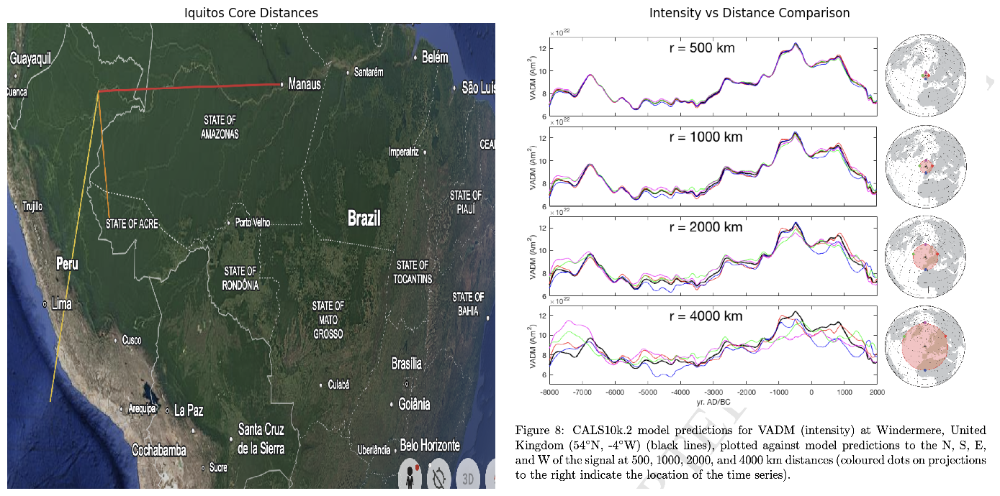

In [9]:
img_path_iquitos = '/Users/nicolasanderson/Documents/GitHub/Peru/Iquitos_core_distances.png'
img_path = '/Users/nicolasanderson/Documents/GitHub/Peru/intensity_distance_comparison.png'

# display the two images side-by-side using existing variables if available
# (avoid re-importing modules already imported in the notebook)
if 'img_iquitos' not in globals():
    img_iquitos = plt.imread(img_path_iquitos)
if 'img' not in globals():
    img = plt.imread(img_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(img_iquitos, aspect='auto', interpolation='nearest')
axes[0].set_title('Iquitos Core Distances')
axes[0].axis('off')

axes[1].imshow(img, aspect='auto', interpolation='nearest')
axes[1].set_title('Intensity vs Distance Comparison')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Figure 8: CALS10k.2 model predictions for VADM (intensity) at Windermere, United
Kingdom (54◦N, -4◦W) (black lines), plotted against model predictions to the N, S, E,
and W of the signal at 500, 1000, 2000, and 4000 km distances (coloured dots on projections
to the right indicate the location of the time series).

### Leg 202 Site 1237 Raw Data

Total rows: 7141
Rows after filtering (Demag_Level != 0): 4751

Demag levels in filtered data: [np.int64(20), np.int64(25)]

Plot saved successfully!

=== Data Statistics (filtered) ===
Depth range: 200.070 - 319.190 mbsf
Declination range: 0.1 - 360.0 degrees
Inclination range: -89.3 - 88.5 degrees
X intensity range: -1.058e-02 - 2.456e-02 A/m
Y intensity range: -4.104e-02 - 1.053e-02 A/m
Z intensity range: -2.432e-02 - 1.212e-02 A/m


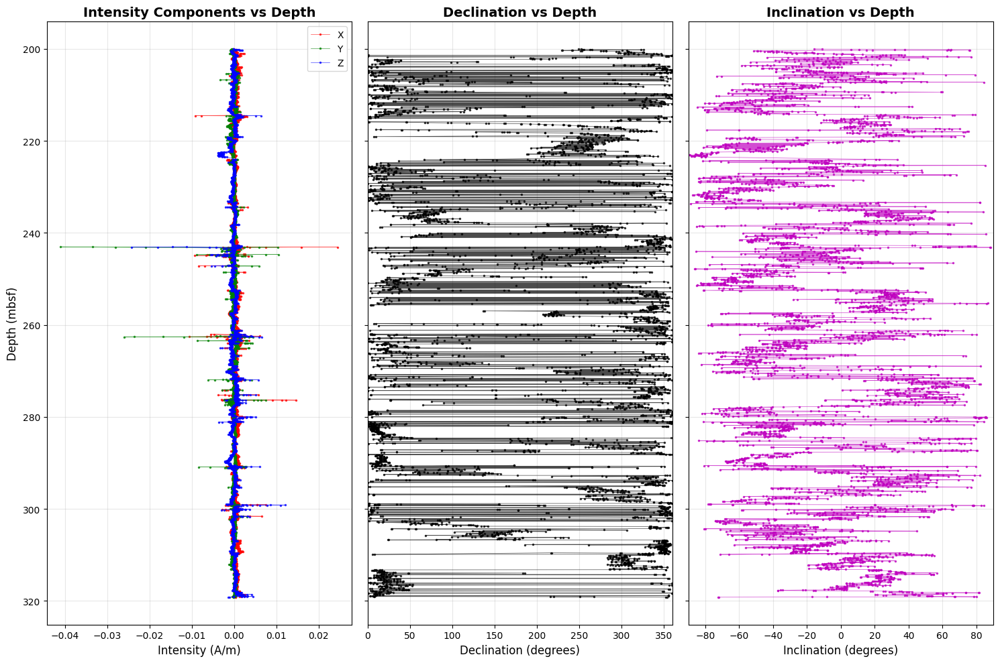

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read the corrected CSV file
df = pd.read_csv('/Users/nicolasanderson/Documents/GitHub/Peru/ODP_202_1237_220_300_mag_data_corrected.csv')

# Filter out rows where Demag_Level(mT) = 0
df_filtered = df[df['Demag_Level(mT)'] != 0].copy()

print(f"Total rows: {len(df)}")
print(f"Rows after filtering (Demag_Level != 0): {len(df_filtered)}")
print(f"\nDemag levels in filtered data: {sorted(df_filtered['Demag_Level(mT)'].unique())}")

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True)

# Plot 1: X, Y, Z intensities vs depth
ax1 = axes[0]
ax1.plot(df_filtered['Intensity_X(A/m)'], df_filtered['Depth(mbsf)'], 'r.-', label='X', markersize=3, linewidth=0.5, alpha=0.7)
ax1.plot(df_filtered['Intensity_Y(A/m)'], df_filtered['Depth(mbsf)'], 'g.-', label='Y', markersize=3, linewidth=0.5, alpha=0.7)
ax1.plot(df_filtered['Intensity_Z(A/m)'], df_filtered['Depth(mbsf)'], 'b.-', label='Z', markersize=3, linewidth=0.5, alpha=0.7)
ax1.set_xlabel('Intensity (A/m)', fontsize=12)
ax1.set_ylabel('Depth (mbsf)', fontsize=12)
ax1.set_title('Intensity Components vs Depth', fontsize=14, fontweight='bold')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)
ax1.invert_yaxis()  # Depth increases downward

# Plot 2: Declination vs depth
ax2 = axes[1]
ax2.plot(df_filtered['Decl(deg)'], df_filtered['Depth(mbsf)'], 'k.-', markersize=3, linewidth=0.5, alpha=0.7)
ax2.set_xlabel('Declination (degrees)', fontsize=12)
ax2.set_title('Declination vs Depth', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 360)

# Plot 3: Inclination vs depth
ax3 = axes[2]
ax3.plot(df_filtered['Incl(deg)'], df_filtered['Depth(mbsf)'], 'm.-', markersize=3, linewidth=0.5, alpha=0.7)
ax3.set_xlabel('Inclination (degrees)', fontsize=12)
ax3.set_title('Inclination vs Depth', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.set_xlim(-90, 90)

plt.tight_layout()
#plt.savefig('/mnt/user-data/outputs/magnetometer_plots.png', dpi=300, bbox_inches='tight')
print("\nPlot saved successfully!")

# Print some statistics
print("\n=== Data Statistics (filtered) ===")
print(f"Depth range: {df_filtered['Depth(mbsf)'].min():.3f} - {df_filtered['Depth(mbsf)'].max():.3f} mbsf")
print(f"Declination range: {df_filtered['Decl(deg)'].min():.1f} - {df_filtered['Decl(deg)'].max():.1f} degrees")
print(f"Inclination range: {df_filtered['Incl(deg)'].min():.1f} - {df_filtered['Incl(deg)'].max():.1f} degrees")
print(f"X intensity range: {df_filtered['Intensity_X(A/m)'].min():.3e} - {df_filtered['Intensity_X(A/m)'].max():.3e} A/m")
print(f"Y intensity range: {df_filtered['Intensity_Y(A/m)'].min():.3e} - {df_filtered['Intensity_Y(A/m)'].max():.3e} A/m")
print(f"Z intensity range: {df_filtered['Intensity_Z(A/m)'].min():.3e} - {df_filtered['Intensity_Z(A/m)'].max():.3e} A/m")

### Signal Processing and Smoothing


Plot saved successfully!

=== Data Statistics (filtered) ===
Depth range: 200.070 - 319.190 mbsf
Declination range: 0.1 - 360.0 degrees
Inclination range: -89.3 - 88.5 degrees
X intensity range: -1.058e-02 - 2.456e-02 A/m
Y intensity range: -4.104e-02 - 1.053e-02 A/m
Z intensity range: -2.432e-02 - 1.212e-02 A/m


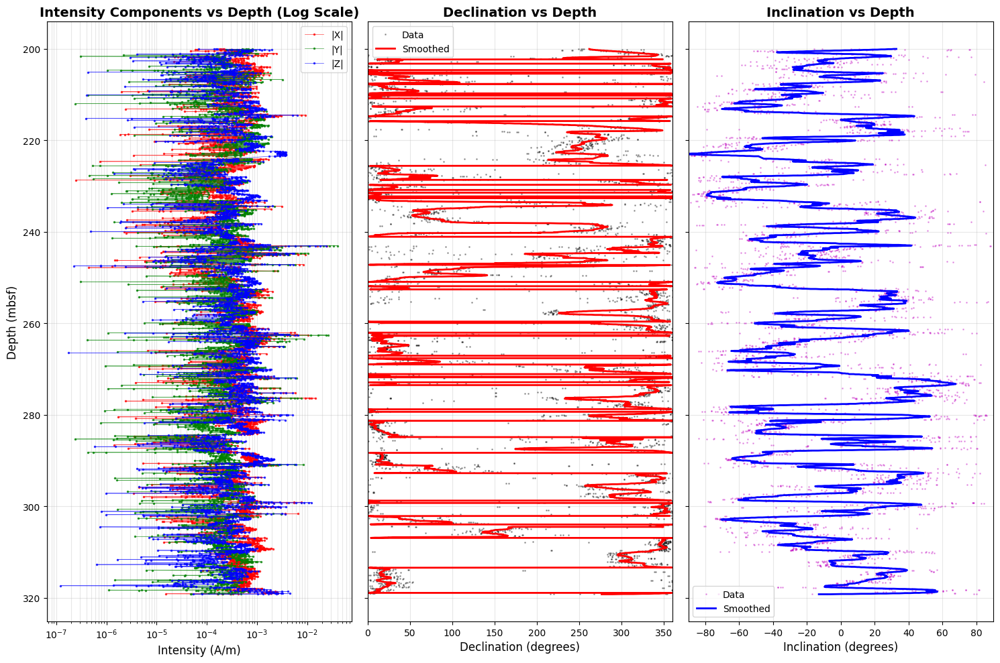

In [11]:
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True)

# Plot 1: X, Y, Z intensities vs depth (log scale)
ax1 = axes[0]
# Use absolute values for log scale
ax1.plot(np.abs(df_filtered['Intensity_X(A/m)']), df_filtered['Depth(mbsf)'], 'r.-', label='|X|', markersize=3, linewidth=0.5, alpha=0.7)
ax1.plot(np.abs(df_filtered['Intensity_Y(A/m)']), df_filtered['Depth(mbsf)'], 'g.-', label='|Y|', markersize=3, linewidth=0.5, alpha=0.7)
ax1.plot(np.abs(df_filtered['Intensity_Z(A/m)']), df_filtered['Depth(mbsf)'], 'b.-', label='|Z|', markersize=3, linewidth=0.5, alpha=0.7)
ax1.set_xlabel('Intensity (A/m)', fontsize=12)
ax1.set_ylabel('Depth (mbsf)', fontsize=12)
ax1.set_title('Intensity Components vs Depth (Log Scale)', fontsize=14, fontweight='bold')
ax1.set_xscale('log')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3, which='both')
ax1.invert_yaxis()  # Depth increases downward

# Plot 2: Declination vs depth with smoothed curve
ax2 = axes[1]
# Sort by depth for proper smoothing
df_sorted = df_filtered.sort_values('Depth(mbsf)')
depth_sorted = df_sorted['Depth(mbsf)'].values
decl_sorted = df_sorted['Decl(deg)'].values

# Handle the circular nature of declination (0-360 wrap-around)
# Convert to radians and use sin/cos to smooth
decl_rad = np.deg2rad(decl_sorted)
decl_sin = np.sin(decl_rad)
decl_cos = np.cos(decl_rad)

# Apply Savitzky-Golay filter
window_length = min(51, len(decl_sorted) if len(decl_sorted) % 2 == 1 else len(decl_sorted) - 1)
if window_length < 5:
    window_length = 5
decl_sin_smooth = savgol_filter(decl_sin, window_length, 3)
decl_cos_smooth = savgol_filter(decl_cos, window_length, 3)

# Convert back to degrees
decl_smooth = np.rad2deg(np.arctan2(decl_sin_smooth, decl_cos_smooth)) % 360

# Plot raw data and smoothed curve
ax2.plot(decl_sorted, depth_sorted, 'k.', markersize=2, alpha=0.3, label='Data')
ax2.plot(decl_smooth, depth_sorted, 'r-', linewidth=2, label='Smoothed')
ax2.set_xlabel('Declination (degrees)', fontsize=12)
ax2.set_title('Declination vs Depth', fontsize=14, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 360)

# Plot 3: Inclination vs depth with smoothed curve
ax3 = axes[2]
incl_sorted = df_sorted['Incl(deg)'].values

# Apply Savitzky-Golay filter to inclination
incl_smooth = savgol_filter(incl_sorted, window_length, 3)

# Plot raw data and smoothed curve
ax3.plot(incl_sorted, depth_sorted, 'm.', markersize=2, alpha=0.3, label='Data')
ax3.plot(incl_smooth, depth_sorted, 'b-', linewidth=2, label='Smoothed')
ax3.set_xlabel('Inclination (degrees)', fontsize=12)
ax3.set_title('Inclination vs Depth', fontsize=14, fontweight='bold')
ax3.legend(loc='best')
ax3.grid(True, alpha=0.3)
ax3.set_xlim(-90, 90)

plt.tight_layout()
#plt.savefig('/mnt/user-data/outputs/magnetometer_plots.png', dpi=300, bbox_inches='tight')
print("\nPlot saved successfully!")

# Print some statistics
print("\n=== Data Statistics (filtered) ===")
print(f"Depth range: {df_filtered['Depth(mbsf)'].min():.3f} - {df_filtered['Depth(mbsf)'].max():.3f} mbsf")
print(f"Declination range: {df_filtered['Decl(deg)'].min():.1f} - {df_filtered['Decl(deg)'].max():.1f} degrees")
print(f"Inclination range: {df_filtered['Incl(deg)'].min():.1f} - {df_filtered['Incl(deg)'].max():.1f} degrees")
print(f"X intensity range: {df_filtered['Intensity_X(A/m)'].min():.3e} - {df_filtered['Intensity_X(A/m)'].max():.3e} A/m")
print(f"Y intensity range: {df_filtered['Intensity_Y(A/m)'].min():.3e} - {df_filtered['Intensity_Y(A/m)'].max():.3e} A/m")
print(f"Z intensity range: {df_filtered['Intensity_Z(A/m)'].min():.3e} - {df_filtered['Intensity_Z(A/m)'].max():.3e} A/m")


Plot saved successfully!

=== Data Statistics (filtered) ===
Depth range: 200.070 - 319.190 mbsf
Declination range: 0.1 - 360.0 degrees
Inclination range: -89.3 - 88.5 degrees
X intensity range: -1.058e-02 - 2.456e-02 A/m
Y intensity range: -4.104e-02 - 1.053e-02 A/m
Z intensity range: -2.432e-02 - 1.212e-02 A/m


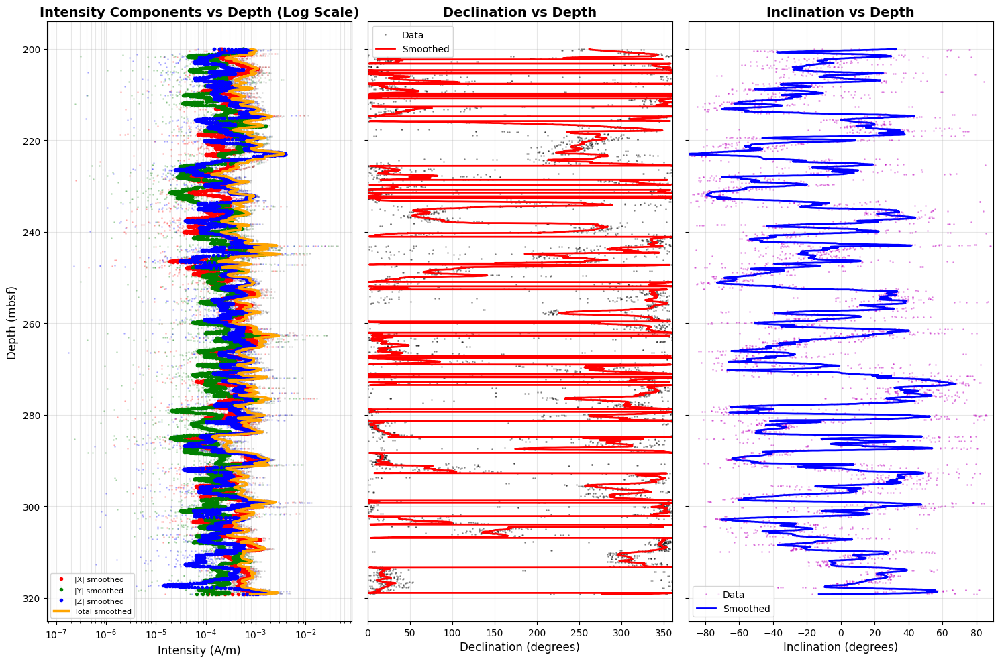

In [12]:

from scipy.signal import savgol_filter
from scipy.interpolate import UnivariateSpline

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True)

# Plot 1: X, Y, Z intensities vs depth (log scale)
ax1 = axes[0]
# Sort by depth for proper smoothing
df_sorted_int = df_filtered.sort_values('Depth(mbsf)')
depth_sorted_int = df_sorted_int['Depth(mbsf)'].values

# Get intensity components
intensity_x = np.abs(df_sorted_int['Intensity_X(A/m)'].values)
intensity_y = np.abs(df_sorted_int['Intensity_Y(A/m)'].values)
intensity_z = np.abs(df_sorted_int['Intensity_Z(A/m)'].values)

# Calculate total intensity (vector magnitude)
intensity_total = np.sqrt(intensity_x**2 + intensity_y**2 + intensity_z**2)

# Apply smoothing (use log values for better smoothing on log scale)
window_length_int = min(51, len(depth_sorted_int) if len(depth_sorted_int) % 2 == 1 else len(depth_sorted_int) - 1)
if window_length_int < 5:
    window_length_int = 5

intensity_x_smooth = np.exp(savgol_filter(np.log(intensity_x + 1e-10), window_length_int, 3))
intensity_y_smooth = np.exp(savgol_filter(np.log(intensity_y + 1e-10), window_length_int, 3))
intensity_z_smooth = np.exp(savgol_filter(np.log(intensity_z + 1e-10), window_length_int, 3))
intensity_total_smooth = np.exp(savgol_filter(np.log(intensity_total + 1e-10), window_length_int, 3))

# Plot raw data points
ax1.plot(intensity_x, depth_sorted_int, 'r.', markersize=2, alpha=0.2)
ax1.plot(intensity_y, depth_sorted_int, 'g.', markersize=2, alpha=0.2)
ax1.plot(intensity_z, depth_sorted_int, 'b.', markersize=2, alpha=0.2)
ax1.plot(intensity_total, depth_sorted_int, 'gray', marker='.', markersize=2, alpha=0.2, linestyle='none')

# Plot smoothed curves
ax1.plot(intensity_x_smooth, depth_sorted_int, 'r.', linewidth=1, label='|X| smoothed')
ax1.plot(intensity_y_smooth, depth_sorted_int, 'g.', linewidth=1, label='|Y| smoothed')
ax1.plot(intensity_z_smooth, depth_sorted_int, 'b.', linewidth=1, label='|Z| smoothed')
ax1.plot(intensity_total_smooth, depth_sorted_int, 'orange', linewidth=2.5, label='Total smoothed')

ax1.set_xlabel('Intensity (A/m)', fontsize=12)
ax1.set_ylabel('Depth (mbsf)', fontsize=12)
ax1.set_title('Intensity Components vs Depth (Log Scale)', fontsize=14, fontweight='bold')
ax1.set_xscale('log')
ax1.legend(loc='best', fontsize=8)
ax1.grid(True, alpha=0.3, which='both')
ax1.invert_yaxis()  # Depth increases downward

# Plot 2: Declination vs depth with smoothed curve
ax2 = axes[1]
# Sort by depth for proper smoothing
df_sorted = df_filtered.sort_values('Depth(mbsf)')
depth_sorted = df_sorted['Depth(mbsf)'].values
decl_sorted = df_sorted['Decl(deg)'].values

# Handle the circular nature of declination (0-360 wrap-around)
# Convert to radians and use sin/cos to smooth
decl_rad = np.deg2rad(decl_sorted)
decl_sin = np.sin(decl_rad)
decl_cos = np.cos(decl_rad)

# Apply Savitzky-Golay filter
window_length = min(51, len(decl_sorted) if len(decl_sorted) % 2 == 1 else len(decl_sorted) - 1)
if window_length < 5:
    window_length = 5
decl_sin_smooth = savgol_filter(decl_sin, window_length, 3)
decl_cos_smooth = savgol_filter(decl_cos, window_length, 3)

# Convert back to degrees
decl_smooth = np.rad2deg(np.arctan2(decl_sin_smooth, decl_cos_smooth)) % 360

# Plot raw data and smoothed curve
ax2.plot(decl_sorted, depth_sorted, 'k.', markersize=2, alpha=0.3, label='Data')
ax2.plot(decl_smooth, depth_sorted, 'r-', linewidth=2, label='Smoothed')
ax2.set_xlabel('Declination (degrees)', fontsize=12)
ax2.set_title('Declination vs Depth', fontsize=14, fontweight='bold')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 360)

# Plot 3: Inclination vs depth with smoothed curve
ax3 = axes[2]
incl_sorted = df_sorted['Incl(deg)'].values

# Apply Savitzky-Golay filter to inclination
incl_smooth = savgol_filter(incl_sorted, window_length, 3)

# Plot raw data and smoothed curve
ax3.plot(incl_sorted, depth_sorted, 'm.', markersize=2, alpha=0.3, label='Data')
ax3.plot(incl_smooth, depth_sorted, 'b-', linewidth=2, label='Smoothed')
ax3.set_xlabel('Inclination (degrees)', fontsize=12)
ax3.set_title('Inclination vs Depth', fontsize=14, fontweight='bold')
ax3.legend(loc='best')
ax3.grid(True, alpha=0.3)
ax3.set_xlim(-90, 90)

plt.tight_layout()
#plt.savefig('/mnt/user-data/outputs/magnetometer_plots.png', dpi=300, bbox_inches='tight')
print("\nPlot saved successfully!")

# Print some statistics
print("\n=== Data Statistics (filtered) ===")
print(f"Depth range: {df_filtered['Depth(mbsf)'].min():.3f} - {df_filtered['Depth(mbsf)'].max():.3f} mbsf")
print(f"Declination range: {df_filtered['Decl(deg)'].min():.1f} - {df_filtered['Decl(deg)'].max():.1f} degrees")
print(f"Inclination range: {df_filtered['Incl(deg)'].min():.1f} - {df_filtered['Incl(deg)'].max():.1f} degrees")
print(f"X intensity range: {df_filtered['Intensity_X(A/m)'].min():.3e} - {df_filtered['Intensity_X(A/m)'].max():.3e} A/m")
print(f"Y intensity range: {df_filtered['Intensity_Y(A/m)'].min():.3e} - {df_filtered['Intensity_Y(A/m)'].max():.3e} A/m")
print(f"Z intensity range: {df_filtered['Intensity_Z(A/m)'].min():.3e} - {df_filtered['Intensity_Z(A/m)'].max():.3e} A/m")

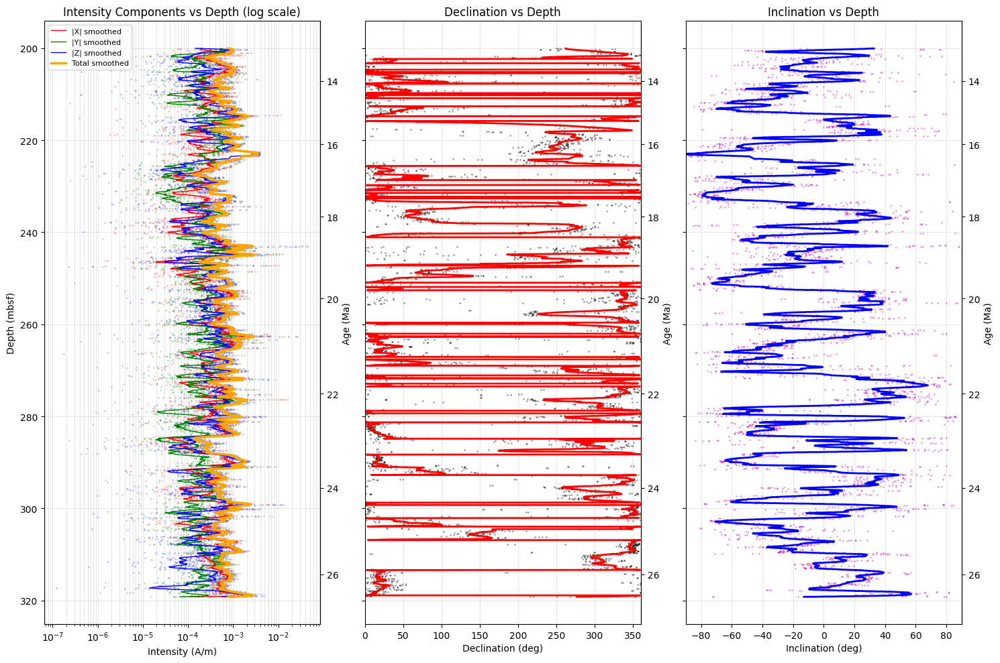

In [ ]:
from scipy.interpolate import interp1d

#
# Uses existing variables in the notebook: df_age, df_sorted (or df_filtered), depth_sorted_int,
# intensity_x_smooth, intensity_y_smooth, intensity_z_smooth, intensity_total_smooth,
# decl_smooth, incl_smooth (computed in previous cells).


# Prepare age-depth model from df_age (drop NaNs, convert types, sort by depth)
adf = df_age[['Depth (mcd)', 'Age (Ma)']].copy()
adf['Depth (mcd)'] = pd.to_numeric(adf['Depth (mcd)'], errors='coerce')
adf['Age (Ma)'] = pd.to_numeric(adf['Age (Ma)'], errors='coerce')
adf = adf.dropna().sort_values('Depth (mcd)')
depth_model = adf['Depth (mcd)'].values
age_model = adf['Age (Ma)'].values

# Build forward / inverse interpolators (allow extrapolation)
depth_to_age_fn = interp1d(depth_model, age_model, bounds_error=False, fill_value='extrapolate')
age_to_depth_fn = interp1d(age_model, depth_model, bounds_error=False, fill_value='extrapolate')

# Use the sorted depth array used for the smoothed series
# depth_sorted_int was created previously (depths for intensity smoothing)
try:
    depth_plot = depth_sorted_int
except NameError:
    depth_plot = df_filtered.sort_values('Depth(mbsf)')['Depth(mbsf)'].values

# Create figure and plots similar to earlier but with a right-hand y-axis for Age (Ma)
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True)

# Left plot: intensities (log scale) with smoothed total
ax1 = axes[0]
ax1.plot(intensity_x, depth_plot, 'r.', markersize=2, alpha=0.2)
ax1.plot(intensity_y, depth_plot, 'g.', markersize=2, alpha=0.2)
ax1.plot(intensity_z, depth_plot, 'b.', markersize=2, alpha=0.2)
ax1.plot(intensity_total, depth_plot, 'gray', marker='.', markersize=2, alpha=0.2, linestyle='none')

ax1.plot(intensity_x_smooth, depth_plot, 'r-', linewidth=1, label='|X| smoothed')
ax1.plot(intensity_y_smooth, depth_plot, 'g-', linewidth=1, label='|Y| smoothed')
ax1.plot(intensity_z_smooth, depth_plot, 'b-', linewidth=1, label='|Z| smoothed')
ax1.plot(intensity_total_smooth, depth_plot, 'orange', linewidth=2.5, label='Total smoothed')

ax1.set_xlabel('Intensity (A/m)')
ax1.set_ylabel('Depth (mbsf)')
ax1.set_title('Intensity Components vs Depth (log scale)')
ax1.set_xscale('log')
ax1.grid(True, which='both', alpha=0.3)
ax1.invert_yaxis()
ax1.legend(fontsize=8)

# add secondary y-axis showing Age (Ma)
sec1 = ax1.secondary_yaxis('right', functions=(lambda d: depth_to_age_fn(d), lambda a: age_to_depth_fn(a)))
sec1.set_ylabel('Age (Ma)')
sec1.yaxis.set_tick_params(rotation=0)

# Middle plot: Declination with smoothed curve
ax2 = axes[1]
ax2.plot(df_sorted['Decl(deg)'].values, depth_plot, 'k.', markersize=2, alpha=0.3, label='Data')
ax2.plot(decl_smooth, depth_plot, 'r-', linewidth=2, label='Smoothed')
ax2.set_xlabel('Declination (deg)')
ax2.set_title('Declination vs Depth')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 360)
ax2.invert_yaxis()

sec2 = ax2.secondary_yaxis('right', functions=(lambda d: depth_to_age_fn(d), lambda a: age_to_depth_fn(a)))
sec2.set_ylabel('Age (Ma)')

# Right plot: Inclination with smoothed curve
ax3 = axes[2]
ax3.plot(incl_sorted, depth_plot, 'm.', markersize=2, alpha=0.3, label='Data')
ax3.plot(incl_smooth, depth_plot, 'b-', linewidth=2, label='Smoothed')
ax3.set_xlabel('Inclination (deg)')
ax3.set_title('Inclination vs Depth')
ax3.grid(True, alpha=0.3)
ax3.set_xlim(-90, 90)
ax3.invert_yaxis()

sec3 = ax3.secondary_yaxis('right', functions=(lambda d: depth_to_age_fn(d), lambda a: age_to_depth_fn(a)))
sec3.set_ylabel('Age (Ma)')

plt.tight_layout()
plt.show()

Above selected range of 200 - 320 mbsf is based on below figures:

Figure F11. Core recovery, lithostratigraphy, epoch, magnetic susceptibility, natural gamma radiation (Hole 1237B only), gamma ray attenuation (GRA) and moisture and density (MAD; dots), bulk density (Hole 1237B only), grain density, L*, and calcium carbonate and total organic carbon (TOC) (Hole 1237B only) of recovered sediments from Site 1237. For MS, NGR, GRA, and L*, gray curves represent the original measured data and black curves indicate a 50-point running average of the original data. Interpolated bulk densities from MAD measurements are provided between ~170 and 240 mcd on the GRA density curve. Dashed lines across the a*, b*, and L* profiles indicate boundaries between three color populations shown in Fig. F13. At right, CaCO3 is the black line and TOC is the gray line. Lines = GRA density, dots = MAD density.

Lets plots depths of 100 - 290 mbsf as they are exactly miocene

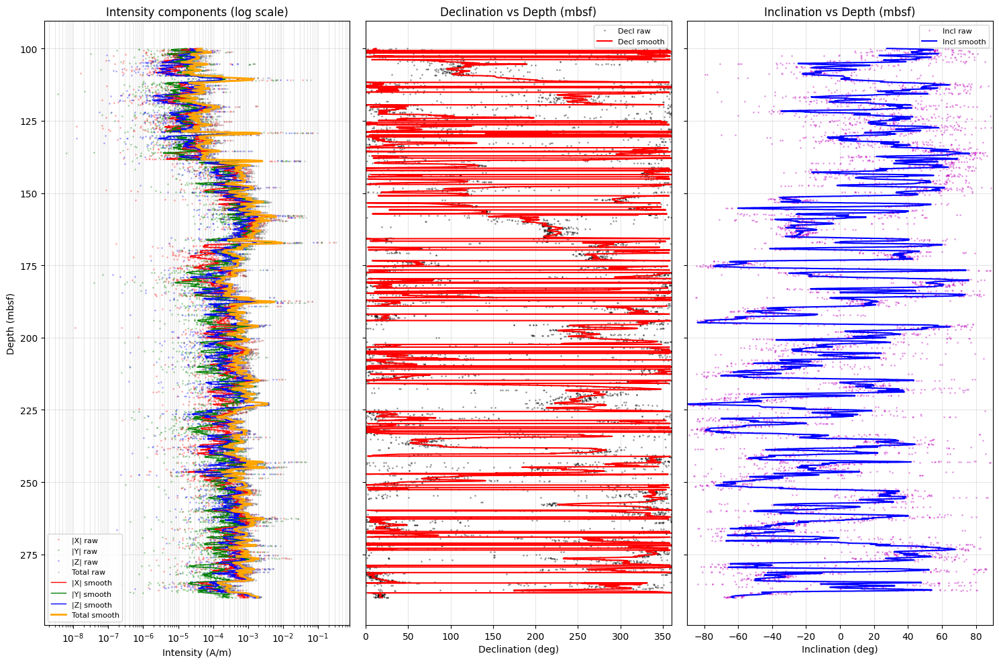

Plotted 7399 records from: /Users/nicolasanderson/Documents/GitHub/Peru/ODP_202_1237_100_290_mag_data.csv (smoothing wl=51)


In [33]:
# updated cell (index 36) - map actual column names and smooth & plot
path_new = '/Users/nicolasanderson/Documents/GitHub/Peru/ODP_202_1237_100_290_mag_data.csv'

# read CSV
df2 = pd.read_csv(path_new)

# explicit column name mapping (use exactly the names you provided)
depth_col = 'Depth (mbsf)'
demag_type_col = 'Level   Demag Type'   # was Demag_Type
demag_level_col = 'Level'               # was Demag_Level(mT)
x_col = 'Intensity X'
y_col = 'Intensity Y'
z_col = 'Intensity Z'
decl_col = 'Decl.'
incl_col = 'Incl.'
intensity_col = 'Intensity'
hole_incl_col = 'Hole Incl.'

# basic checks
for c in (depth_col, x_col, y_col, z_col, decl_col, incl_col):
    if c not in df2.columns:
        raise KeyError(f"Required column '{c}' not found in CSV. Columns available: {list(df2.columns)}")

# optionally filter out demagnetization level == 0 if column exists
if demag_level_col in df2.columns:
    df2 = df2[df2[demag_level_col] != 0].copy()

# sort by depth
df2_sorted = df2.sort_values(depth_col).reset_index(drop=True)
depth = df2_sorted[depth_col].values

# intensity components and total
ix = df2_sorted[x_col].values
iy = df2_sorted[y_col].values
iz = df2_sorted[z_col].values
int_total = np.sqrt(ix**2 + iy**2 + iz**2)
int_x = np.abs(ix)
int_y = np.abs(iy)
int_z = np.abs(iz)

n = len(depth)
# choose window length: odd and <= n, at least 5 (reuse existing window_length if present)
wl = min(51, n if n % 2 == 1 else (n - 1))
if wl < 5:
    wl = 5
if wl > n:
    wl = n if n % 2 == 1 else max(1, n - 1)
do_smooth = wl >= 3

# smooth intensities on log scale (protect zeros)
eps = 1e-12
if do_smooth:
    int_x_s = np.exp(savgol_filter(np.log(int_x + eps), wl, 3))
    int_y_s = np.exp(savgol_filter(np.log(int_y + eps), wl, 3))
    int_z_s = np.exp(savgol_filter(np.log(int_z + eps), wl, 3))
    int_total_s = np.exp(savgol_filter(np.log(int_total + eps), wl, 3))
else:
    int_x_s, int_y_s, int_z_s, int_total_s = int_x, int_y, int_z, int_total

# declination smoothing (handle circularity)
decl = df2_sorted[decl_col].values
decl_rad = np.deg2rad(decl)
decl_sin = np.sin(decl_rad)
decl_cos = np.cos(decl_rad)
if do_smooth:
    wl_decl = wl if wl >= 5 else (5 if n >= 5 else (n if n%2==1 else n-1))
    decl_sin_s = savgol_filter(decl_sin, wl_decl, 3)
    decl_cos_s = savgol_filter(decl_cos, wl_decl, 3)
    decl_smooth = (np.rad2deg(np.arctan2(decl_sin_s, decl_cos_s)) % 360)
else:
    decl_smooth = decl

# inclination smoothing (linear)
incl = df2_sorted[incl_col].values
if do_smooth:
    incl_smooth = savgol_filter(incl, wl, 3)
else:
    incl_smooth = incl

# plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 10), sharey=True)

# Intensity (log scale) - raw points + smoothed curves
ax1 = axes[0]
ax1.plot(int_x, depth, '.', color='r', markersize=2, alpha=0.25, label='|X| raw')
ax1.plot(int_y, depth, '.', color='g', markersize=2, alpha=0.25, label='|Y| raw')
ax1.plot(int_z, depth, '.', color='b', markersize=2, alpha=0.25, label='|Z| raw')
ax1.plot(int_total, depth, '.', color='gray', markersize=2, alpha=0.25, label='Total raw')
ax1.plot(int_x_s, depth, '-', color='r', linewidth=1.0, label='|X| smooth')
ax1.plot(int_y_s, depth, '-', color='g', linewidth=1.0, label='|Y| smooth')
ax1.plot(int_z_s, depth, '-', color='b', linewidth=1.0, label='|Z| smooth')
ax1.plot(int_total_s, depth, '-', color='orange', linewidth=2.0, label='Total smooth')
ax1.set_xscale('log')
ax1.set_xlabel('Intensity (A/m)')
ax1.set_ylabel(depth_col)
ax1.set_title('Intensity components (log scale)')
ax1.grid(True, which='both', alpha=0.3)
ax1.invert_yaxis()
ax1.legend(fontsize=8)

# Declination
ax2 = axes[1]
ax2.plot(decl, depth, 'k.', markersize=2, alpha=0.3, label='Decl raw')
ax2.plot(decl_smooth, depth, 'r-', linewidth=1.5, label='Decl smooth')
ax2.set_xlabel('Declination (deg)')
ax2.set_xlim(0, 360)
ax2.set_title('Declination vs ' + depth_col)
ax2.grid(True, alpha=0.3)
ax2.invert_yaxis()
ax2.legend(fontsize=8)

# Inclination
ax3 = axes[2]
ax3.plot(incl, depth, 'm.', markersize=2, alpha=0.3, label='Incl raw')
ax3.plot(incl_smooth, depth, 'b-', linewidth=1.5, label='Incl smooth')
ax3.set_xlabel('Inclination (deg)')
ax3.set_xlim(-90, 90)
ax3.set_title('Inclination vs ' + depth_col)
ax3.grid(True, alpha=0.3)
ax3.invert_yaxis()
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()
print(f"Plotted {n} records from: {path_new} (smoothing wl={wl if do_smooth else 'none'})")


Figure F12. Major components observed in smear slides. Solid circles = dominant lithologies, open squares = minor lithologies.

Figure F14. Ash layers from Site 1237. The figure shows (from left) the cumulative number of ash layers and layer thickness, volcanic glass size, the presence of pyroxenes, the presence of amphiboles, and the abundance of biotite. Opx = orthopyroxene, cpx = clinopyroxene.

Figure F27. Site 1237 natural remanent magnetization (NRM) intensity before and after AF demagnetization at peak fields of 25 mT vs. depth. Core recovery is shown for reference.

Figure F31. Inclination after demagnetization at peak alternating fields of 25 mT for the 200- to 300-mcd interval of (A) Hole 1237B, (B) Hole 1237C, (C) Hole 1237D, and (D) the stacked and smoothed record with the accompanying polarity interpretations.

Figure F32. Inclination after demagnetization at peak alternating fields of 25 mT for the 300- to 360-mcd interval of (A) Hole 1237B, (B) Hole 1237C, and (C) the stacked and smoothed record with the accompanying polarity interpretations.


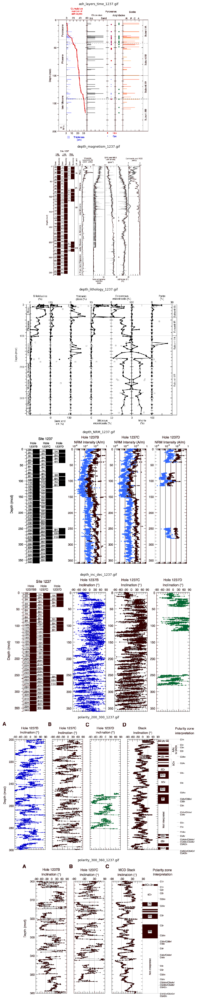

In [24]:
# define image paths and plot them in a grid without distortion
paths = [
    '/Users/nicolasanderson/Documents/GitHub/Peru/ash_layers_time_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_magnetism_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_lithology_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_NRM_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/depth_inc_dec_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/polarity_200_300_1237.gif',
    '/Users/nicolasanderson/Documents/GitHub/Peru/polarity_300_360_1237.gif',
]

# load images (use existing plt.imread if available)
imgs = []
titles = []
for p in paths:
    try:
        im = plt.imread(p)
    except Exception:
        # fallback: white placeholder if file not found/readable
        im = np.ones((200, 200, 3), dtype=np.uint8) * 255
    imgs.append(im)
    titles.append(p.split('/')[-1])

# create a 3x3 grid (7 images -> last two axes left blank)
ncols = 1
nrows = 7
fig, axes = plt.subplots(nrows, ncols, figsize=(24, 40))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(imgs):
        ax.imshow(imgs[i], interpolation='nearest', aspect='equal')
        ax.set_title(titles[i], fontsize=9)
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

In [29]:
from IPython.display import display

# display Excel starting from row 15 (Excel row numbers are 1-based)
path = '/Users/nicolasanderson/Documents/GitHub/Peru/age_depth_model_1237.xlsx'

# inspect sheets
xls = pd.ExcelFile(path)
print("Sheets:", xls.sheet_names)

# read first sheet (adjust sheet_name if needed)
df_age = pd.read_excel(path, sheet_name=0, header=1)

# select rows starting from Excel row 15 (iloc index 14)
df_view = df_age.iloc[13:].copy()

# drop columns that contain any NA values
#df_view = df_view.dropna(axis=1, how='any')

# adjust the index to reflect Excel row numbers (optional)
df_view.index = df_view.index + 1

# display the result
display(df_view)

Sheets: ['Sheet1']


,Age (Ma),Depth (mcd),LSR (mcd/m.y.),mcd growth factor,Corrected LSR (m/m.y.),Dry density (g/cm3),CaCO3 average concentration (wt%),TOC average concentration (wt%),Opal average concentration (wt%),Total MAR (g/cm2/k.y.),CaCO3 MAR (g/cm2/k.y.),TOC MAR (g/cm2/k.y.),Opal MAR (g/cm2/k.y.),Noncarbonate MAR (g/cm2/k.y.)
14,14,207.1,6.2,1.13,5.5,1.15,95.3,NaN,NaN,0.63,0.60,NaN,NaN,0.03
15,15,213.7,6.6,1.13,5.9,1.14,95.9,NaN,NaN,0.67,0.64,NaN,NaN,0.03
16,16,220.9,7.2,1.13,6.4,1.14,95.4,NaN,NaN,0.73,0.70,NaN,NaN,0.03
17,17,228.6,7.6,1.13,6.8,1.22,95.6,NaN,NaN,0.83,0.79,NaN,NaN,0.04
18,18,236.6,8.0,1.13,7.1,1.19,95.0,NaN,NaN,0.85,0.80,NaN,NaN,0.04
19,19,245.1,8.5,1.13,7.5,1.20,96.1,NaN,NaN,0.90,0.87,NaN,NaN,0.04
20,20,254.4,9.3,1.13,8.2,1.26,96.8,NaN,NaN,1.04,1.01,NaN,NaN,0.03
21,21,264.6,10.2,1.13,9.0,1.23,96.4,NaN,NaN,1.11,1.07,NaN,NaN,0.04
22,22,275.1,10.5,1.20,8.8,1.26,96.6,NaN,NaN,1.11,1.07,NaN,NaN,0.04
23,23,285.5,10.4,1.20,8.7,1.25,95.8,NaN,NaN,1.08,1.04,NaN,NaN,0.05


In [53]:
x=3.5*9.7
x/2

16.974999999999998

## CT Scan Data

In [63]:
pip install pylibjpeg pylibjpeg-openjpeg

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 432 kB 3.7 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install pydicom numpy Pillow tifffile

SyntaxError: invalid syntax (2686147863.py, line 1)

In [55]:
INPUT_FOLDERS = [
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE1",   # your 39-file folder
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE2",   # your 43-file folder
]
OUTPUT_BASE = r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/Output"

In [64]:
"""
DICOM to TIFF Converter for Sediment Core CT Scans
====================================================
Converts DICOM files from one or more folders to TIFF images.

Usage:
    python dicom_to_tiff.py

Requirements:
    pip install pydicom pylibjpeg pylibjpeg-openjpeg numpy Pillow tifffile

Quality fixes applied
─────────────────────
1. Toshiba HU offset  — This Toshiba Aquilion stores pixels as (HU + 32768) but
   incorrectly sets RescaleIntercept=0 rather than -32768. We auto-detect this
   condition (median stored value > 30000 with Intercept=0) and subtract 32768
   so every pixel is a true Hounsfield Unit value (-1024 to ~3000 HU).

2. 16-bit saved as int16 HU — The old script stretched data across 0-65535,
   adding false precision and distorting inter-pixel spacing. Now the 16-bit
   TIFF stores true HU values as int16. Pixel value == Hounsfield Unit.
   Directly readable as calibrated data in ImageJ/FIJI/MATLAB/Python.

3. Correct 8-bit windowing — DICOM WindowCenter/Width were being applied to
   uncorrected (30000+) values, clipping 100% of pixels to white. The 8-bit
   TIFFs now window the corrected HU values. Default window (centre 500 HU,
   width 3000 HU) covers the full sediment-core range: air (-1000) through
   dense carbonate/silica (~2000 HU). Adjust WINDOW_CENTER/WIDTH below.

4. JPEG2000 lossless decompression — Transfer syntax 1.2.840.10008.1.2.4.90
   decoded via pylibjpeg-openjpeg. Pixel-perfect, no quality loss.
"""

import sys
import numpy as np
from pathlib import Path

# dependency check
try:
    import pydicom
except ImportError:
    sys.exit("Missing: pip install pydicom")
try:
    import tifffile
except ImportError:
    sys.exit("Missing: pip install tifffile")
try:
    from PIL import Image
except ImportError:
    sys.exit("Missing: pip install Pillow")
try:
    import pylibjpeg   # noqa
    import openjpeg    # noqa
except ImportError:
    sys.exit(
        "Missing JPEG2000 decoder.\n"
        "Run:  pip install pylibjpeg pylibjpeg-openjpeg"
    )


# ==============================================================================
# CONFIGURATION — edit these before running
# ==============================================================================

INPUT_FOLDERS = [
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE1",    # <- your first folder  (SE1, 39 files)
    r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/SE2",    # <- your second folder (SE2, 43 files)
]

OUTPUT_BASE = r"/Users/nicolasanderson/Documents/GitHub/Peru/CT/Output"   # <- output directory (sub-folders auto-created)
# 16-bit TIFF: pixel value == true Hounsfield Unit (int16). Best for analysis.
SAVE_16BIT = True

# 8-bit TIFF: windowed for visual inspection / quick checks.
SAVE_8BIT = True

# Also write one multi-page stack TIFF per folder (convenient for FIJI/ImageJ).
SAVE_STACK = True

# 8-bit window — covers air (-1000 HU) through dense sediment (~2000 HU).
# Tighten the window to increase contrast in the sediment range you care about.
# Set both to None to auto-stretch each slice to its own p1-p99 range instead.
WINDOW_CENTER = 500    # HU
WINDOW_WIDTH  = 3000   # HU  -> range: -1000 to 2000 HU

# ==============================================================================


_TOSHIBA_OFFSET = 32768


def _needs_toshiba_fix(ds, arr: np.ndarray) -> bool:
    """
    Detect the Toshiba offset bug: scanner adds 32768 to every HU value but
    sets RescaleIntercept=0 instead of -32768.
    Heuristic: median stored value > 30000 AND RescaleIntercept == 0.
    """
    if float(getattr(ds, "RescaleIntercept", 0)) != 0.0:
        return False
    return float(np.median(arr)) > 30_000


def dicom_to_hu(ds) -> np.ndarray:
    """
    Return float32 array of true Hounsfield Unit values.
    Applies RescaleSlope/Intercept and the Toshiba offset if detected.
    """
    if getattr(ds, "PixelRepresentation", None) == 1:
        ds.PixelRepresentation = 0
    raw = ds.pixel_array.astype(np.float32)
    slope     = float(getattr(ds, "RescaleSlope",     1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    arr = raw * slope + intercept
    if _needs_toshiba_fix(ds, arr):
        arr -= _TOSHIBA_OFFSET
    return arr


def hu_to_int16(arr: np.ndarray) -> np.ndarray:
    """
    Clip to int16 range and store. Pixel value == Hounsfield Unit.
    No rescaling — true physical values preserved.
    """
    return np.clip(arr, -32768, 32767).astype(np.int16)


def hu_to_uint8(arr: np.ndarray, center=None, width=None) -> np.ndarray:
    """
    Window HU array to uint8. Values outside the window clip to 0/255.
    If center/width are None, auto-stretches the p1-p99 percentile range.
    """
    if center is not None and width is not None:
        lo, hi = center - width / 2.0, center + width / 2.0
    else:
        lo, hi = float(np.percentile(arr, 1)), float(np.percentile(arr, 99))
    if hi <= lo:
        return np.zeros(arr.shape, dtype=np.uint8)
    return np.clip((arr - lo) / (hi - lo) * 255.0, 0, 255).astype(np.uint8)


def load_dicom_series(folder: str) -> list:
    folder = Path(folder)
    dcm_files = []
    for f in sorted(folder.iterdir()):
        if not f.is_file():
            continue
        try:
            ds = pydicom.dcmread(str(f), force=True)
            if getattr(ds, "PixelRepresentation", None) == 1:
                ds.PixelRepresentation = 0
            _ = ds.pixel_array
            dcm_files.append((f, ds))
        except AttributeError:
            print(f"  [skip] {f.name} - no pixel data")
        except Exception as e:
            print(f"  [skip] {f.name} - {e}")
    if not dcm_files:
        raise RuntimeError(f"No readable DICOM files in: {folder}")

    def sort_key(item):
        _, ds = item
        try:
            return int(ds.InstanceNumber)
        except Exception:
            pass
        try:
            return float(ds.ImagePositionPatient[2])
        except Exception:
            pass
        return 0

    dcm_files.sort(key=sort_key)
    print(f"  Found {len(dcm_files)} DICOM slices")
    return dcm_files


def print_metadata(ds, filename: str, hu_arr: np.ndarray):
    def g(tag, default="--"):
        return getattr(ds, tag, default)
    raw = hu_arr + (_TOSHIBA_OFFSET if _needs_toshiba_fix(ds, hu_arr + _TOSHIBA_OFFSET) else 0)
    toshiba = _needs_toshiba_fix(ds, raw)
    ts = getattr(getattr(ds, "file_meta", None), "TransferSyntaxUID", "--")
    print(f"    File            : {filename}")
    print(f"    Modality        : {g('Modality')}")
    print(f"    Size            : {g('Columns')} x {g('Rows')} px  |  {g('BitsStored')}-bit")
    print(f"    Pixel spacing   : {g('PixelSpacing')} mm  |  Thickness: {g('SliceThickness')} mm")
    print(f"    KVP / Kernel    : {g('KVP')} kV  /  {g('ConvolutionKernel')}")
    print(f"    Transfer syntax : {ts}")
    print(f"    Toshiba offset  : {'corrected (-32768 applied)' if toshiba else 'not needed'}")
    print(f"    HU range        : {hu_arr.min():.0f} to {hu_arr.max():.0f}")
    print(f"    Series          : {g('SeriesDescription')}")
    print()


def convert_folder(input_folder: str, output_folder: str):
    input_path  = Path(input_folder)
    output_path = Path(output_folder)
    output_path.mkdir(parents=True, exist_ok=True)

    print(f"\n{'='*60}")
    print(f"Input  : {input_path}")
    print(f"Output : {output_path}")
    print(f"{'='*60}")

    dcm_files = load_dicom_series(input_folder)

    first_file, first_ds = dcm_files[0]
    first_hu = dicom_to_hu(first_ds)
    print("\n  -- Metadata (first slice) --")
    print_metadata(first_ds, first_file.name, first_hu)

    shape_groups = {}

    for i, (fpath, ds) in enumerate(dcm_files):
        stem  = f"{i+1:04d}_{fpath.stem}"
        hu    = dicom_to_hu(ds)
        shape = hu.shape

        arr16 = hu_to_int16(hu)
        arr8  = hu_to_uint8(hu, WINDOW_CENTER, WINDOW_WIDTH)

        if SAVE_16BIT:
            tifffile.imwrite(
                str(output_path / f"{stem}_16bit.tif"),
                arr16,
                photometric="minisblack",
            )
        if SAVE_8BIT:
            Image.fromarray(arr8).save(
                str(output_path / f"{stem}_8bit.tif")
            )

        shape_groups.setdefault(shape, []).append((stem, arr16, arr8))
        print(
            f"  [{i+1:3d}/{len(dcm_files)}] {fpath.name}"
            f"  ->  {stem}  {shape[1]}x{shape[0]}",
            end="\r",
        )

    print()

    if len(shape_groups) > 1:
        print(f"\n  WARNING: Multiple image shapes detected:")
        for sh, items in sorted(shape_groups.items(), key=lambda x: -len(x[1])):
            names = ", ".join(s for s, *_ in items[:4])
            if len(items) > 4:
                names += "..."
            print(f"     {sh[1]}x{sh[0]} px -- {len(items)} slice(s): {names}")
        main_shape = max(shape_groups, key=lambda s: len(shape_groups[s]))
        print(
            f"  -> Stack uses the {len(shape_groups[main_shape])}-slice "
            f"{main_shape[1]}x{main_shape[0]} group (main CT series).\n"
        )
    else:
        main_shape = next(iter(shape_groups))

    if SAVE_STACK:
        main = shape_groups[main_shape]
        if SAVE_16BIT:
            sp = output_path / "stack_16bit.tif"
            tifffile.imwrite(
                str(sp),
                np.stack([a16 for _, a16, _ in main], axis=0),
                photometric="minisblack",
            )
            print(f"  OK  16-bit stack -> {sp.name}  ({len(main)} slices, int16, pixel = HU)")
        if SAVE_8BIT:
            sp = output_path / "stack_8bit.tif"
            tifffile.imwrite(
                str(sp),
                np.stack([a8 for _, _, a8 in main], axis=0),
                photometric="minisblack",
            )
            print(
                f"  OK  8-bit  stack -> {sp.name}  ({len(main)} slices, "
                f"window centre={WINDOW_CENTER} width={WINDOW_WIDTH} HU)"
            )

    print(f"\n  Done -- {len(dcm_files)} slices -> {output_path}\n")


def main():
    for i, folder in enumerate(INPUT_FOLDERS):
        out = Path(OUTPUT_BASE) / (Path(folder).name or f"series_{i+1}")
        try:
            convert_folder(folder, str(out))
        except Exception as e:
            print(f"\n[ERROR] {folder}: {e}\n")
    print("All done!")


if __name__ == "__main__":
    main()


Input  : /Users/nicolasanderson/Documents/GitHub/Peru/CT/SE1
Output : /Users/nicolasanderson/Documents/GitHub/Peru/CT/Output/SE1
  Found 39 DICOM slices

  -- Metadata (first slice) --
    File            : IM1
    Modality        : CT
    Size            : 512 x 512 px  |  8-bit
    Pixel spacing   : -- mm  |  Thickness: -- mm
    KVP / Kernel    : -- kV  /  FC30
    Transfer syntax : 1.2.840.10008.1.2.4.90
    Toshiba offset  : corrected (-32768 applied)
    HU range        : 0 to 255
    Series          : Bone 2.0 Coron TOP.Ref

  [ 39/39] IM39  ->  0039_IM39  1624x1624

     1624x1624 px -- 38 slice(s): 0002_IM2, 0003_IM3, 0004_IM4, 0005_IM5...
     512x512 px -- 1 slice(s): 0001_IM1
  -> Stack uses the 38-slice 1624x1624 group (main CT series).

  OK  16-bit stack -> stack_16bit.tif  (38 slices, int16, pixel = HU)
  OK  8-bit  stack -> stack_8bit.tif  (38 slices, window centre=500 width=3000 HU)

  Done -- 39 slices -> /Users/nicolasanderson/Documents/GitHub/Peru/CT/Output/SE1


